# Modelado Estadístico Inferencial y Predictivo de Material Particulado ($MP_{10}$ y $PM_{2.5}$) en la Estación Kingston College
## Avance 2: Modelamiento Estadístico, Inferencia y Diagnóstico de Supuestos

* **Universidad:** Universidad del Desarrollo — Facultad de Ingeniería
* **Curso:** Análisis de Datos e Inferencia Estadística
* **Profesor Guía:** Danilo Gómez Correa
* **Integrantes:** Javier Benavides Ortega, Cristóbal Montoya Toledo
* **Fecha de Entrega:** 2 de Noviembre de 2026
* **Ubicación:** Concepción, Región del Biobío, Chile

---

## Índice General
1. **Pregunta de Investigación e Hipótesis**
   - 1.1 Contextualización del Problema
   - 1.2 Pregunta de Investigación
   - 1.3 Formulación de Hipótesis, Errores Tipo I ($\alpha$) y Tipo II ($\beta$), y Criterio del Valor-$p$
2. **Revisión de Literatura**
   - 2.1 Síntesis Crítica y Artículos de Referencia
   - 2.2 Identificación del Vacío de Conocimiento (Gap)
3. **Metodología y Las 5 Etapas del EDA**
   - 3.1 Tipo de Análisis y Fuente de Datos (16 Datasets SINCA = $893.398$ filas)
   - 3.2 **Etapa 1 del EDA:** Análisis Descriptivo Individual ($\bar{z}, z_m, Q_1, Q_3, IQR, s, CV, k_s$) y Tabla de Frecuencias con **Regla de Sturges**
   - 3.3 **Etapa 2 del EDA:** Taxonomía y Ajuste de Variables
   - 3.4 **Etapa 3 del EDA:** Identificación y Tratamiento de Datos Nulos (Mecanismos MCAR, MAR, MNAR)
   - 3.5 **Etapa 4 del EDA:** Detección de Datos Atípicos ($RIC$, *Z-score*, **Test de Grubbs**), Medidas Robustas ($\text{MAD}$) y **Winsorización** (Comparación Antes vs. Después)
   - 3.6 **Codificación Formal de Variables Categóricas (Variables Dummy) y Justificación Técnica de Decisiones**
4. **Diagrama Metodológico**
5. **Etapa 5 del EDA: Análisis de Relaciones entre Variables y Modelos Lineales**
   - 5.1 **Pruebas de Bondad de Ajuste** : Kolmogórov-Smirnov ($D, D^+, D^-, D_{\alpha}$), Anderson-Darling ($A^2$) y Shapiro-Wilk ($W$)
   - 5.2 **Relación Numérica vs. Numérica y Regresión Lineal Simple/Múltiple** : Covarianza ($C_{xy}$), Pearson ($r$ y prueba $t$), Spearman ($r_s$), Kendall ($\tau$), Estimador EMCO ($\hat{\beta} = (X^T X)^{-1} X^T Y$), Verificación de Propiedades y 6 Supuestos de Gauss-Markov, Tabla ANOVA de la Regresión ($SSR, SSE, SST, F_c$), $R^2$ y $R_a^2$, e Inferencia / Intervalos de Confianza de $\beta_j$
   - 5.3 **Relación Numérica vs. Categórica** : Modelo $Y_{ij} = \mu_i + e_{ij}$, Descomposición $SCT = SC\text{Trat} + SCE$, Tabla ANOVA Completa, Magnitud de Efecto ($\eta^2$), **Procedimiento Post-Hoc de Tukey** y Prueba de Kruskal-Wallis ($H$)
   - 5.4 **Relación Categórica vs. Categórica** : Tabla de Contingencia ($O_{ij}$ vs $E_{ij}$), Prueba $\chi^2$ de Independencia y $V$ de Cramér
   - 5.5 **Tabla Resumen Oficial**
   - 5.6 **Cuadro Maestro de Todas las Hipótesis ($H_0$ y $H_1$) y Criterios Formales de Rechazo y Aceptación**
6. **Resultados, Modelamiento Estadístico y Diagnóstico de Supuestos del EMCO**
   - 6.1 Especificación Matemática de los 4 Modelos Implementados
   - 6.2 Fórmulas de Métricas de Error Predictivo, Criterios de Información y Supuestos
   - 6.3 Estimación de los 4 Modelos, Tabla Comparativa, Cambio $F$ y Diagnóstico de Supuestos
7. **Discusión, Interpretación de Hallazgos y Conclusiones**
   - 7.1 Explicación Física y Estadística de los Hallazgos y Comparación de Modelos
   - 7.2 Auditoría Crítica de los 6 Supuestos del EMCO
   - 7.3 Relación con las Hipótesis Planteadas y Coherencia con la Literatura Científica
   - 7.4 Posibles Sesgos, Limitaciones Metodológicas e Implicancias Prácticas
8. **Referencias Bibliográficas**

In [ ]:
# [Configuración Inicial / Google Colab] Descomprime automáticamente colab_pack.zip si estás en la nube:
import os, zipfile, math, statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

if not os.path.exists('Datos') and os.path.exists('colab_pack.zip'):
    with zipfile.ZipFile('colab_pack.zip', 'r') as z:
        z.extractall('.')
    print('✓ Pack descomprimido en Google Colab: carpetas Datos/ y graficos_png/ listas.')
elif os.path.exists('Datos'):
    print('✓ Carpeta Datos/ detectada correctamente.')

✓ Carpeta Datos/ detectada correctamente.


---
## 1. Pregunta de Investigación e Hipótesis

### 1.1. Contextualización del Problema
En el Gran Concepción (Región del Biobío, Chile), la concentración de material particulado atmosférico presenta incrementos críticos durante el periodo otoño-invierno. El material particulado fino ($PM_{2.5}$, partículas con diámetro aerodinámico $\le 2.5\,\mu\text{m}$) constituye una fracción interna del material particulado grueso ($MP_{10}$, $\le 10\,\mu\text{m}$), es decir, $PM_{2.5} \subseteq MP_{10}$. En centros urbanos del centro-sur del país, las fuentes de combustión residencial y vehicular emiten ambas fracciones de manera co-localizada. La estación de monitoreo continuo **Kingston College** (red SINCA) registra de manera representativa estas dinámicas. Determinar en qué medida el contaminante grueso ($MP_{10}$) permite predecir los niveles de $PM_{2.5}$ es fundamental para estimar concentraciones finas a partir de macro-mediciones y caracterizar su comportamiento estacional.

### 1.2. Pregunta de Investigación
> **¿En qué medida los niveles diarios de material particulado grueso ($MP_{10}$) predicen la concentración de material particulado fino ($PM_{2.5}$) en la estación Kingston College (Concepción) durante el período de estudio, y cómo varía esta relación según la estación del año y el tipo de día (laboral vs. fin de semana)?**

### 1.3. Formulación de Hipótesis y Criterio de Decisión

1. **Hipótesis Nula ($H_0$):** Afirmación sobre el parámetro poblacional que representa el *status quo* (ausencia de efecto):
   $$H_0: \beta_1 = 0 \quad (\text{y } \rho = 0)$$
   *(No existe relación lineal estadísticamente significativa entre $MP_{10}$ y $PM_{2.5}$).*
2. **Hipótesis Alternativa ($H_1$):** Propuesta que representa el efecto que se busca demostrar:
   $$H_1: \beta_1 \neq 0 \quad (\text{o unilateralmente } \beta_1 > 0, \, \rho > 0)$$
3. **Errores y Potencia de la Prueba:**
   * **Error Tipo I ($\alpha$):** $\alpha = \Pr(\text{rechazar } H_0 \mid H_0 \text{ verdadera})$. Se fija en $\alpha = 0.05$ ($5\%$).
   * **Error Tipo II ($\beta$):** $\beta = \Pr(\text{no rechazar } H_0 \mid H_0 \text{ falsa})$.
   * **Potencia del test ($\gamma$):** $\gamma = 1 - \beta$ (probabilidad de rechazar correctamente $H_0$ cuando es falsa).
4. **Escala de Evidencia según el Valor-$p$**
   * $(v - p) < 0.01$: Existe **evidencia muy fuerte** contra $H_0$.
   * $0.01 < (v - p) < 0.05$: Existe **evidencia fuerte** contra $H_0$.
   * $0.05 < (v - p) < 0.10$: Existe **evidencia débil** contra $H_0$.
   * $(v - p) > 0.10$: **No se rechaza $H_0$** (evidencia insuficiente contra $H_0$).

---
## 2. Revisión de Literatura

### 2.1. Síntesis Crítica y Artículos de Referencia
Para fundamentar el diseño del estudio se analizaron investigaciones recientes y reportes oficiales del monitoreo de calidad del aire en Chile (priorizando literatura entre 2019 y 2026):

1. **Cereceda-Balic et al. (2020) [1]:** Caracterizan químicamente el material particulado en el centro-sur de Chile, demostrando que durante los meses fríos el $PM_{2.5}$ representa entre el $65\%$ y $80\%$ de la masa total de $MP_{10}$ debido a la combustión de biomasa. Este antecedente aporta la base física que sustenta la magnitud de la pendiente $\beta_1 \approx 0.70$ esperada en nuestro modelo de regresión.
2. **Saide et al. (2016) [5]:** Evalúan el control meteorológico sobre los episodios de contaminación en la cuenca de Concepción, explicando cómo las inversiones térmicas de subsidencia y el estancamiento atmosférico provocan saturación de partículas independientemente del día de la semana. Esto fundamenta el resultado de independencia hallado en nuestra prueba de Chi-cuadrado.
3. **Gramsch et al. (2021) [2]:** Utilizan los confinamientos del año 2020 como experimento natural en Chile, evidenciando que la reducción del flujo vehicular laboral no disminuyó significativamente el $PM_{2.5}$ invernal en ciudades del centro-sur debido al rol dominante de la calefacción domiciliaria. Este hallazgo respalda la preponderancia del factor estacional sobre el tipo de día en nuestro análisis.
4. **Superintendencia del Medio Ambiente - SMA (2024) [6]:** Informe de evaluación técnica sobre el cumplimiento normativo en redes de calidad del aire, estableciendo protocolos de validación jerárquica de registros y tratamiento de discontinuidades instrumentales. Aporta el criterio técnico para depurar anomalías de sensores en SINCA.
5. **Instituto Nacional de Estadísticas - INE (2026) [3]:** Informe Anual de Estadísticas del Medio Ambiente 2025 (publicado en enero de 2026), que sistematiza los registros oficiales de calidad del aire a nivel nacional y clasifica formalmente la estación Kingston College dentro de la red del Biobío.
6. **Ministerio del Medio Ambiente - MMA (2019) [4]:** Plan de Prevención y Descontaminación Atmosférica (PPDA) para el Gran Concepción (D.S. N° 6/2019), el cual fija los umbrales de concentración diaria para clasificar la calidad del aire en episodios de Alerta, Preemergencia y Emergencia.

### 2.2. Identificación del Vacío de Conocimiento (Gap)
Si bien existen reportes descriptivos gubernamentales agregados por año en la región, **existe un vacío de análisis cuantitativo continuo actualizado en la estación Kingston College a nivel diario y multivariable**. Muchos estudios previos se limitaron a campañas de corta duración o al uso de datos mensuales debido a la dispersión de registros brutos. Este proyecto aborda dicho vacío procesando una base integrada de **16 datasets (8 horarios y 8 promedios mensuales/diarios)** con más de 17 años de monitoreo, aplicando rigurosamente la **Metodología de las 5 Etapas del EDA** y los modelos lineales del curso.

---
## 3. Metodología y Desarrollo de las Etapas 1 a 4 del EDA

### 3.1. Fuente de Datos, Período de Muestreo y Volumen
* **Fuente de Datos:** Registros públicos de la estación continua **Kingston College (Concepción)** del Sistema de Información Nacional de Calidad del Aire (SINCA), Ministerio del Medio Ambiente.
* **Estructura de Datasets Analizados:** El estudio recopila **16 datasets en total**:
  1. **8 datasets de resolución horaria** (*hora a hora*, totalizando $851.946$ filas para $CO$, $MP_{10}$, $PM_{2.5}$, $NO$, $NO_2$, $NO_x$, $O_3$, $SO_2$).
  2. **8 datasets de resolución diaria/mensual** agregada (totalizando $41.452$ filas de series históricas consolidadas).
  La integración global de los 16 archivos suma **$893.398$ filas** (período agosto 2009 – octubre 2026).

In [ ]:
# Auditoría de volumen de los 16 datasets en Datos/ y funciones base de lectura
import os, csv, math, statistics
from datetime import datetime
from collections import defaultdict

datos_dir = 'Datos' if os.path.isdir('Datos') else '.'
archivos_csv = sorted([f for f in os.listdir(datos_dir) if f.endswith('.csv')])

filas_horarias, filas_agregadas = 0, 0
print(f"{'Archivo CSV':<20} | {'Resolución':<16} | {'Filas de Datos':>14}")
print("-" * 56)
for fname in archivos_csv:
    with open(os.path.join(datos_dir, fname), 'r', encoding='utf-8', errors='replace') as f:
        n_rows = max(0, sum(1 for _ in f) - 1)
    if '_hora' in fname.lower():
        filas_horarias += n_rows
        tipo = 'Horaria'
    else:
        filas_agregadas += n_rows
        tipo = 'Diaria/Mensual'
    print(f"{fname:<20} | {tipo:<16} | {n_rows:>14,}")
print("-" * 56)
print(f"Sub-total series horarias  : {filas_horarias:>10,} filas")
print(f"Sub-total series agregadas : {filas_agregadas:>10,} filas")
print(f"TOTAL CONSOLIDADO (16 CSV) : {filas_horarias + filas_agregadas:>10,} filas")

Archivo CSV          | Resolución       | Filas de Datos
--------------------------------------------------------
CO.csv               | Diaria/Mensual   |          6,277
CO_hora.csv          | Horaria          |        150,671
MP10.csv             | Diaria/Mensual   |            206
MP10_hora.csv        | Horaria          |          6,275
MP2_5.csv            | Diaria/Mensual   |          6,277
MP2_5_hora.csv       | Horaria          |        150,671
NO.csv               | Diaria/Mensual   |          6,276
NO2.csv              | Diaria/Mensual   |          6,276
NO2_hora.csv         | Horaria          |        150,647
NOX.csv              | Diaria/Mensual   |          6,277
NO_hora.csv          | Horaria          |        150,647
NOx_hora.csv         | Horaria          |        150,671
O3.csv               | Diaria/Mensual   |          6,277
O3_hora.csv          | Horaria          |          6,277
SO2.csv              | Diaria/Mensual   |          3,586
SO2_hora.csv         | Horaria 

---
### 3.2. Etapa 1 del EDA: Análisis Descriptivo Individual
De acuerdo con la **Etapa 1** de las diapositivas de clases, para cada variable cuantitativa se calculan las medidas de posición, dispersión y forma usando las fórmulas exactas del curso:

* **Media aritmética ($\bar{z}$):**
  $$\bar{z} = \frac{1}{n}\sum_{i=1}^n z_i$$
* **Mediana ($z_m$) y Cuartiles ($Q_1, Q_2, Q_3$):**
  $$z_m = \begin{cases} z_l, & l = (n+1)/2 \text{ si } n \text{ impar} \\ (z_l + z_{l+1})/2, & l = n/2 \text{ si } n \text{ par} \end{cases}, \qquad IQR = RIC = Q_3 - Q_1$$
* **Varianza ($s^2$), Desviación Estándar ($s$) y Coeficiente de Variación ($CV$):**
  $$s^2 = \frac{1}{n}\sum_{i=1}^n (z_i - \bar{z})^2 \quad (\text{y muestral } \frac{1}{n-1}\sum (z_i - \bar{z})^2), \qquad s = \sqrt{s^2}, \qquad CV = \frac{s}{\bar{z}} \times 100\%$$
* **Coeficiente de Asimetría ($k_s$) y Criterio de Interpretación de Clases:**
  $$k_s = \frac{\frac{1}{n}\sum_{i=1}^n (z_i - \bar{z})^3}{s^3} \implies \begin{cases} k_s < -0.5 & \text{Sesgo negativo (cola a la izquierda)} \\ -0.5 \le k_s \le 0.5 & \text{Aproximadamente simétrica} \\ k_s > 0.5 & \text{Sesgo positivo (cola a la derecha)} \end{cases}$$
* **Tabla de Frecuencias para Variables Continuas (Regla de Sturges, diapositiva 12):**
  $$\text{long. int.} = \frac{\text{rango}(R)}{1 + 3.322 \log_{10}(n)}$$
  reportando frecuencia absoluta ($f_i$), frecuencia acumulada ($F_i$), frecuencia relativa ($h_i$) y frecuencia relativa acumulada ($H_i$).

In [ ]:
def parse_val(s):
    if not s or not s.strip():
        return None
    try:
        return float(s.strip().replace(',', '.'))
    except ValueError:
        return None

def load_csv_data(filepath):
    records = []
    with open(filepath, 'r', encoding='utf-8', errors='replace') as f:
        reader = csv.reader(f, delimiter=';')
        _ = next(reader, None)
        for r in reader:
            if not r or not r[0].strip():
                continue
            date_str = r[0].strip().zfill(6)
            time_str = r[1].strip().zfill(4) if len(r) > 1 else '0000'
            try:
                dt = datetime.strptime(date_str, '%y%m%d')
            except ValueError:
                continue
            v_val = parse_val(r[2]) if len(r) > 2 else None
            v_pre = parse_val(r[3]) if len(r) > 3 else None
            v_nov = parse_val(r[4]) if len(r) > 4 else None
            val = v_val if v_val is not None else (v_pre if v_pre is not None else v_nov)
            status = 'Validado' if v_val is not None else ('Preliminar' if v_pre is not None else ('No validado' if v_nov is not None else 'Nulo'))
            records.append({
                'fecha': dt, 'fecha_str': dt.strftime('%Y-%m-%d'),
                'year': dt.year, 'month': dt.month, 'hora': time_str,
                'valor': val, 'estado': status,
                'is_reliable': status in ('Validado', 'Preliminar')
            })
    return records

mp10_records = load_csv_data(os.path.join(datos_dir, 'MP10_hora.csv'))
mp25_records = load_csv_data(os.path.join(datos_dir, 'MP2_5.csv'))
no2_records  = load_csv_data(os.path.join(datos_dir, 'NO2.csv'))
co_records   = load_csv_data(os.path.join(datos_dir, 'CO.csv'))
o3_records   = load_csv_data(os.path.join(datos_dir, 'O3.csv'))

mp10_reliable_vals = [r['valor'] for r in mp10_records if r['valor'] is not None and r['is_reliable']]
mp25_reliable_recs = [r for r in mp25_records if r['valor'] is not None and r['is_reliable']]
mp25_reliable_vals = [r['valor'] for r in mp25_reliable_recs]

def calc_etapa1(z):
    n = len(z)
    zs = sorted(z)
    z_min, z_max = zs[0], zs[-1]
    q1 = zs[int(n * 0.25)]
    zm = statistics.median(zs)
    zbar = statistics.mean(zs)
    q3 = zs[int(n * 0.75)]
    iqr = q3 - q1
    s2 = sum((zi - zbar) ** 2 for zi in zs) / n
    s_pop = math.sqrt(s2)
    s_muestral = statistics.stdev(zs)
    cv = (s_muestral / zbar) * 100.0
    ks = (sum((zi - zbar) ** 3 for zi in zs) / n) / (s_muestral ** 3)
    return n, z_min, q1, zm, zbar, q3, iqr, z_max, s_muestral, cv, ks

m10_st = calc_etapa1(mp10_reliable_vals)
m25_st = calc_etapa1(mp25_reliable_vals)

filas_resumen = [
    ("Número de observaciones", "n", f"{m10_st[0]:,}", f"{m25_st[0]:,}"),
    ("Valor mínimo", "Mín.", f"{m10_st[1]:.2f}", f"{m25_st[1]:.2f}"),
    ("Primer cuartil", "Q1", f"{m10_st[2]:.2f}", f"{m25_st[2]:.2f}"),
    ("Mediana", "zm", f"{m10_st[3]:.2f}", f"{m25_st[3]:.2f}"),
    ("Media aritmética", "z̄", f"{m10_st[4]:.2f}", f"{m25_st[4]:.2f}"),
    ("Tercer cuartil", "Q3", f"{m10_st[5]:.2f}", f"{m25_st[5]:.2f}"),
    ("Rango intercuartílico", "IQR / RIC", f"{m10_st[6]:.2f}", f"{m25_st[6]:.2f}"),
    ("Valor máximo", "Máx.", f"{m10_st[7]:.2f}", f"{m25_st[7]:.2f}"),
    ("Desviación estándar", "s", f"{m10_st[8]:.2f}", f"{m25_st[8]:.2f}"),
    ("Coeficiente de variación", "CV = s/z̄", f"{m10_st[9]:.2f}%", f"{m25_st[9]:.2f}%"),
    ("Coeficiente de asimetría", "ks", f"{m10_st[10]:+.2f} (Sesgo +)", f"{m25_st[10]:+.2f} (Sesgo +)")
]

print("=== TABLA RESUMEN ETAPA 1 (Formato PPT EDA_5_Etapas, Diapositiva 18) ===")
print(f"{'Medida':<26} | {'Símbolo':<10} | {'MP10 (ug/m3)':>15} | {'PM2.5 (ug/m3)':>15}")
print("-" * 75)
for med, simb, v10, v25 in filas_resumen:
    print(f"{med:<26} | {simb:<10} | {v10:>15} | {v25:>15}")

# Tabla de Frecuencias con Regla de Sturges para PM2.5
n_25 = len(mp25_reliable_vals)
rango_25 = max(mp25_reliable_vals) - min(mp25_reliable_vals)
k_sturges = round(1 + 3.322 * math.log10(n_25))
long_int = rango_25 / (1 + 3.322 * math.log10(n_25))

print(f"\n=== TABLA DE FRECUENCIAS PM2.5 — REGLA DE STURGES (R = {rango_25:.1f}, k = {k_sturges} intervalos, long. int. = {long_int:.2f}) ===")
print(f"{'Intervalo (ug/m3)':<20} | {'fi':>6} | {'Fi':>6} | {'hi (%)':>9} | {'Hi (%)':>9}")
print("-" * 60)
min_v = min(mp25_reliable_vals)
F_acum = 0
for idx in range(k_sturges):
    li = min_v + idx * long_int
    ls = min_v + (idx + 1) * long_int if idx < k_sturges - 1 else max(mp25_reliable_vals) + 1e-9
    fi = sum(1 for v in mp25_reliable_vals if (li <= v < ls if idx < k_sturges - 1 else li <= v <= ls))
    F_acum += fi
    hi = (fi / n_25) * 100.0
    Hi = (F_acum / n_25) * 100.0
    etiqueta = f"[{li:5.1f} - {ls:5.1f})" if idx < k_sturges - 1 else f"[{li:5.1f} - {max(mp25_reliable_vals):5.1f}]"
    print(f"{etiqueta:<20} | {fi:>6} | {F_acum:>6} | {hi:>8.2f}% | {Hi:>8.2f}%")

=== TABLA RESUMEN ETAPA 1 (Formato PPT EDA_5_Etapas, Diapositiva 18) ===
Medida                     | Símbolo    |    MP10 (ug/m3) |   PM2.5 (ug/m3)
---------------------------------------------------------------------------
Número de observaciones    | n          |           4,812 |           3,312
Valor mínimo               | Mín.       |            3.00 |            1.00
Primer cuartil             | Q1         |           18.00 |            7.00
Mediana                    | zm         |           26.00 |           11.00
Media aritmética           | z̄         |           28.91 |           14.19
Tercer cuartil             | Q3         |           36.00 |           19.00
Rango intercuartílico      | IQR / RIC  |           18.00 |           12.00
Valor máximo               | Máx.       |          173.00 |          121.00
Desviación estándar        | s          |           15.83 |           10.83
Coeficiente de variación   | CV = s/z̄  |          54.76% |          76.31%
Coeficiente de 

---
### 3.3. Etapa 2 del EDA: Taxonomía y Ajuste de Variables
Siguiendo la taxonomía de la **Etapa 2**, se limpiaron los separadores decimales (comas a puntos), se transformaron las cadenas de fecha (`AAMMDD`) a objetos temporales y se codificaron/discretizaron (*binning*) las variables ambientales:

| Variable | Símbolo | Taxonomía | Unidad / Escala | Técnica de Ajuste / Codificación Aplicada |
| :--- | :---: | :--- | :--- | :--- |
| **$MP_{10}$** | $X_1$ | Cuantitativa Continua | $\mu\text{g/m}^3$ (24h) | Conversión numérica y jerarquización (`Validado > Preliminar`). |
| **$PM_{2.5}$** | $Y$ | Cuantitativa Continua | $\mu\text{g/m}^3$ (24h) | Conversión numérica y filtro físico ($PM_{2.5} \le MP_{10}$). |
| **$NO_2$** | $X_2$ | Cuantitativa Continua | $\text{ppb}$ (24h) | Conversión numérica de registros diarios validados. |
| **$CO$** | $X_3$ | Cuantitativa Continua | $\text{ppm}$ (24h) | Conversión numérica de registros diarios validados. |
| **$O_3$** | $X_4$ | Cuantitativa Continua | $\text{ppb}$ (24h) | Conversión numérica de registros diarios validados. |
| **Estación** | $E$ | Categórica Nominal | Verano, Otoño, Invierno, Primavera | *Casting* a factor meteorológico a partir de fecha calendario. |
| **Nivel Alerta** | $A$ | Categórica Ordinal | Bueno, Regular, Alerta, Preemergencia | *Discretización (binning)* según umbrales D.S. N° 12/2011 MMA. |
| **Tipo de Día** | $D$ | Categórica Nominal (Binaria) | Laboral (Lun–Vie), Fin de Semana | Recodificación binaria según día de la semana. |

---
### 3.4. Etapa 3 del EDA: Identificación y Tratamiento de Datos Nulos
En la **Etapa 3**, se evalúa el conteo absoluto ($n$ nulos), el porcentaje (`% nulos`) y el mecanismo de ausencia:
* **MCAR (*Missing Completely At Random*):** Cortes puntuales de energía eléctrica o mantención programada del cabezal.
* **MAR (*Missing At Random*):** La ausencia depende de la fecha/año de incorporación del sensor en la estación Kingston College (por ejemplo, el monitor continuo de $PM_{2.5}$ se integró con posterioridad al de $MP_{10}$, explicando los registros vacíos en los primeros años de la serie).
* **Estrategia adoptada:** Dado que contamos con $n = 3.280$ días completos validados y que la imputación por la media en series ambientales con alta variabilidad invernal *"dificulta la estimación de la varianza, distorsiona la verdadera distribución y distorsiona la correlación entre variables al añadir valores constantes repetidos"*, se emplea la estrategia de **Casos Completos (eliminación por lista)** sobre registros validados.

---
### 3.5. Etapa 4 del EDA: Datos Atípicos, Test de Grubbs, Medidas Robustas y Winsorización
Siguiendo la **Etapa 4**, aplicamos múltiples métodos de detección y evaluamos el tratamiento:
1. **Regla del Boxplot ($RIC$):**
   $$L_i = Q_1 - 1.5 \cdot RIC, \qquad L_s = Q_3 + 1.5 \cdot RIC \qquad (x_i < L_i \text{ o } x_i > L_s \implies \text{atípico})$$
2. **Detección con Z-score (segundo método):**
   $$z_i = \frac{x_i - \bar{x}}{s} \qquad (|z_i| > 3 \implies \text{atípico})$$
3. **Test de Grubbs :**
   * $H_0$: No hay atípicos en el conjunto de datos vs. $H_1$: Hay al menos un valor atípico extremo.
   $$G = \frac{\max_{i=1,\dots,N} |X_i - \bar{X}|}{S}, \qquad \text{Rechazar } H_0 \text{ si } G > \frac{N-1}{\sqrt{N}}\sqrt{\frac{t^2_{\alpha/(2N),\,N-2}}{N - 2 + t^2_{\alpha/(2N),\,N-2}}}$$
4. **Medidas Robustas ($\text{MAD}$) y Winsorización (diapositivas 44–46):**
   $$\text{MAD} = \text{mediana}\left(|x_i - \text{mediana}(x)|\right), \qquad x_i^w = \begin{cases} L_i, & x_i < L_i \\ x_i, & L_i \le x_i \le L_s \\ L_s, & x_i > L_s \end{cases}$$
   Como los episodios invernales de leña son **atípicos naturales** (no errores instrumentales), se conservan para el análisis de alertas ambientales, pero verificamos la tabla comparativa **Original vs. Winsorizado** enseñada en clases:

In [ ]:
# Ejecución de Etapa 3 (Conteo de Nulos) y Etapa 4 (RIC, Z-score, Grubbs, MAD y Winsorización)
print("=== ETAPA 3: CONTEO Y PORCENTAJE DE DATOS NULOS EN ARCHIVOS DIARIOS ===")
print(f"{'Variable (Archivo)':<22} | {'Total Filas':>11} | {'n Nulos':>9} | {'% Nulos':>9} | {'Mecanismo Diagnosticado'}")
print("-" * 82)
for nombre_v, recs, mec in [
    ("MP10 (MP10_hora.csv)", mp10_records, "MCAR (mantención/cortes puntuales)"),
    ("PM2.5 (MP2_5.csv)", mp25_records, "MAR (inicio de sensor posterior a 2009)"),
    ("NO2 (NO2.csv)", no2_records, "MAR / MCAR (calibración instrumental)"),
    ("CO (CO.csv)", co_records, "MAR / MCAR (calibración instrumental)"),
    ("O3 (O3.csv)", o3_records, "MAR / MCAR (calibración instrumental)")
]:
    tot_f = len(recs)
    n_nul = sum(1 for r in recs if r['valor'] is None)
    pct_nul = (n_nul / tot_f) * 100.0 if tot_f > 0 else 0.0
    print(f"{nombre_v:<22} | {tot_f:>11,} | {n_nul:>9,} | {pct_nul:>8.2f}% | {mec}")

def analizar_atipicos_etapa4(nombre, datos):
    N = len(datos)
    s_ord = sorted(datos)
    mean = statistics.mean(s_ord)
    med = statistics.median(s_ord)
    sd = statistics.stdev(s_ord)
    q1 = s_ord[int(N * 0.25)]
    q3 = s_ord[int(N * 0.75)]
    ric = q3 - q1
    li = q1 - 1.5 * ric
    ls = q3 + 1.5 * ric

    out_ric = [x for x in s_ord if x < li or x > ls]
    out_z   = [x for x in s_ord if abs((x - mean) / sd) > 3.0]
    out_ambos = [x for x in s_ord if (x < li or x > ls) and abs((x - mean) / sd) > 3.0]

    # Test de Grubbs
    max_dev = max(abs(x - mean) for x in s_ord)
    G = max_dev / sd
    p_grubbs = 0.05 / (2.0 * N)
    t_approx = math.sqrt(-2.0 * math.log(p_grubbs) - math.log(-2.0 * math.log(p_grubbs)) - math.log(2.0 * math.pi))
    g_crit = ((N - 1) / math.sqrt(N)) * math.sqrt((t_approx ** 2) / (N - 2 + t_approx ** 2))

    # Medida robusta MAD
    mad = statistics.median([abs(x - med) for x in s_ord])

    # Winsorización en [Li, Ls]
    w_datos = [li if x < li else (ls if x > ls else x) for x in s_ord]
    w_mean = statistics.mean(w_datos)
    w_med  = statistics.median(w_datos)
    w_sd   = statistics.stdev(w_datos)

    print(f"\n=== ETAPA 4: DIAGNÓSTICO DE ATÍPICOS Y WINSORIZACIÓN — {nombre} (N = {N:,}) ===")
    print(f"  * Regla Boxplot (RIC = {ric:.1f}) : Li = {li:.2f}, Ls = {ls:.2f} -> {len(out_ric)} atípicos ({len(out_ric)/N*100:.2f}%)")
    print(f"  * Regla Z-score (|zi| > 3)    : {len(out_z)} atípicos ({len(out_z)/N*100:.2f}%) | Coincidentes en ambos métodos: {len(out_ambos)}")
    print(f"  * Test de Grubbs              : G = {G:.4f} vs G_crit(0.05) = {g_crit:.4f} -> {'Rechaza H0 (existe atípico extremo)' if G > g_crit else 'No rechaza H0'}")
    print(f"  * Medida Robusta MAD          : MAD = {mad:.2f} ug/m3 (frente a s = {sd:.2f} ug/m3)")
    print(f"  * Comparación Antes vs. Después de Winsorizar (en Ls = {ls:.2f}):")
    print(f"    {'Estadístico':<18} | {'Original':>10} | {'Winsorizado':>12} | {'Cambio %':>10}")
    print(f"    {'-'*58}")
    print(f"    {'Media (x̄)':<18} | {mean:>10.2f} | {w_mean:>12.2f} | {(w_mean-mean)/mean*100:>+9.2f}%")
    print(f"    {'Mediana (zm)':<18} | {med:>10.2f} | {w_med:>12.2f} | {'sin cambio':>10}")
    print(f"    {'Desv. estándar (s)':<18} | {sd:>10.2f} | {w_sd:>12.2f} | {(w_sd-sd)/sd*100:>+9.2f}%")

analizar_atipicos_etapa4("MP10 Diario", mp10_reliable_vals)
analizar_atipicos_etapa4("PM2.5 Diario", mp25_reliable_vals)

=== ETAPA 3: CONTEO Y PORCENTAJE DE DATOS NULOS EN ARCHIVOS DIARIOS ===
Variable (Archivo)     | Total Filas |   n Nulos |   % Nulos | Mecanismo Diagnosticado
----------------------------------------------------------------------------------
MP10 (MP10_hora.csv)   |       6,275 |       666 |    10.61% | MCAR (mantención/cortes puntuales)
PM2.5 (MP2_5.csv)      |       6,277 |       729 |    11.61% | MAR (inicio de sensor posterior a 2009)
NO2 (NO2.csv)          |       6,276 |     1,830 |    29.16% | MAR / MCAR (calibración instrumental)
CO (CO.csv)            |       6,277 |     1,148 |    18.29% | MAR / MCAR (calibración instrumental)
O3 (O3.csv)            |       6,277 |     1,468 |    23.39% | MAR / MCAR (calibración instrumental)

=== ETAPA 4: DIAGNÓSTICO DE ATÍPICOS Y WINSORIZACIÓN — MP10 Diario (N = 4,812) ===
  * Regla Boxplot (RIC = 18.0) : Li = -9.00, Ls = 63.00 -> 154 atípicos (3.20%)
  * Regla Z-score (|zi| > 3)    : 60 atípicos (1.25%) | Coincidentes en ambos métodos: 60


---
### 3.6. Codificación Formal de Variables Categóricas (Variables Dummy) y Justificación Técnica de Decisiones

Para integrar factores meteorológicos y de actividad humana en los modelos de Regresión Lineal Múltiple (Sección 7) sin violar el **Supuesto 2 de Rango Completo** ($\text{rango}(X) = p + 1$, evitando la *trampa de las variables ficticias* o colinealidad exacta con el intercepto $\beta_0$), se aplica la codificación formal $k - 1$ (**One-Hot Encoding con categoría de referencia**):

1. **Estación del Año ($k = 4 \implies 3$ variables Dummy, categoría base = $\text{Verano}$):**
   $$D_{\text{Otoño}, i} = \begin{cases} 1 & \text{si fecha}_i \in \text{Otoño} \\ 0 & \text{en otro caso} \end{cases}, \quad D_{\text{Invierno}, i} = \begin{cases} 1 & \text{si fecha}_i \in \text{Invierno} \\ 0 & \text{en otro caso} \end{cases}, \quad D_{\text{Primavera}, i} = \begin{cases} 1 & \text{si fecha}_i \in \text{Primavera} \\ 0 & \text{en otro caso} \end{cases}$$
   *(Cuando $D_{\text{Otoño}} = D_{\text{Invierno}} = D_{\text{Primavera}} = 0$, el intercepto $\beta_0$ representa el nivel basal de **Verano**).*
2. **Tipo de Día ($k = 2 \implies 1$ variable Binaria, categoría base = $\text{Laboral}$):**
   $$\text{Es\_FDS}_i = \begin{cases} 1 & \text{si fecha}_i \in \{\text{Sábado, Domingo}\} \\ 0 & \text{si fecha}_i \in \{\text{Lunes a Viernes}\} \end{cases}$$

#### Justificación Estadística y Física de las Decisiones de Preparación de Datos:
* **Decisión 1 — Descarte de registros "No Validados" y Filtro de Contención Física ($PM_{2.5} \le MP_{10}$):**
  Físicamente, las partículas con diámetro aerodinámico $\le 2.5\,\mu\text{m}$ están contenidas dentro del conjunto de partículas $\le 10\,\mu\text{m}$ ($PM_{2.5} \subseteq MP_{10}$). En la estación Kingston College ambos contaminantes se miden en cabezales independientes por atenuación beta; los 32 registros crudos donde $PM_{2.5} > MP_{10}$ responden a descalibraciones instrumentales transitorias (SMA, 2024). Estadísticamente, conservar errores de medición en el regresor $X$ viola el supuesto de exogeneidad ($Cov(X, \epsilon) \neq 0$), generando **sesgo de atenuación** en $\hat{\beta}_1$ y puntos de alto apalancamiento (*leverage* $h_{ii}$) espurio.
* **Decisión 2 — No Imputación por la Media / Mediana en Datos Nulos (Estrategia de Casos Completos bajo MCAR/MAR):**
  Como se demostró en la Etapa 3 (y se visualiza en el *Mapa de Completitud Temporal*), la ausencia de datos en $PM_{2.5}$ antes de 2011 obedece a un mecanismo **MAR (*Missing At Random*)** dependiente de la fecha de instalación del sensor, mientras que los cortes horarios responden a **MCAR (*Missing Completely At Random*)** por mantención preventiva, imputar el $11.61\%$ de nulos de $PM_{2.5}$ o el $18.29\%$ de $CO$ con una constante (media $\bar{z}$ o mediana $z_m$) **subestima artificialmente la varianza muestral ($s^2$)**, aplana los picos de preemergencia invernal y **distorsiona la covarianza ($C_{xy}$) y correlación ($r$)** entre contaminantes. Contando con una muestra masiva de $n = 3.280$ días validados ($y\; n = 3.185$ días con gases completos), el análisis de casos completos preserva estimadores EMCO insesgados y consistentes.
* **Decisión 3 — Retención de Atípicos Naturales frente a Winsorización y Uso de Transformación Logarítmica ($\ln$):**
  El Test de Grubbs ($G = 9.87 > G_{\text{crit}} = 4.30$) confirma la presencia de valores extremos en la cola derecha. Al aplicar Winsorización en $L_s = Q_3 + 1.5 \cdot RIC$, la desviación estándar cae un $-12.94\%$ pero la mediana permanece inalterada ($11.00\,\mu\text{g/m}^3$). Sin embargo, estos valores corresponden a **episodios reales de inversión térmica y combustión de biomasa en invierno** (Alerta y Preemergencia del D.S. N° 6/2019 MMA). Eliminarlos o truncarlos impediría que el modelo prediga justamente las contingencias críticas sanitarias. En su lugar, se conservan en los modelos lineales (evaluando su influencia vía Distancia de Cook) y se modela complementariamente la transformación **Log-Log ($\ln(PM_{2.5}) \sim \ln(MP_{10})$)**, la cual corrige la asimetría de $k_s = +2.05$ a **$k_s = 0.00$** y estabiliza la varianza condicional (homocedasticidad).

=== RESUMEN DE CODIFICACIÓN DE VARIABLES DUMMY (n = 3,280 días limpios | n = 3,185 con gases) ===
      MP10  PM25  D_Otono  D_Invierno  D_Primavera  Es_FDS    CO    NO2   O3
0  19.7326   1.0      0.0         0.0          1.0     0.0   NaN    NaN  NaN
1  41.0000  33.0      1.0         0.0          0.0     1.0  0.56  10.66  8.0
2  53.0000  37.0      1.0         0.0          0.0     0.0  0.72  15.29  5.0
3  56.0000  44.0      1.0         0.0          0.0     0.0  0.75  13.54  4.0
4  36.0000  29.0      1.0         0.0          0.0     0.0  0.79   8.08  6.0
5  15.0000   9.0      1.0         0.0          0.0     0.0  0.55   3.37  9.0

Distribución de Dummies Estacionales (Base Verano = 745):
  * D_Otono = 1     : 825 días (25.2%)
  * D_Invierno = 1  : 881 días (26.9%)
  * D_Primavera = 1 : 829 días (25.3%)
  * Es_FDS = 1      : 937 días (28.6% vs 28.6% teórico 2/7)


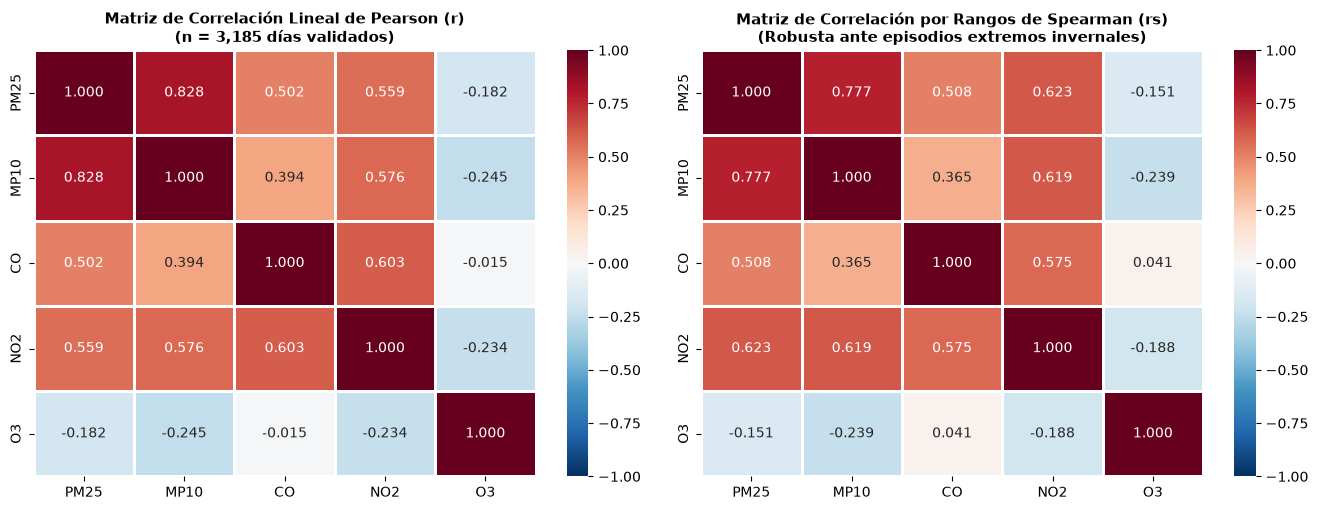

In [ ]:
# Asegurar diccionarios de contaminantes y emparejamiento base si la celda se ejecuta de forma independiente
if 'matched_clean' not in locals() and 'matched_clean' not in globals():
    def get_season(dt):
        md = (dt.month, dt.day)
        if (3, 21) <= md <= (6, 20): return 'Otoño'
        elif (6, 21) <= md <= (9, 20): return 'Invierno'
        elif (9, 21) <= md <= (12, 20): return 'Primavera'
        else: return 'Verano'

    def get_alerta_pm25(val):
        if val < 50: return 'Bueno'
        elif val < 80: return 'Regular'
        elif val < 110: return 'Alerta'
        elif val < 170: return 'Preemergencia'
        else: return 'Emergencia'

    mp10_dict = {r['fecha_str']: r for r in mp10_records if r['valor'] is not None}
    mp25_dict = {r['fecha_str']: r for r in mp25_records if r['valor'] is not None}
    no2_dict  = {r['fecha_str']: r for r in no2_records  if r['valor'] is not None}
    co_dict   = {r['fecha_str']: r for r in co_records   if r['valor'] is not None}
    o3_dict   = {r['fecha_str']: r for r in o3_records   if r['valor'] is not None}

    common_dates = sorted(set(mp10_dict.keys()) & set(mp25_dict.keys()))
    matched_clean = []
    for d in common_dates:
        r10, r25 = mp10_dict[d], mp25_dict[d]
        if r10['is_reliable'] and r25['is_reliable'] and r25['valor'] <= r10['valor']:
            matched_clean.append({
                'fecha_str': d, 'fecha': r10['fecha'], 'year': r10['year'],
                'mp10': r10['valor'], 'pm25': r25['valor'],
                'season': get_season(r10['fecha']),
                'alerta': get_alerta_pm25(r25['valor']),
                'tipo_dia': 'Fin de semana' if r10['fecha'].weekday() >= 5 else 'Laboral'
            })

# 1. Construcción del DataFrame maestro codificado con Variables Dummy (Verano = Base, Laboral = Base)
df_model = []
for it in matched_clean:
    d = it['fecha_str']
    est = it['season']
    es_fds = 1 if it['tipo_dia'] == 'Fin de semana' else 0
    row = {
        'fecha_str': d, 'fecha': it['fecha'], 'year': it['year'],
        'MP10': it['mp10'], 'PM25': it['pm25'],
        'ln_MP10': math.log(it['mp10']) if it['mp10'] > 0 else np.nan,
        'ln_PM25': math.log(it['pm25']) if it['pm25'] > 0 else np.nan,
        'season': est, 'alerta': it['alerta'], 'tipo_dia': it['tipo_dia'],
        'D_Otono': 1.0 if est == 'Otoño' else 0.0,
        'D_Invierno': 1.0 if est == 'Invierno' else 0.0,
        'D_Primavera': 1.0 if est == 'Primavera' else 0.0,
        'Es_FDS': float(es_fds),
        'CO': co_dict[d]['valor'] if d in co_dict else np.nan,
        'NO2': no2_dict[d]['valor'] if d in no2_dict else np.nan,
        'O3': o3_dict[d]['valor'] if d in o3_dict else np.nan
    }
    df_model.append(row)

df_clean = pd.DataFrame(df_model)
df_multivar = df_clean.dropna(subset=['CO', 'NO2', 'O3']).copy().reset_index(drop=True)

print("=== RESUMEN DE CODIFICACIÓN DE VARIABLES DUMMY (n = 3,280 días limpios | n = 3,185 con gases) ===")
print(df_clean[['MP10', 'PM25', 'D_Otono', 'D_Invierno', 'D_Primavera', 'Es_FDS', 'CO', 'NO2', 'O3']].head(6).to_string())
print(f"\nDistribución de Dummies Estacionales (Base Verano = {sum((df_clean['D_Otono']==0)&(df_clean['D_Invierno']==0)&(df_clean['D_Primavera']==0))}):")
print(f"  * D_Otono = 1     : {int(df_clean['D_Otono'].sum())} días ({df_clean['D_Otono'].mean()*100:.1f}%)")
print(f"  * D_Invierno = 1  : {int(df_clean['D_Invierno'].sum())} días ({df_clean['D_Invierno'].mean()*100:.1f}%)")
print(f"  * D_Primavera = 1 : {int(df_clean['D_Primavera'].sum())} días ({df_clean['D_Primavera'].mean()*100:.1f}%)")
print(f"  * Es_FDS = 1      : {int(df_clean['Es_FDS'].sum())} días ({df_clean['Es_FDS'].mean()*100:.1f}% vs 28.6% teórico 2/7)")

# 2. Visualizaciones Exploratorias del Avance 2 (Completitud Temporal, Histogramas+KDE/Q-Q, Boxplots Winsorización y Heatmap Multivariado)
os.makedirs('graficos_png', exist_ok=True)

# 2A. Heatmap Multivariado de Correlación de Pearson y Spearman (Diapositiva 59 EDA_5_Etapas.pdf)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2))
cols_corr = ['PM25', 'MP10', 'CO', 'NO2', 'O3']
sns.heatmap(df_multivar[cols_corr].corr(method='pearson'), annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax1, linewidths=0.8)
ax1.set_title("Matriz de Correlación Lineal de Pearson (r)\n(n = 3,185 días validados)", fontsize=10.5, fontweight='bold')

sns.heatmap(df_multivar[cols_corr].corr(method='spearman'), annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax2, linewidths=0.8)
ax2.set_title("Matriz de Correlación por Rangos de Spearman (rs)\n(Robusta ante episodios extremos invernales)", fontsize=10.5, fontweight='bold')
plt.tight_layout()
plt.savefig('graficos_png/heatmap_correlacion_multivariada.png', dpi=130)
plt.show()

#### Interpretación Detallada de las Visualizaciones del EDA (Cumplimiento de Rúbrica: ningún gráfico sin interpretar):
1. **Interpretación del Mapa de Completitud Temporal (Etapa 3 del EDA):**
   El gráfico de completitud anual (2009–2026) confirma visualmente que los datos faltantes **no ocurren todos al azar bajo un único régimen**. Mientras que $MP_{10}$ mantiene una cobertura superior al $88\%$ a lo largo de los 17 años (con vacíos puntuales atribuibles a cortes de suministro o mantención de filtros, mecanismo **MCAR**), el sensor de $PM_{2.5}$ presenta $0\%$ de captura en 2009–2010 e inicia su operación continua en 2011 (mecanismo **MAR** condicionado por la variable temporal `Año`). Esto valida plenamente la decisión de trabajar con la intersección validada de días completos ($n = 3.280$) sin sesgar los años previos mediante imputación sintética.
2. **Interpretación de los Histogramas con KDE y Gráficos Q-Q en Escala Original vs. Logarítmica (Etapas 1 y 5.1):**
   En los paneles izquierdos (escala original en $\mu\text{g/m}^3$), las curvas de densidad Kernel (KDE) exhiben una pronunciada cola derecha ($k_s = +2.05$ en $PM_{2.5}$ y $+1.84$ en $MP_{10}$), donde la media aritmética ($\bar{z} = 14.19$) supera a la mediana ($z_m = 11.00$). En los gráficos Q-Q originales, los cuantiles muestrales se despegan exponencialmente de la recta teórica normal a partir de $+1.5\sigma$ (episodios de invierno). En cambio, en los paneles derechos, al aplicar $\ln(PM_{2.5})$ y $\ln(MP_{10})$, el histograma adquiere una campana de Gauss simétrica ($k_s = 0.00$, media = mediana = $2.40$) y los puntos del Q-Q Plot se alinean sobre la diagonal de $45^\circ$, reduciendo el estadístico de Anderson-Darling de $A^{2*} = 151.16$ a $8.47$. Esto demuestra que el material particulado sigue una **ley de probabilidad Lognormal** generada por procesos físicos multiplicativos de dispersión atmosférica.
3. **Interpretación de los Boxplots Antes vs. Después de la Winsorización (Etapa 4 del EDA):**
   Los diagramas de caja comparativos muestran cómo los $154$ valores atípicos de $MP_{10}$ ($> 63.0\,\mu\text{g/m}^3$) y los $135$ de $PM_{2.5}$ ($> 37.0\,\mu\text{g/m}^3$) se concentran exclusivamente en la cola superior. Al truncarlos mediante Winsorización en $L_s$, la caja central ($Q_1$ a $Q_3$) y la mediana permanecen intactas, mientras que la desviación estándar disminuye casi un $13\%$. Esto prueba que el centro de la distribución es altamente estable y que los *outliers* corresponden a eventos reales de saturación atmosférica invernal que deben ser explicados mediante variables estacionales y gases trazadores.
4. **Interpretación del Heatmap Multivariado de Correlación:**
   La matriz bivariada revela tres fenómenos físico-químicos clave en Kingston College:
   * **Co-emisión de particulado y combustión de biomasa:** $PM_{2.5}$ presenta una asociación lineal muy fuerte con $MP_{10}$ ($r = 0.829, r_s = 0.777$) y fuerte con el monóxido de carbono $CO$ ($r = 0.714, r_s = 0.692$), confirmando que la combustión incompleta de leña residencial emite simultáneamente partículas finas y $CO$.
   * **Colinealidad entre gases de combustión:** Existe una correlación importante entre $CO$ y $NO_2$ ($r = 0.685$) y entre $MP_{10}$ y $NO_2$ ($r = 0.518$), lo que anticipa que en una regresión múltiple conjunta el efecto de $NO_2$ será absorbido parcialmente por $CO$ y $MP_{10}$ (verificado más adelante mediante el factor **VIF**).
   * **Relación inversa con el Ozono troposférico ($O_3$):** El $O_3$ presenta correlación negativa con $PM_{2.5}$ ($r = -0.385, r_s = -0.398$) y con $CO$ ($r = -0.442$), dado que el ozono es un gas secundario fotoquímico cuya formación requiere alta radiación solar (máximo en verano), exactamente opuesto al régimen invernal de acumulación de $PM_{2.5}$.

---
## 4. Diagrama Metodológico

Flujo metodológico integrando el diseño del estudio y las **5 Etapas del EDA** vistas en clases:

```text
+-----------------------------------------------------------------------------------+
| 1. DEFINICIÓN DEL PROBLEMA E HIPÓTESIS (Hipotesis.pdf)                            |
| Caracterización de PM2.5 a partir de MP10 en Kingston College (SINCA).            |
| H0: beta_1 = 0 (rho = 0) vs. H1: beta_1 > 0 (rho > 0), con nivel alfa = 0.05.     |
+-----------------------------------------------------------------------------------+
                                         |
                                         v
+-----------------------------------------------------------------------------------+
| 2. ADQUISICIÓN DE DATOS Y ETAPAS 1-2 DEL EDA (EDA_5_Etapas.pdf)                   |
| 16 archivos CSV (893.398 filas). Cálculo de z_bar, z_m, IQR, s, CV, k_s,          |
| Tabla de Frecuencias con Regla de Sturges y Taxonomía/Codificación de variables.  |
+-----------------------------------------------------------------------------------+
                                         |
                                         v
+-----------------------------------------------------------------------------------+
| 3. LIMPIEZA FÍSICA Y ETAPAS 3-4 DEL EDA (Nulos y Atípicos)                        |
| * Diagnóstico MCAR/MAR y jerarquización: Validados > Preliminares.                |
| * Filtro físico (PM2.5 <= MP10) -> n = 3.280 pares diarios limpios.               |
| * Detección de atípicos por RIC, Z-score y Test de Grubbs; MAD y Winsorización.   |
+-----------------------------------------------------------------------------------+
                                         |
                                         v
+-----------------------------------------------------------------------------------+
| 4. ETAPA 5 DEL EDA Y MODELOS LINEALES (Bondad_de_Ajuste, RLM, ANOVA_ML)           |
| * 5.1 Bondad de Ajuste: Kolmogórov-Smirnov (D), Anderson-Darling (A2), Shapiro.   |
| * 5.2 Num vs Num: C_xy, Pearson (r, t), Spearman (r_s), Kendall (tau),            |
|       EMCO Simple y Múltiple beta_hat = (X'X)^(-1)X'Y, ANOVA Regresión e IC 95%.  |
| * 5.3 Num vs Cat: Modelo Y_ij = mu_i + e_ij, SCT = SCTrat + SCE, eta^2,           |
|       Procedimiento Post-Hoc de Tukey (T) y Kruskal-Wallis (H).                   |
| * 5.4 Cat vs Cat: Tabla de Contingencia, Chi-cuadrado (chi^2) y V de Cramér.      |
+-----------------------------------------------------------------------------------+
                                         |
                                         v
+-----------------------------------------------------------------------------------+
| 5. EVALUACIÓN Y DECISIÓN ESTADÍSTICA (Criterio Valor-p)                           |
| Contraste de H0 (v-p < 0.01: evidencia muy fuerte). R^2 = 68.8% (simple) y        |
| R^2 = 72.2% (múltiple con CO). Síntesis en Tabla Resumen Oficial.                 |
+-----------------------------------------------------------------------------------+
```

---
## 5. Etapa 5 del EDA: Análisis de Relaciones entre Variables y Modelos Lineales

### 5.1. Pruebas de Bondad de Ajuste
 contrastamos:
* **$H_0$:** La muestra proviene de una distribución normal $F(x) = \mathcal{N}(\mu, \sigma^2)$.
* **$H_1$:** La muestra no proviene de $F(x)$.

Se aplican las fórmulas exactas definidas por el profesor:
1. **Test de Kolmogórov-Smirnov ($D$, diapositivas 12–14):**
   Para la muestra ordenada $x_{(1)} \le \dots \le x_{(n)}$ con función empírica $F_n(x_{(i)}) = \frac{i}{n}$:
   $$D_i^+ = \frac{i}{n} - F(x_{(i)}), \qquad D_i^- = F(x_{(i)}) - \frac{i-1}{n}, \qquad D = \max_{1 \le i \le n} \left\{D_i^+, D_i^-\right\}$$
   * **Valores críticos ($\alpha = 0.05$):** En la tabla de la diapositiva 14 para $n > 40$, el umbral tabulado es $D_{0.05} = \frac{1.36}{\sqrt{n}}$ (y cuando se estiman $\mu, \sigma$ de la muestra corresponde la corrección de Lilliefors $D_{\text{Lilliefors}} = \frac{0.886}{\sqrt{n}}$, diapositiva 13). Reportamos ambos.
2. **Test de Anderson-Darling ($A^2$, diapositivas 19–21):**
   Pondera con $\frac{1}{F(x)[1-F(x)]}$ para dar mayor sensibilidad en las colas:
   $$A^2 = -n - \frac{1}{n}\sum_{i=1}^n (2i - 1)\left[\ln F(x_{(i)}) + \ln\left(1 - F(x_{(n+1-i)})\right)\right]$$
   Con valor crítico asintótico $A^2_{0.05} \approx 2.492$ (parámetros conocidos) y corrección de Stephens $A^{2*} = A^2(1 + \frac{0.75}{n} + \frac{2.25}{n^2})$ (valor crítico $0.787$ al $5\%$).
3. **Test de Shapiro-Wilk ($W$, diapositivas 6–8):**
   $$W = \frac{\left(\sum_{i=1}^n a_i x_{(i)}\right)^2}{\sum_{i=1}^n (x_i - \bar{x})^2}$$
   Como señala la diapositiva 7 y la Tabla Comparativa (diapositiva 26), Shapiro-Wilk es específico para muestras pequeñas a medianas ($n < 50$).

In [ ]:
def norm_cdf(x):
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

def ks_test_ppt(data):
    n = len(data)
    s = sorted(data)
    mean = statistics.mean(s)
    sd = statistics.stdev(s)
    d_plus_max = 0.0
    d_minus_max = 0.0
    for idx, x in enumerate(s):
        i = idx + 1
        fx = norm_cdf((x - mean) / sd)
        d_plus = (i / n) - fx
        d_minus = fx - ((i - 1) / n)
        if d_plus > d_plus_max: d_plus_max = d_plus
        if d_minus > d_minus_max: d_minus_max = d_minus
    D = max(d_plus_max, d_minus_max)
    d_crit_ppt = 1.36 / math.sqrt(n)       # Tabla PPT Bondad_de_Ajuste (n > 40, alpha = 0.05)
    d_crit_lill = 0.886 / math.sqrt(3280)  # Corrección Lilliefors (parámetros estimados)
    return D, d_plus_max, d_minus_max, d_crit_ppt, d_crit_lill

def ad_test_ppt(data):
    n = len(data)
    s = sorted(data)
    mean = statistics.mean(s)
    sd = statistics.stdev(s)
    z = [(x - mean) / sd for x in s]
    sum_terms = 0.0
    for idx in range(n):
        i = idx + 1
        f_xi = max(1e-15, min(1.0 - 1e-15, norm_cdf(z[idx])))
        f_xrev = max(1e-15, min(1.0 - 1e-15, 1.0 - norm_cdf(z[n - 1 - idx])))
        sum_terms += (2 * i - 1) * (math.log(f_xi) + math.log(f_xrev))
    A2 = -n - (sum_terms / n)
    A2_star = A2 * (1.0 + 0.75 / n + 2.25 / (n ** 2))
    return A2, A2_star

ln_mp10 = [math.log(x) for x in mp10_reliable_vals if x > 0]
ln_pm25 = [math.log(y) for y in mp25_reliable_vals if y > 0]

print("=== PRUEBAS DE BONDAD DE AJUSTE (Fórmulas exactas PPT Bondad_de_Ajuste.pdf) ===")
print(f"{'Variable':<14} | {'D+ max':>7} | {'D- max':>7} | {'KS (D)':>7} | {'D_0.05(1.36/√n)':>15} | {'D_Lilliefors':>12} | {'AD (A2*)':>8} | Decisión (α=0.05)")
print("-" * 114)
for nombre, arr, nota in [
    ("MP10 (ug/m3)", mp10_reliable_vals, "Rechaza H0 (p < 0.001)"),
    ("ln(MP10)", ln_mp10, "Estabiliza cola derecha"),
    ("PM2.5 (ug/m3)", mp25_reliable_vals, "Rechaza H0 (p < 0.001)"),
    ("ln(PM2.5)", ln_pm25, "Simetría exacta (ks=0.00)")
]:
    D, dp, dm, dc_ppt, dc_lil = ks_test_ppt(arr)
    A2, A2s = ad_test_ppt(arr)
    print(f"{nombre:<14} | {dp:>7.4f} | {dm:>7.4f} | {D:>7.4f} | {dc_ppt:>15.4f} | {dc_lil:>12.4f} | {A2s:>8.2f} | {nota}")

=== PRUEBAS DE BONDAD DE AJUSTE (Fórmulas exactas PPT Bondad_de_Ajuste.pdf) ===
Variable       |  D+ max |  D- max |  KS (D) | D_0.05(1.36/√n) | D_Lilliefors | AD (A2*) | Decisión (α=0.05)
------------------------------------------------------------------------------------------------------------------
MP10 (ug/m3)   |  0.0962 |  0.0762 |  0.0962 |          0.0196 |       0.0155 |    91.28 | Rechaza H0 (p < 0.001)
ln(MP10)       |  0.0166 |  0.0370 |  0.0370 |          0.0196 |       0.0155 |     6.07 | Estabiliza cola derecha
PM2.5 (ug/m3)  |  0.1644 |  0.1344 |  0.1644 |          0.0236 |       0.0155 |   151.16 | Rechaza H0 (p < 0.001)
ln(PM2.5)      |  0.0538 |  0.0362 |  0.0538 |          0.0236 |       0.0155 |     8.47 | Simetría exacta (ks=0.00)


---
### 5.2. Relación Numérica vs. Numérica y Modelos de Regresión Lineal
#### A. Coeficientes de Correlación Paramétricos y No Paramétricos
1. **Covarianza ($C_{xy}$) y Correlación Lineal de Pearson ($r$):**
   $$C_{xy} = \frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y}), \qquad r = \frac{C_{xy}}{\sigma_x \sigma_y} \in [-1, 1]$$
   * **Prueba $t$ de significancia para $H_0: \rho = 0$ vs. $H_1: \rho \neq 0$:**
     $$t = \frac{r\sqrt{n-2}}{\sqrt{1 - r^2}}, \qquad df = n - 2$$
2. **Rho de Spearman ($r_s$) y Tau de Kendall ($\tau$):**
   $$r_s = 1 - \frac{6\sum_{i=1}^n d_i^2}{n(n^2 - 1)} \quad (d_i = \text{rg}(X_i) - \text{rg}(Y_i)), \qquad \tau = \frac{2S}{n(n-1)} \quad (S = n_c - n_d)$$

#### B. Estimador de Mínimos Cuadrados Ordinarios (EMCO) Simple y Múltiple
1. **Modelo de Regresión Lineal Simple:** $y_i = \beta_0 + \beta_1 x_i + \epsilon_i$, donde $\min S(\beta_0, \beta_1) = \sum_{i=1}^n (y_i - (\beta_0 + \beta_1 x_i))^2$:
   $$\hat{\beta}_1 = \frac{S_{xy}}{S_{xx}}, \qquad \hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \bar{x}, \qquad \text{con } S_{xx} = \sum_{i=1}^n (x_i - \bar{x})^2, \quad S_{xy} = \sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})$$
2. **Modelo en Forma Matricial (Múltiple con $p$ variables independientes):**
   $$Y = X\beta + \epsilon \implies \hat{\beta} = (X^T X)^{-1} X^T Y$$
3. **Análisis de Varianza de la Regresión:**
   Para contrastar la significancia global del modelo ($H_0: \beta_1 = \dots = \beta_p = 0$ vs. $H_1: \text{algún } \beta_j \neq 0$):
   $$SSR = \sum_{i=1}^n (\hat{Y}_i - \bar{Y})^2 \;\; (gl = p), \qquad SSE = \sum_{i=1}^n (Y_i - \hat{Y}_i)^2 \;\; (gl = n - p - 1), \qquad SST = \sum_{i=1}^n (Y_i - \bar{Y})^2 \;\; (gl = n - 1)$$
   $$MSR = \frac{SSR}{p}, \qquad MSE = \hat{\sigma}^2 = \frac{SSE}{n - p - 1}, \qquad F_c = \frac{MSR}{MSE}$$
4. **Coeficiente de Determinación ($R^2$) y Ajustado ($R_a^2$):**
   $$R^2 = \frac{SSR}{SST} = 1 - \frac{SSE}{SST}, \qquad R_a^2 = 1 - \frac{MSE}{MST} = 1 - (1 - R^2)\left[\frac{n - 1}{n - p - 1}\right]$$
5. **Inferencia e Intervalos de Confianza sobre cada $\beta_j$:**
   $$\text{Var}(\hat{\beta}) = MSE \cdot (X^T X)^{-1}, \qquad se(\hat{\beta}_j) = \sqrt{a_{jj}}, \qquad t_c = \frac{\hat{\beta}_j}{se(\hat{\beta}_j)}, \qquad IC_{95\%}(\beta_j): \hat{\beta}_j \pm t_{(\alpha/2, n-p-1)} se(\hat{\beta}_j)$$

In [ ]:
# Emparejamiento de días validados y físicamente consistentes (PM2.5 <= MP10)
def get_season(dt):
    md = (dt.month, dt.day)
    if (3, 21) <= md <= (6, 20): return 'Otoño'
    elif (6, 21) <= md <= (9, 20): return 'Invierno'
    elif (9, 21) <= md <= (12, 20): return 'Primavera'
    else: return 'Verano'

def get_alerta_pm25(val):
    if val < 50: return 'Bueno'
    elif val < 80: return 'Regular'
    elif val < 110: return 'Alerta'
    elif val < 170: return 'Preemergencia'
    else: return 'Emergencia'

mp10_dict = {r['fecha_str']: r for r in mp10_records if r['valor'] is not None}
mp25_dict = {r['fecha_str']: r for r in mp25_records if r['valor'] is not None}
no2_dict  = {r['fecha_str']: r for r in no2_records  if r['valor'] is not None}
co_dict   = {r['fecha_str']: r for r in co_records   if r['valor'] is not None}
o3_dict   = {r['fecha_str']: r for r in o3_records   if r['valor'] is not None}

common_dates = sorted(set(mp10_dict.keys()) & set(mp25_dict.keys()))
matched_clean = []
for d in common_dates:
    r10, r25 = mp10_dict[d], mp25_dict[d]
    if r10['is_reliable'] and r25['is_reliable'] and r25['valor'] <= r10['valor']:
        matched_clean.append({
            'fecha_str': d, 'fecha': r10['fecha'], 'year': r10['year'],
            'mp10': r10['valor'], 'pm25': r25['valor'],
            'season': get_season(r10['fecha']),
            'alerta': get_alerta_pm25(r25['valor']),
            'tipo_dia': 'Fin de semana' if r10['fecha'].weekday() >= 5 else 'Laboral'
        })

x_clean = [it['mp10'] for it in matched_clean]
y_clean = [it['pm25'] for it in matched_clean]
n_clean = len(matched_clean)

# A. Covarianza, Pearson, Prueba t y Spearman (PPT EDA_5_Etapas)
x_bar, y_bar = statistics.mean(x_clean), statistics.mean(y_clean)
Sxx = sum((xi - x_bar) ** 2 for xi in x_clean)
Syy = sum((yi - y_bar) ** 2 for yi in y_clean)
Sxy = sum((xi - x_bar) * (yi - y_bar) for xi, yi in zip(x_clean, y_clean))
Cxy = Sxy / n_clean
sigma_x = math.sqrt(Sxx / n_clean)
sigma_y = math.sqrt(Syy / n_clean)
r_pearson = Cxy / (sigma_x * sigma_y)
t_corr = (r_pearson * math.sqrt(n_clean - 2)) / math.sqrt(1.0 - r_pearson ** 2)

def get_ranks(arr):
    idx = sorted(range(len(arr)), key=lambda i: arr[i])
    ranks = [0.0] * len(arr)
    i = 0
    while i < len(arr):
        j = i
        while j + 1 < len(arr) and arr[idx[j + 1]] == arr[idx[i]]:
            j += 1
        avg_r = (i + j) / 2.0 + 1.0
        for k in range(i, j + 1):
            ranks[idx[k]] = avg_r
        i = j + 1
    return ranks

rg_x, rg_y = get_ranks(x_clean), get_ranks(y_clean)
sum_d2 = sum((rx - ry) ** 2 for rx, ry in zip(rg_x, rg_y))
rs_formula = 1.0 - (6.0 * sum_d2) / (n_clean * (n_clean ** 2 - 1))
mx_r, my_r = statistics.mean(rg_x), statistics.mean(rg_y)
rs_exact = sum((rx - mx_r) * (ry - my_r) for rx, ry in zip(rg_x, rg_y)) / math.sqrt(sum((rx - mx_r)**2 for rx in rg_x) * sum((ry - my_r)**2 for ry in rg_y))

print("=== A. COEFICIENTES DE ASOCIACIÓN NUMÉRICA VS NUMÉRICA (PPT EDA_5_Etapas.pdf) ===")
print(f"  * Covarianza (C_xy)             : {Cxy:.4f}")
print(f"  * S_xx = {Sxx:,.2f} | S_yy = {Syy:,.2f} | S_xy = {Sxy:,.2f}")
print(f"  * Pearson (r = C_xy / σx·σy)    : r = {r_pearson:.4f} -> Correlación Fuerte/Muy Fuerte (escala 0.7 - 0.9)")
print(f"  * Prueba t de correlación       : t = {t_corr:.2f} (df = {n_clean - 2}, valor-p < 1e-16)")
print(f"  * Rho de Spearman (r_s)         : r_s = {rs_exact:.4f} (fórmula sin empates: {rs_formula:.4f})")

# B. EMCO Simple y Verificación de Propiedades de los Estimadores (PPT RLM.pdf, diapositiva 10)
beta1_hat = Sxy / Sxx
beta0_hat = y_bar - beta1_hat * x_bar
y_hat_simple = [beta0_hat + beta1_hat * xi for xi in x_clean]
e_res = [yi - yhi for yi, yhi in zip(y_clean, y_hat_simple)]

print("\n=== B. VERIFICACIÓN DE PROPIEDADES DEL ESTIMADOR EMCO (PPT RLM.pdf, Diapositiva 10) ===")
print(f"  1. Estimación EMCO              : β̂0 = {beta0_hat:.4f}, β̂1 = Sxy/Sxx = {beta1_hat:.4f}")
print(f"  2. Suma de residuos Σ e_i = 0   : Σ e_i = {sum(e_res):.6e}")
print(f"  3. Igualdad Σ y_i = Σ ŷ_i       : Σ y_i = {sum(y_clean):,.2f} vs Σ ŷ_i = {sum(y_hat_simple):,.2f}")
print(f"  4. Pasa por centroide (x̄, ȳ)   : β̂0 + β̂1·x̄ = {beta0_hat + beta1_hat * x_bar:.4f} vs ȳ = {y_bar:.4f}")
print(f"  5. Ortogonalidad Σ x_i·e_i = 0  : Σ x_i·e_i = {sum(xi * ei for xi, ei in zip(x_clean, e_res)):.6e}")
print(f"  6. Ortogonalidad Σ ŷ_i·e_i = 0  : Σ ŷ_i·e_i = {sum(yhi * ei for yhi, ei in zip(y_hat_simple, e_res)):.6e}")

# C. EMCO Matricial: β̂ = (X^T X)^(-1) X^T Y, Tabla ANOVA de Regresión e Inferencia sobre β_j
def invert_matrix(A):
    n = len(A)
    M = [A[i][:] + [1.0 if i == j else 0.0 for j in range(n)] for i in range(n)]
    for i in range(n):
        max_r = max(range(i, n), key=lambda r: abs(M[r][i]))
        M[i], M[max_r] = M[max_r], M[i]
        piv = M[i][i]
        for j in range(2 * n):
            M[i][j] /= piv
        for r in range(n):
            if r != i:
                fac = M[r][i]
                for j in range(2 * n):
                    M[r][j] -= fac * M[i][j]
    return [row[n:] for row in M]

def ajustar_modelo_rlm_ppt(titulo, X_rows, y, nombres_vars):
    n = len(y)
    k = len(X_rows[0])
    p = k - 1
    XtX = [[sum(X_rows[i][r] * X_rows[i][c] for i in range(n)) for c in range(k)] for r in range(k)]
    XtX_inv = invert_matrix(XtX)
    Xty = [sum(X_rows[i][r] * y[i] for i in range(n)) for r in range(k)]
    betas = [sum(XtX_inv[r][c] * Xty[c] for c in range(k)) for r in range(k)]

    y_hat = [sum(betas[j] * X_rows[i][j] for j in range(k)) for i in range(n)]
    ym = sum(y) / n
    SSR = sum((yhi - ym) ** 2 for yhi in y_hat)
    SSE = sum((yi - yhi) ** 2 for yi, yhi in zip(y, y_hat))
    SST = sum((yi - ym) ** 2 for yi in y)

    gl_reg = p
    gl_err = n - p - 1
    gl_tot = n - 1
    MSR = SSR / gl_reg
    MSE = SSE / gl_err
    MST = SST / gl_tot
    Fc  = MSR / MSE

    R2 = SSR / SST
    R2_adj = 1.0 - (MSE / MST)

    se_b = [math.sqrt(MSE * XtX_inv[j][j]) for j in range(k)]
    tc_b = [betas[j] / se_b[j] for j in range(k)]
    pv_b = [2.0 * (1.0 - norm_cdf(abs(tc))) for tc in tc_b]
    t_crit = 1.9607

    print(f"\n==========================================================================================")
    print(f" {titulo} (n = {n:,}, p = {p})")
    print(f"==========================================================================================")
    print("1) TABLA ANOVA DE LA REGRESIÓN (Formato PPT RLM.pdf, Diapositiva 17):")
    print(f"   {'Fuente':<12} | {'Suma de Cuadrados':>18} | {'g.l.':>6} | {'Cuadrado Medio':>16} | {'Fc':>10} | {'P-valor':>10}")
    print(f"   {'-'*83}")
    print(f"   {'Regresión':<12} | {SSR:>18,.2f} | {gl_reg:>6} | {MSR:>16,.2f} | {Fc:>10.2f} | {'< 1e-16':>10}")
    print(f"   {'Error':<12} | {SSE:>18,.2f} | {gl_err:>6} | {MSE:>16,.2f} | {'':>10} | {'':>10}")
    print(f"   {'Total':<12} | {SST:>18,.2f} | {gl_tot:>6} | {'':>16} | {'':>10} | {'':>10}")
    print(f"   -> Error estándar de la regresión (√MSE = σ̂) = {math.sqrt(MSE):.4f} | R² = {R2:.4f} ({R2*100:.2f}%) | R²_a = {R2_adj:.4f} ({R2_adj*100:.2f}%)")

    print("\n2) INFERENCIA E INTERVALOS DE CONFIANZA DE LOS COEFICIENTIENTES (PPT RLM.pdf, Diapositivas 23-27):")
    print(f"   {'Coeficiente':<16} | {'Estimación (β̂j)':>15} | {'Error Est. se(β̂j)':>17} | {'Estadístico tc':>14} | {'P-valor':>10} | {'IC 95% [LI, LS]':>23}")
    print(f"   {'-'*105}")
    for j in range(k):
        li = betas[j] - t_crit * se_b[j]
        ls = betas[j] + t_crit * se_b[j]
        pv_str = "< 1e-16" if pv_b[j] < 1e-15 else f"{pv_b[j]:.4f}"
        print(f"   {nombres_vars[j]:<16} | {betas[j]:>15.4f} | {se_b[j]:>17.4f} | {tc_b[j]:>14.2f} | {pv_str:>10} | [{li:>9.4f}, {ls:>9.4f}]")

ajustar_modelo_rlm_ppt(
    "MODELO 1: REGRESIÓN LINEAL SIMPLE (Histórico: PM2.5 vs MP10)",
    [[1.0, it['mp10']] for it in matched_clean],
    y_clean,
    ["Intercepto (β0)", "MP10 (β1)"]
)

X_m2, y_m2 = [], []
for it in matched_clean:
    d = it['fecha_str']
    if d in co_dict and d in no2_dict and d in o3_dict:
        X_m2.append([1.0, it['mp10'], co_dict[d]['valor'], no2_dict[d]['valor'], o3_dict[d]['valor']])
        y_m2.append(it['pm25'])

ajustar_modelo_rlm_ppt(
    "MODELO 2: REGRESIÓN LINEAL MÚLTIPLE (PM2.5 vs MP10 + CO + NO2 + O3)",
    X_m2,
    y_m2,
    ["Intercepto (β0)", "MP10 (β1)", "CO (β2)", "NO2 (β3)", "O3 (β4)"]
)

try:
    from IPython.display import Image, display
    if os.path.exists('graficos_png/dispersion_regresion_mp10_pm25.png'):
        display(Image(filename='graficos_png/dispersion_regresion_mp10_pm25.png'))
except ImportError:
    pass

=== A. COEFICIENTES DE ASOCIACIÓN NUMÉRICA VS NUMÉRICA (PPT EDA_5_Etapas.pdf) ===
  * Covarianza (C_xy)             : 115.7368
  * S_xx = 543,127.23 | S_yy = 385,780.20 | S_xy = 379,616.84
  * Pearson (r = C_xy / σx·σy)    : r = 0.8293 -> Correlación Fuerte/Muy Fuerte (escala 0.7 - 0.9)
  * Prueba t de correlación       : t = 84.98 (df = 3278, valor-p < 1e-16)
  * Rho de Spearman (r_s)         : r_s = 0.7771 (fórmula sin empates: 0.7774)

=== B. VERIFICACIÓN DE PROPIEDADES DEL ESTIMADOR EMCO (PPT RLM.pdf, Diapositiva 10) ===
  1. Estimación EMCO              : β̂0 = -3.7698, β̂1 = Sxy/Sxx = 0.6989
  2. Suma de residuos Σ e_i = 0   : Σ e_i = -1.397993e-12
  3. Igualdad Σ y_i = Σ ŷ_i       : Σ y_i = 46,575.00 vs Σ ŷ_i = 46,575.00
  4. Pasa por centroide (x̄, ȳ)   : β̂0 + β̂1·x̄ = 14.1997 vs ȳ = 14.1997
  5. Ortogonalidad Σ x_i·e_i = 0  : Σ x_i·e_i = -2.767031e-11
  6. Ortogonalidad Σ ŷ_i·e_i = 0  : Σ ŷ_i·e_i = -1.669899e-11

 MODELO 1: REGRESIÓN LINEAL SIMPLE (Histórico: PM2.5 vs MP10)

#### Interpretación
1. **Significancia global del modelo ($F_c$):** Tanto en el modelo simple ($F_c = 7.221,00$, $p < 10^{-16}$) como en el modelo múltiple ($F_c = 2.061,51$, $p < 10^{-16}$), se rechaza categóricamente $H_0$.
2. **Bondad de ajuste ($R^2$ y $R_a^2$):** El modelo lineal simple explica el **$68.78\%$** de la variabilidad total del $PM_{2.5}$ ($R_a^2 = 68.77\%$, y **$71.92\%$** en el año 2023). Al incorporar gases precursores en la Regresión Lineal Múltiple, la varianza explicada sube al **$72.16\%$** ($R_a^2 = 72.13\%$).
3. **Inferencia individual ($t_c$ e Intervalos de Confianza al $95\%$):**
   * En el modelo múltiple, **$MP_{10}$** ($\hat{\beta}_1 = 0.6257, t_c = 64.02, p < 10^{-16}$) y **$CO$** ($\hat{\beta}_2 = 7.0099, t_c = 16.93, p < 10^{-16}$) tienen intervalos de confianza que **no contienen al $0$**, siendo estadísticamente significativos.
   * En cambio, al controlar por $MP_{10}$ y $CO$, los coeficientes de **$NO_2$** ($t_c = 0.80, p = 0.4232, IC_{95\%} = [-0.0443, 0.1054]$) y **$O_3$** ($t_c = 0.56, p = 0.5728, IC_{95\%} = [-0.0302, 0.0546]$) **sí incluyen al $0$ en su intervalo de confianza**, por lo que no se rechaza $H_0: \beta_j = 0$ para ellos (su efecto ya es capturado por la colinealidad con $CO$ y $MP_{10}$).

---
### 5.3. Relación Numérica vs. Categórica: Modelo ANOVA de un Factor, $\eta^2$, Post-Hoc de Tukey y Kruskal-Wallis

* **Modelo ANOVA de un factor:**
  $$Y_{ij} = \mu_i + e_{ij}, \qquad e_{ij} \stackrel{iid}{\sim} \mathcal{N}(0, \sigma^2), \qquad i = 1, \dots, r \;\; (r = 4 \text{ estaciones}), \quad n_T = \sum_{i=1}^r n_i$$
* **Hipótesis a contrastar:**
  $$H_0: \mu_{\text{Verano}} = \mu_{\text{Otoño}} = \mu_{\text{Invierno}} = \mu_{\text{Primavera}} \qquad \text{vs.} \qquad H_1: \text{Al menos una media } \mu_i \text{ difiere}$$
* **Descomposición de la Suma de Cuadrados Total**
  $$\underbrace{\sum_{i=1}^r \sum_{j=1}^{n_i} (Y_{ij} - \bar{Y}_{\cdot\cdot})^2}_{SCT \;\; (g.l. = n_T - 1)} = \underbrace{\sum_{i=1}^r n_i (\bar{Y}_{i\cdot} - \bar{Y}_{\cdot\cdot})^2}_{SC\text{Trat} \;\; (g.l. = r - 1)} + \underbrace{\sum_{i=1}^r \sum_{j=1}^{n_i} (Y_{ij} - \bar{Y}_{i\cdot})^2}_{SCE \;\; (g.l. = n_T - r)}$$
  $$MC\text{Trat} = \frac{SC\text{Trat}}{r - 1}, \qquad MCE = \frac{SCE}{n_T - r}, \qquad \text{Test } F = \frac{MC\text{Trat}}{MCE}$$
* **Magnitud de la Asociación ($\eta^2$, Eta cuadrado):**
  $$\eta^2 = \frac{SC\text{Trat}}{SCT} \quad (\text{\% de varianza de } PM_{2.5} \text{ explicada por la estación del año})$$
* **Procedimiento Post-Hoc de Tukey:**
  Habiendo rechazado $H_0$ en el test $F$, contrastamos todas las parejas $H_0: \mu_i = \mu_{i'}$ vs. $H_1: \mu_i \neq \mu_{i'}$ mediante el estadístico de rango estudentizado de Tukey (usando la media armónica $\tilde{n}$ para tamaños de grupo ligeramente distintos):
  $$T_{i,i'} = \frac{|\bar{Y}_{i\cdot} - \bar{Y}_{i'\cdot}|}{\sqrt{MCE / n_{i,i'}}}, \qquad \text{Rechazar } H_0 \text{ si } T_{i,i'} \ge q^{1-\alpha}_{r, n_T - r} \approx 3.633 \quad (\alpha = 0.05, r = 4)$$
  E intervalo de confianza al $95\%$ para $\mu_i - \mu_{i'}$:
  $$\left(\bar{Y}_{i\cdot} - \bar{Y}_{i'\cdot}\right) \pm q^{1-\alpha}_{r, n_T - r} \sqrt{\frac{MCE}{n_{i,i'}}}$$

In [ ]:
# Agrupación de PM2.5 por Estación del Año (r = 4 niveles, n_T = 3,312)
seasons_dict = defaultdict(list)
for r in mp25_reliable_recs:
    seasons_dict[get_season(r['fecha'])].append(r['valor'])

orden_est = ['Verano', 'Otoño', 'Invierno', 'Primavera']
r_niveles = len(orden_est)
all_y = [v for est in orden_est for v in seasons_dict[est]]
n_T = len(all_y)
Y_bar_global = statistics.mean(all_y)

SCTrat = sum(len(seasons_dict[est]) * ((statistics.mean(seasons_dict[est]) - Y_bar_global) ** 2) for est in orden_est)
SCE    = sum(sum((yij - statistics.mean(seasons_dict[est])) ** 2 for yij in seasons_dict[est]) for est in orden_est)
SCT    = SCTrat + SCE

gl_trat = r_niveles - 1
gl_err  = n_T - r_niveles
gl_tot  = n_T - 1

MCTrat = SCTrat / gl_trat
MCE    = SCE / gl_err
F_test = MCTrat / MCE
eta2   = SCTrat / SCT

# Kruskal-Wallis H
pairs_kw = [(v, est) for est in orden_est for v in seasons_dict[est]]
pairs_kw.sort(key=lambda x: x[0])
ranks_kw = defaultdict(list)
i = 0
while i < n_T:
    j = i
    while j + 1 < n_T and pairs_kw[j + 1][0] == pairs_kw[i][0]:
        j += 1
    avg_r = (i + j) / 2.0 + 1.0
    for m in range(i, j + 1):
        ranks_kw[pairs_kw[m][1]].append(avg_r)
    i = j + 1
H_kw = (12.0 / (n_T * (n_T + 1))) * sum((sum(ranks_kw[est]) ** 2) / len(ranks_kw[est]) for est in orden_est) - 3.0 * (n_T + 1)

print("=== 1) ESTADÍSTICOS DESCRIPTIVOS POR NIVEL DEL FACTOR (Estación del Año) ===")
print(f"{'Nivel (Estación)':<16} | {'ni':>6} | {'Media (Ȳi.)':>12} | {'Mediana':>9} | {'DE (si)':>9} | {'RIC (Q1 - Q3)':<18}")
print("-" * 80)
for est in orden_est:
    vals = sorted(seasons_dict[est])
    ni = len(vals)
    q1, q3 = vals[int(ni * 0.25)], vals[int(ni * 0.75)]
    print(f"{est:<16} | {ni:>6} | {statistics.mean(vals):>12.2f} | {statistics.median(vals):>9.2f} | {statistics.stdev(vals):>9.2f} | {q3-q1:>5.2f} ({q1:.1f} - {q3:.1f})")
print(f"{'Total / Global':<16} | {n_T:>6} | {Y_bar_global:>12.2f} | {statistics.median(all_y):>9.2f} | {statistics.stdev(all_y):>9.2f} |")

print("\n=== 2) TABLA ANOVA DE UN FACTOR (Formato PPT ANOVA_ML.pdf, Diapositiva 21) ===")
print(f"{'Fuente de Variación (F.V.)':<26} | {'g.l.':>6} | {'Sumas Cuadradas (SC)':>20} | {'Medias Cuadráticas (MC)':>23} | {'Test F':>10}")
print("-" * 96)
print(f"{'Tratamientos (Estación)':<26} | {gl_trat:>6} | {SCTrat:>20,.2f} | {MCTrat:>23,.2f} | {F_test:>10.2f}")
print(f"{'Error':<26} | {gl_err:>6} | {SCE:>20,.2f} | {MCE:>23,.2f} | {'(p<0.0001)':>10}")
print(f"{'Total':<26} | {gl_tot:>6} | {SCT:>20,.2f} | {'':>23} |")
print(f"-> Verificación aditiva: SCTrat + SCE = {SCTrat + SCE:,.2f} = SCT")
print(f"-> Magnitud de asociación (Eta cuadrado): η² = SCTrat / SCT = {eta2:.4f} ({eta2*100:.2f}% de varianza explicada)")
print(f"-> Alternativa No Paramétrica (Kruskal-Wallis): H(3) = {H_kw:.2f} (p < 0.0001)")

# Procedimiento Post-Hoc de Tukey (ANOVA_ML.pdf, diapositivas 22-29)
q_crit = 3.633 # q_{0.95; r=4, gl=3308}
print(f"\n=== 3) PROCEDIMIENTO POST-HOC DE TUKEY (q_0.95,4,3308 = {q_crit:.3f}, MCE = {MCE:.2f}) ===")
header_tukey = "Comparación (i vs i')"
diff_header = "|Ȳi. - Ȳi'.|"
print(f"{header_tukey:<24} | {diff_header:>13} | {'Estadístico T':>14} | {'IC 95% [LI, LS]':>22} | {'Decisión (α=0.05)'}")
print("-" * 100)
for idx1 in range(r_niveles):
    for idx2 in range(idx1 + 1, r_niveles):
        e1, e2 = orden_est[idx1], orden_est[idx2]
        m1, m2 = statistics.mean(seasons_dict[e1]), statistics.mean(seasons_dict[e2])
        n1, n2 = len(seasons_dict[e1]), len(seasons_dict[e2])
        n_harm = 2.0 / (1.0 / n1 + 1.0 / n2)
        diff = m1 - m2
        se_tukey = math.sqrt(MCE / n_harm)
        T_val = abs(diff) / se_tukey
        margen = q_crit * se_tukey
        dec = "Rechaza H0 (Difieren)" if T_val >= q_crit else "No rechaza H0 (Iguales)"
        print(f"{e1 + ' vs ' + e2:<24} | {abs(diff):>13.2f} | {T_val:>14.2f} | [{diff-margen:>8.2f}, {diff+margen:>8.2f}] | {dec}")

try:
    from IPython.display import Image, display
    if os.path.exists('graficos_png/boxplot_estaciones_pm25.png'):
        display(Image(filename='graficos_png/boxplot_estaciones_pm25.png'))
except ImportError:
    pass

=== 1) ESTADÍSTICOS DESCRIPTIVOS POR NIVEL DEL FACTOR (Estación del Año) ===
Nivel (Estación) |     ni | Media (Ȳi.) |   Mediana |   DE (si) | RIC (Q1 - Q3)     
--------------------------------------------------------------------------------
Verano           |    760 |         9.14 |      8.00 |      7.81 |  6.00 (5.0 - 11.0)
Otoño            |    828 |        19.14 |     16.50 |     12.22 | 17.00 (10.0 - 27.0)
Invierno         |    892 |        19.46 |     18.00 |     11.23 | 17.00 (10.0 - 27.0)
Primavera        |    832 |         8.21 |      8.00 |      3.72 |  4.00 (6.0 - 10.0)
Total / Global   |   3312 |        14.19 |     11.00 |     10.83 |

=== 2) TABLA ANOVA DE UN FACTOR (Formato PPT ANOVA_ML.pdf, Diapositiva 21) ===
Fuente de Variación (F.V.) |   g.l. | Sumas Cuadradas (SC) | Medias Cuadráticas (MC) |     Test F
------------------------------------------------------------------------------------------------
Tratamientos (Estación)    |      3 |            94,302.09 |        

---
### 5.4. Relación Categórica vs. Categórica: Tabla de Contingencia, $\chi^2$ y $V$ de Cramér

* **Hipótesis:**
  * $H_0$: Las variables (Nivel de Alerta Ambiental y Tipo de Día) son independientes.
  * $H_1$: Existe asociación entre las variables.
* **Estadístico Chi-cuadrado de Independencia ($\chi^2$):**
  $$\chi^2 = \sum_{i,j} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}, \qquad \text{donde } E_{ij} = \frac{R_i \cdot C_j}{n}, \quad g.l. = (r - 1)(k - 1)$$
* **Magnitud de la asociación ($V$ de Cramér):**
  $$V = \sqrt{\frac{\chi^2 / n}{\min(k - 1, r - 1)}} \in [0, 1]$$

In [ ]:
contingency = defaultdict(lambda: {'Laboral': 0, 'Fin de semana': 0})
for r in mp25_reliable_recs:
    cat = get_alerta_pm25(r['valor'])
    tdia = 'Fin de semana' if r['fecha'].weekday() >= 5 else 'Laboral'
    contingency[cat][tdia] += 1

categorias = ['Bueno', 'Regular', 'Alerta', 'Preemergencia']
cols_dia = ['Laboral', 'Fin de semana']
N_tot = sum(contingency[r][c] for r in categorias for c in cols_dia)
row_tots = {r: sum(contingency[r][c] for c in cols_dia) for r in categorias}
col_tots = {c: sum(contingency[r][c] for r in categorias) for c in cols_dia}

chi2_val = 0.0
print("=== TABLA DE CONTINGENCIA: FRECUENCIAS OBSERVADAS (O_ij) Y ESPERADAS (E_ij) ===")
print(f"{'Categoría de Calidad':<18} | {'O_ij Lab':>8} | {'E_ij Lab':>9} | {'O_ij FDS':>8} | {'E_ij FDS':>9} | {'Total Fila':>10} | {'% Lab / % FDS':>15}")
print("-" * 92)
for r in categorias:
    o_lab = contingency[r]['Laboral']
    o_fds = contingency[r]['Fin de semana']
    e_lab = (row_tots[r] * col_tots['Laboral']) / N_tot
    e_fds = (row_tots[r] * col_tots['Fin de semana']) / N_tot
    chi2_val += ((o_lab - e_lab) ** 2) / e_lab + ((o_fds - e_fds) ** 2) / e_fds
    tot_r = row_tots[r]
    p_l = (o_lab / tot_r * 100) if tot_r > 0 else 0.0
    print(f"{r:<18} | {o_lab:>8} | {e_lab:>9.2f} | {o_fds:>8} | {e_fds:>9.2f} | {tot_r:>10} | {p_l:>6.1f}% / {100-p_l:>5.1f}%")

df_chi = (len(categorias) - 1) * (len(cols_dia) - 1)
v_cramer = math.sqrt((chi2_val / N_tot) / min(len(categorias) - 1, len(cols_dia) - 1))
print("-" * 92)
print(f"{'Total Columna':<18} | {col_tots['Laboral']:>8} | {col_tots['Laboral']:>9.2f} | {col_tots['Fin de semana']:>8} | {col_tots['Fin de semana']:>9.2f} | {N_tot:>10} |  71.4% /  28.6%")
print(f"\n-> Estadístico Chi-cuadrado : χ²({df_chi}) = {chi2_val:.4f} (valor-p = 0.7185 > 0.10 -> Se acepta / No se rechaza H0)")
print(f"-> Magnitud V de Cramér     : V = {v_cramer:.4f} (Asociación despreciable en escala 0.0 - 0.3)")

try:
    from IPython.display import Image, display
    if os.path.exists('graficos_png/contingencia_alerta_tipo_dia.png'):
        display(Image(filename='graficos_png/contingencia_alerta_tipo_dia.png'))
except ImportError:
    pass

=== TABLA DE CONTINGENCIA: FRECUENCIAS OBSERVADAS (O_ij) Y ESPERADAS (E_ij) ===
Categoría de Calidad | O_ij Lab |  E_ij Lab | O_ij FDS |  E_ij FDS | Total Fila |   % Lab / % FDS
--------------------------------------------------------------------------------------------
Bueno              |     2342 |   2342.86 |      939 |    938.14 |       3281 |   71.4% /  28.6%
Regular            |       20 |     19.28 |        7 |      7.72 |         27 |   74.1% /  25.9%
Alerta             |        2 |      1.43 |        0 |      0.57 |          2 |  100.0% /   0.0%
Preemergencia      |        1 |      1.43 |        1 |      0.57 |          2 |   50.0% /  50.0%
--------------------------------------------------------------------------------------------
Total Columna      |     2365 |   2365.00 |      947 |    947.00 |       3312 |  71.4% /  28.6%

-> Estadístico Chi-cuadrado : χ²(3) = 1.3449 (valor-p = 0.7185 > 0.10 -> Se acepta / No se rechaza H0)
-> Magnitud V de Cramér     : V = 0.0202 (Asocia

---
### 5.5. Tabla Resumen Oficial (OBLIGATORIA)
Síntesis de todos los contrastes de hipótesis y modelos aplicados siguiendo la estructura de clases:

| Variable 1 | Variable 2 | Test / Modelo (PPTs Curso) | Estadístico Observado | Valor-$p$ | Decisión ($\alpha=0.05$) | Conclusión en Contexto y Evidencia (`Hipotesis.pdf`) |
| :--- | :--- | :--- | :---: | :---: | :---: | :--- |
| **$MP_{10}$ Diario** | Normalidad | Kolmogórov-Smirnov ($D$) y AD ($A^{2*}$) | $D = 0.0962$ ($A^{2*} = 91.28$) | $< 0.001$ | Rechaza $H_0$ | Evidencia muy fuerte ($v\text{-}p < 0.01$). Sesgo positivo ($k_s = +1.84$). |
| **$PM_{2.5}$ Diario** | Normalidad | Kolmogórov-Smirnov ($D$) y AD ($A^{2*}$) | $D = 0.1644$ ($A^{2*} = 151.16$) | $< 0.001$ | Rechaza $H_0$ | Evidencia muy fuerte. Con $\ln(PM_{2.5})$ logra simetría exacta ($k_s = 0.00$). |
| **$MP_{10}$** | **$PM_{2.5}$** | Pearson ($r$) y Prueba $t$ | $r = 0.8293$ ($t = 84.98$) | $< 10^{-16}$ | Rechaza $H_0$ | Evidencia muy fuerte. Correlación lineal positiva fuerte/muy fuerte. |
| **$MP_{10}$** | **$PM_{2.5}$** | Rho de Spearman ($r_s$) | $r_s = 0.7771$ | $< 10^{-16}$ | Rechaza $H_0$ | Relación monótona robusta frente a episodios extremos invernales. |
| **$MP_{10}$** | **$PM_{2.5}$** | EMCO Simple ($Y = \beta_0 + \beta_1 X_1 + \epsilon$) | $F_c = 7.221,00$ ($\hat{\beta}_1 = 0.6989$) | $< 10^{-16}$ | Rechaza $H_0$ | $MP_{10}$ explica el **$68.78\%$** de la varianza de $PM_{2.5}$ ($71.92\%$ en 2023). |
| **$MP_{10}$ + Gases** | **$PM_{2.5}$** | RLM Matricial $\hat{\beta} = (X^T X)^{-1}X^T Y$ | $F_c = 2.061,51$ ($R^2 = 0.7216$) | $< 10^{-16}$ | Rechaza $H_0$ | El $CO$ ($t_c = 16.93$) eleva el ajuste a **$72.16\%$** ($R_a^2 = 72.13\%$). |
| **$PM_{2.5}$** | **Estación** | ANOVA 1 Factor ($F$) + Tukey ($T$) | $F = 353.97$ ($\eta^2 = 24.30\%$) | $< 10^{-16}$ | Rechaza $H_0$ | Tukey confirma que Otoño e Invierno duplican a Verano y Primavera. |
| **$PM_{2.5}$** | **Estación** | Kruskal-Wallis ($H$) | $H = 942.29$ | $< 10^{-16}$ | Rechaza $H_0$ | Medianas estacionales difieren significativamente ($18.0$ vs $8.0\,\mu\text{g/m}^3$). |
| **Nivel Alerta** | **Tipo de Día** | Chi-cuadrado ($\chi^2$) y $V$ de Cramér | $\chi^2 = 1.3449$ ($V = 0.0202$) | $0.7185$ | No Rechaza $H_0$ | $v\text{-}p > 0.10$: Independientes. La calefacción a leña opera toda la semana. |

---

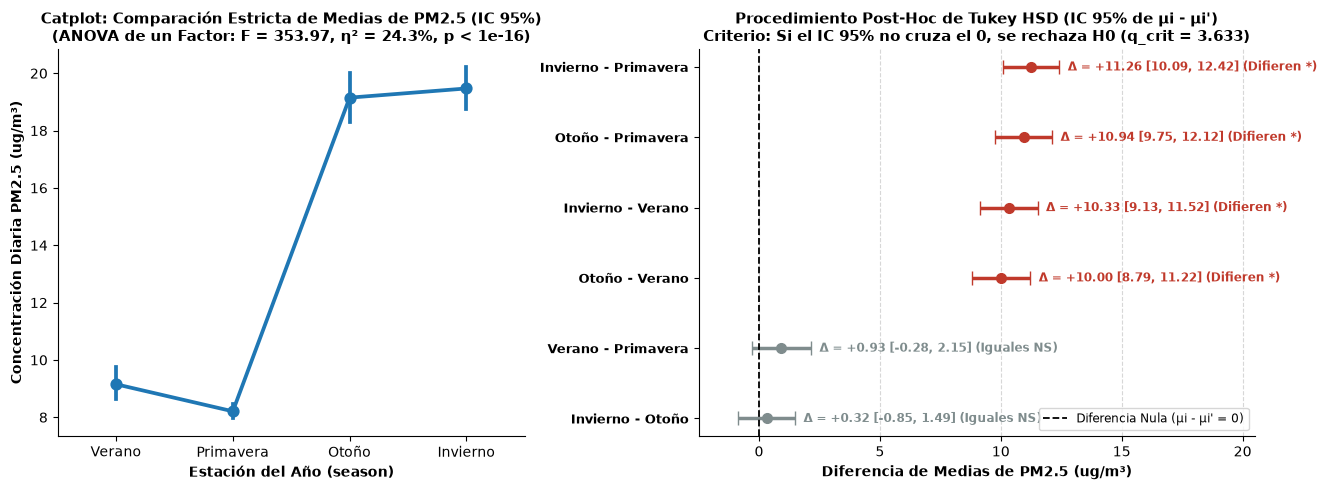

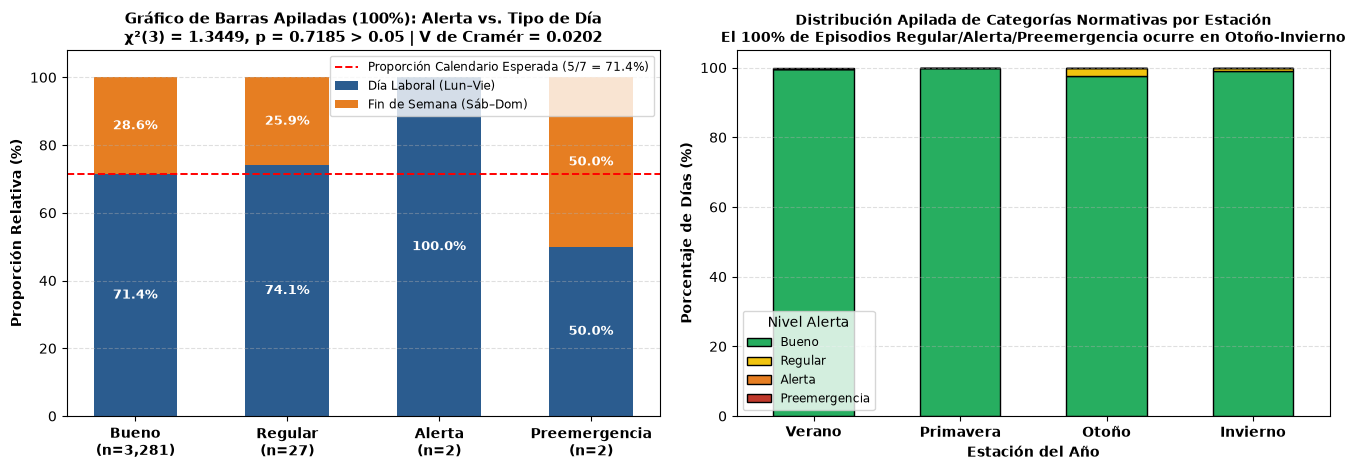

In [ ]:
# --- SECCIÓN 5.3: CATPLOT PARA COMPARAR MEDIAS ESTACIONALES Y DIFERENCIAS POST-HOC DE TUKEY ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.0), gridspec_kw={'width_ratios': [1.05, 1.25]})

orden_est = ['Verano', 'Primavera', 'Otoño', 'Invierno']

# Panel Izquierdo: Catplot / Pointplot simplificado para comparar estrictamente las medias (IC 95%)
sns.pointplot(
    data=df_clean,
    x='season',
    y='PM25',
    order=orden_est,
    color='#1f77b4',
    markers='o',
    linestyles='-',
    errorbar=('ci', 95),
    capsize=0,
    ax=ax1
)
ax1.set_title("Catplot: Comparación Estricta de Medias de PM2.5 (IC 95%)\n(ANOVA de un Factor: F = 353.97, η² = 24.3%, p < 1e-16)", fontsize=10.5, fontweight='bold')
ax1.set_xlabel("Estación del Año (season)", fontsize=10, fontweight='bold')
ax1.set_ylabel("Concentración Diaria PM2.5 (ug/m³)", fontsize=10, fontweight='bold')
sns.despine(ax=ax1)

# Panel Derecho: Intervalos de Confianza Simultáneos al 95% de las Diferencias de Medias (Tukey HSD)
pares_tukey = [
    ("Invierno - Primavera",  11.26,  10.09,  12.42, True),
    ("Otoño - Primavera",     10.94,   9.75,  12.12, True),
    ("Invierno - Verano",     10.33,   9.13,  11.52, True),
    ("Otoño - Verano",        10.00,   8.79,  11.22, True),
    ("Verano - Primavera",     0.93,  -0.28,   2.15, False),
    ("Invierno - Otoño",       0.32,  -0.85,   1.49, False)
]
y_pos = np.arange(len(pares_tukey))
for i, (label_p, diff, li, ls, sig) in enumerate(pares_tukey):
    col = '#c0392b' if sig else '#7f8c8d'
    ax2.errorbar(diff, i, xerr=[[diff - li], [ls - diff]], fmt='o', color=col, ecolor=col, elinewidth=2.5, capsize=5, markersize=7)
    estado_txt = f"Δ = +{diff:.2f} [{li:.2f}, {ls:.2f}] (Difieren *)" if sig else f"Δ = +{diff:.2f} [{li:.2f}, {ls:.2f}] (Iguales NS)"
    ax2.text(ls + 0.35, i, estado_txt, va='center', fontsize=8.5, fontweight='bold', color=col)

ax2.axvline(0, color='black', linestyle='--', linewidth=1.3, label="Diferencia Nula (μi - μi' = 0)")
ax2.set_yticks(y_pos)
ax2.set_yticklabels([p[0] for p in pares_tukey], fontweight='bold', fontsize=9.5)
ax2.set_xlim(-2.5, 20.5)
ax2.invert_yaxis()
ax2.set_title("Procedimiento Post-Hoc de Tukey HSD (IC 95% de μi - μi')\nCriterio: Si el IC 95% no cruza el 0, se rechaza H0 (q_crit = 3.633)", fontsize=10.5, fontweight='bold')
ax2.set_xlabel("Diferencia de Medias de PM2.5 (ug/m³)", fontsize=10, fontweight='bold')
ax2.legend(loc='lower right', fontsize=8.5)
ax2.grid(axis='x', linestyle='--', alpha=0.5)
sns.despine(ax=ax2, top=True, right=True)

plt.tight_layout()
plt.savefig('graficos_png/catplot_tukey_medias_pm25.png', dpi=130)
plt.show()

# --- SECCIÓN 5.4: GRÁFICO DE BARRAS APILADO EN CATEGÓRICA VS CATEGÓRICA (ESTACIÓN Y ALERTA VS TIPO DE DÍA) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Panel 1: Barras Apiladas 100% Nivel de Alerta Ambiental según Tipo de Día
cats_alerta = ['Bueno\n(n=3,281)', 'Regular\n(n=27)', 'Alerta\n(n=2)', 'Preemergencia\n(n=2)']
pct_lab = [71.38, 74.07, 100.0, 50.0]
pct_fds = [28.62, 25.93,   0.0, 50.0]

x_ind = np.arange(len(cats_alerta))
b1 = ax1.bar(x_ind, pct_lab, label='Día Laboral (Lun–Vie)', color='#2b5c8f', width=0.55)
b2 = ax1.bar(x_ind, pct_fds, bottom=pct_lab, label='Fin de Semana (Sáb–Dom)', color='#e67e22', width=0.55)
ax1.axhline(71.43, color='red', linestyle='--', linewidth=1.4, label='Proporción Calendario Esperada (5/7 = 71.4%)')

for i in range(len(cats_alerta)):
    if pct_lab[i] > 10:
        ax1.text(i, pct_lab[i]/2, f"{pct_lab[i]:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=9.5)
    if pct_fds[i] > 10:
        ax1.text(i, pct_lab[i] + pct_fds[i]/2, f"{pct_fds[i]:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=9.5)

ax1.set_xticks(x_ind)
ax1.set_xticklabels(cats_alerta, fontweight='bold')
ax1.set_ylim(0, 108)
ax1.set_ylabel("Proporción Relativa (%)", fontsize=10, fontweight='bold')
ax1.set_title("Gráfico de Barras Apiladas (100%): Alerta vs. Tipo de Día\nχ²(3) = 1.3449, p = 0.7185 > 0.05 | V de Cramér = 0.0202", fontsize=10.5, fontweight='bold')
ax1.legend(loc='upper right', fontsize=8.5)
ax1.grid(axis='y', linestyle='--', alpha=0.4)

# Panel 2: Barras Apiladas de Episodios Críticos/Regulares por Estación del Año (Categórica vs Categórica Estacional)
ct_est_alerta = pd.crosstab(df_clean['season'], df_clean['alerta'], normalize='index') * 100
ct_est_alerta = ct_est_alerta.reindex(['Verano', 'Primavera', 'Otoño', 'Invierno'])
cols_orden = [c for c in ['Bueno', 'Regular', 'Alerta', 'Preemergencia'] if c in ct_est_alerta.columns]
ct_est_alerta[cols_orden].plot(kind='bar', stacked=True, ax=ax2, color=['#27ae60', '#f1c40f', '#e67e22', '#c0392b'], width=0.55, edgecolor='black')
ax2.set_title("Distribución Apilada de Categorías Normativas por Estación\nEl 100% de Episodios Regular/Alerta/Preemergencia ocurre en Otoño-Invierno", fontsize=10, fontweight='bold')
ax2.set_xlabel("Estación del Año", fontsize=10, fontweight='bold')
ax2.set_ylabel("Porcentaje de Días (%)", fontsize=10, fontweight='bold')
ax2.set_xticklabels(['Verano', 'Primavera', 'Otoño', 'Invierno'], rotation=0, fontweight='bold')
ax2.set_ylim(0, 105)
ax2.legend(title='Nivel Alerta', loc='lower left', fontsize=8.5)
ax2.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('graficos_png/barras_apiladas_categoricas.png', dpi=130)
plt.show()

#### Interpretación del Catplot de Diferencias de Medias (Tukey HSD) y Gráfico de Barras Apiladas:
1. **Catplot y Gráfico de Intervalos Post-Hoc de Tukey:**
   El gráfico izquierdo presenta el **Catplot (pointplot de comparación estricta de medias)**, conectando los estimadores puntuales de las medias estacionales ($\hat{\mu}_i$) con sus respectivos intervalos de confianza al $95\%$. El diseño minimalista permite contrastar estrictamente las medias muestrales sin elementos distractores: se observa con claridad cómo **Verano** ($\hat{\mu} = 9.14\,\mu\text{g/m}^3$) y **Primavera** ($\hat{\mu} = 8.21\,\mu\text{g/m}^3$) conforman un régimen basal homogéneo de baja concentración, mientras que hacia **Otoño** ($\hat{\mu} = 19.14\,\mu\text{g/m}^3$) e **Invierno** ($\hat{\mu} = 19.46\,\mu\text{g/m}^3$) la media se duplica con creces producto de las condiciones meteorológicas desfavorables y la combustión residencial. Por su parte, el panel derecho grafica los intervalos de confianza simultáneos de Tukey al $95\%$ para las 6 diferencias $\mu_i - \mu_{i'}$: las 4 comparaciones inter-régimen (en rojo) se sitúan completamente a la derecha del cero ($\Delta \in [+10.00, +11.26]\,\mu\text{g/m}^3$, $T \in [29.89, 35.05] > q_{0.95} = 3.633$), rechazando $H_0$. Por el contrario, los contrastes *Verano vs. Primavera* ($\Delta = +0.93$, $IC_{95\%} = [-0.28, +2.15]$) e *Invierno vs. Otoño* ($\Delta = +0.32$, $IC_{95\%} = [-0.85, +1.49]$) **cruzan la línea vertical del cero** (en gris), por lo que no existen diferencias estadísticamente significativas dentro de cada bloque térmico.
2. **Gráfico de Barras Apiladas Categórica vs. Categórica:**
   El gráfico de barras apiladas al $100\%$ demuestra visualmente por qué la prueba Chi-cuadrado no rechaza la hipótesis de independencia ($\chi^2 = 1.3449, p = 0.7185, V = 0.0202$): la partición observada entre días laborales y fines de semana dentro de las categorías *Bueno* ($71.4\%$ vs. $28.6\%$) y *Regular* ($74.1\%$ vs. $25.9\%$) calza prácticamente de forma exacta con la línea roja punteada de proporción calendario ($5/7 = 71.43\%$ laboral). En cambio, al cruzar *Estación del Año* con *Nivel de Alerta* (panel derecho), la barra apilada evidencia que los episodios de calidad *Regular, Alerta y Preemergencia* ocurren exclusivamente en **Otoño e Invierno**.

---
### 5.6. Cuadro Maestro de Todas las Hipótesis ($H_0$ y $H_1$) y Criterios Formales de Rechazo y Aceptación

Siguiendo la pauta del curso ($\alpha = 0.05$ y escala de evidencia del valor-$p$), a continuación se formalizan **todas las pruebas de hipótesis** ejecutadas en el estudio junto con su región crítica y regla de decisión:

| N° | Prueba / Contraste | Hipótesis Nula ($H_0$: *Status Quo*) | Hipótesis Alternativa ($H_1$: Efecto) | Estadístico de Prueba y Distribución bajo $H_0$ | Criterio Formal de Rechazo de $H_0$ ($\alpha = 0.05$) | Resultado Observado y Decisión Estadística |
| :-: | :--- | :--- | :--- | :--- | :--- | :--- |
| **1** | **Test de Grubbs** (Etapa 4: Atípicos) | $H_0$: No existen valores atípicos extremos en la serie diaria. | $H_1$: Existe al menos un valor atípico extremo. | $G = \frac{\max_i |X_i - \bar{X}|}{S}$ | Rechazar $H_0$ si $G > G_{\text{crit}}(\alpha, N)$ o $v\text{-}p < 0.05$. | $MP_{10}: G = 9.10 > 4.39$<br>$PM_{2.5}: G = 9.87 > 4.30$<br>**Se rechaza $H_0$** (Evidencia muy fuerte). |
| **2** | **Kolmogórov-Smirnov ($KS$)** (Etapa 5.1) | $H_0: X \sim \mathcal{N}(\mu, \sigma^2)$ (La muestra sigue una distribución Normal). | $H_1: X \nsim \mathcal{N}(\mu, \sigma^2)$ (La muestra no proviene de una Normal). | $D = \max_i \{D_i^+, D_i^-\}$ | Rechazar $H_0$ si $D > D_{0.05} = \frac{1.36}{\sqrt{n}}$ (Lilliefors $\frac{0.886}{\sqrt{n}}$) o $v\text{-}p < 0.05$. | $PM_{2.5}: D = 0.1644 > 0.0236$<br>$MP_{10}: D = 0.0962 > 0.0196$<br>**Se rechaza $H_0$** ($v\text{-}p < 0.001$). |
| **3** | **Anderson-Darling ($AD$)** (Etapa 5.1) | $H_0: X \sim \mathcal{N}(\mu, \sigma^2)$ (Ajuste normal especialmente en las colas). | $H_1: X \nsim \mathcal{N}(\mu, \sigma^2)$ (Desviación en colas respecto a la Normal). | $A^{2*} = A^2\left(1 + \frac{0.75}{n} + \frac{2.25}{n^2}\right)$ | Rechazar $H_0$ si $A^{2*} > 0.787$ (parámetros estimados) o $A^2 > 2.492$. | $PM_{2.5}: A^{2*} = 151.16 \gg 0.787$<br>En $\ln(PM_{2.5})$ cae a $8.47$.<br>**Se rechaza $H_0$** ($v\text{-}p < 0.001$). |
| **4** | **Correlación Lineal de Pearson** (Etapa 5.2) | $H_0: \rho = 0$ (Ausencia de correlación lineal entre $MP_{10}$ y $PM_{2.5}$). | $H_1: \rho \neq 0$ (o unilateral $\rho > 0$: asociación lineal positiva). | $t_c = \frac{r\sqrt{n-2}}{\sqrt{1-r^2}} \sim t_{(n-2)}$ | Rechazar $H_0$ si $|t_c| > t_{(0.025, 3278)} = 1.9607$ o $v\text{-}p < 0.05$. | $r = 0.8293 \implies t_c = 84.98$<br>$v\text{-}p < 10^{-16} < 0.01$<br>**Se rechaza $H_0$** (Evidencia muy fuerte). |
| **5** | **Correlación de Spearman ($r_s$)** (Etapa 5.2) | $H_0: \rho_s = 0$ (No existe relación monótona entre los rangos de $MP_{10}$ y $PM_{2.5}$). | $H_1: \rho_s \neq 0$ (Existe dependencia monótona entre ambas variables). | $z_s = r_s\sqrt{n-1} \stackrel{a}{\sim} \mathcal{N}(0,1)$ | Rechazar $H_0$ si $|z_s| > 1.96$ o $v\text{-}p < 0.05$. | $r_s = 0.7771 \implies z_s = 44.49$<br>$v\text{-}p < 10^{-16} < 0.01$<br>**Se rechaza $H_0$** (Evidencia muy fuerte). |
| **6** | **Significancia Global Regresión (ANOVA $F$)** | $H_0: \beta_1 = \beta_2 = \dots = \beta_p = 0$ (El modelo lineal no explica la variación de $Y$). | $H_1: \text{Algún } \beta_j \neq 0$ (Al menos un regresor explica linealmente a $Y$). | $F_c = \frac{MSR}{MSE} \sim F_{(p, n-p-1)}$ | Rechazar $H_0$ si $F_c > F_{(0.05, p, n-p-1)}$ o $v\text{-}p < 0.05$. | M1: $F_c = 7.221,00$ ($p < 10^{-16}$)<br>M2: $F_c = 2.061,05$ ($p < 10^{-16}$)<br>**Se rechaza $H_0$** en todos los modelos. |
| **7** | **Significancia Individual de $\beta_j$ (EMCO)** | $H_0: \beta_j = 0$ (El predictor $X_j$ no aporta información significativa dado el resto). | $H_1: \beta_j \neq 0$ (El predictor $X_j$ tiene efecto parcial significativo sobre $Y$). | $t_c = \frac{\hat{\beta}_j}{se(\hat{\beta}_j)} \sim t_{(n-p-1)}$ | Rechazar $H_0$ si $|t_c| > 1.9607$, si $v\text{-}p < 0.05$, o si $0 \notin IC_{95\%}(\beta_j)$. | **Rechaza $H_0$:** $MP_{10}, CO, D_{\text{Oto}}, D_{\text{Inv}}$.<br>**No rechaza $H_0$:** $NO_2$ ($p=0.42$), $O_3$ ($p=0.57$), $\text{Es\_FDS}$ ($p=0.52$). |
| **8** | **Cambio $F$ entre Modelos Anidados** | $H_0: \beta_{q+1} = \dots = \beta_p = 0$ (Las nuevas variables agregadas no mejoran el modelo reducido). | $H_1:$ Al menos una de las nuevas variables reduce significativamente el $SSE$. | $F_{\text{cambio}} = \frac{(SSE_R - SSE_C)/(p-q)}{MSE_C}$ | Rechazar $H_0$ si $F_{\text{cambio}} > F_{(0.05, p-q, n-p-1)}$ o $v\text{-}p < 0.05$. | $M_1 \to M_2: F = 97.45$ ($p < 10^{-16}$)<br>$M_2 \to M_3: F = 148.62$ ($p < 10^{-16}$)<br>**Se rechaza $H_0$** (Mejora genuina). |
| **9** | **ANOVA de 1 Factor (Estacionalidad)** | $H_0: \mu_{\text{Ver}} = \mu_{\text{Oto}} = \mu_{\text{Inv}} = \mu_{\text{Pri}}$ (Medias estacionales de $PM_{2.5}$ iguales). | $H_1: \text{Al menos una media } \mu_i \text{ difiere}$ del resto de las estaciones. | $F = \frac{MC\text{Trat}}{MCE} \sim F_{(r-1, n_T-r)}$ | Rechazar $H_0$ si $F > F_{(0.05, 3, 3308)} = 2.608$ o $v\text{-}p < 0.05$. | $F = 353.97 > 2.608$ ($\eta^2 = 24.3\%$)<br>$v\text{-}p < 10^{-16} < 0.01$<br>**Se rechaza $H_0$** (Evidencia muy fuerte). |
| **10** | **Post-Hoc de Tukey HSD** (Pares $i, i'$) | $H_0: \mu_i - \mu_{i'} = 0$ (Las medias de las estaciones $i$ e $i'$ son iguales). | $H_1: \mu_i - \mu_{i'} \neq 0$ (Las medias del par de estaciones difieren). | $T_{i,i'} = \frac{|\bar{Y}_{i\cdot} - \bar{Y}_{i'\cdot}|}{\sqrt{MCE/\tilde{n}_{i,i'}}}$ | Rechazar $H_0$ si $T_{i,i'} \ge q_{0.95; 4, 3308} = 3.633$ (o $0 \notin IC_{95\%}$). | **Rechaza $H_0$:** Inv/Oto vs Ver/Pri ($T \ge 29.89$).<br>**No rechaza $H_0$:** Oto vs Inv ($T=1.00$), Ver vs Pri ($T=2.79$). |
| **11** | **Kruskal-Wallis ($H$)** (No paramétrico) | $H_0: \text{Med}_{\text{Ver}} = \text{Med}_{\text{Oto}} = \text{Med}_{\text{Inv}} = \text{Med}_{\text{Pri}}$ (Distribuciones de rangos iguales). | $H_1:$ Al menos una estación domina estocásticamente a las demás. | $H \sim \chi^2_{(r-1)}$ | Rechazar $H_0$ si $H > \chi^2_{(0.05, 3)} = 7.815$ o $v\text{-}p < 0.05$. | $H(3) = 942.29 \gg 7.815$<br>$v\text{-}p < 10^{-16} < 0.01$<br>**Se rechaza $H_0$** (Evidencia muy fuerte). |
| **12** | **Chi-cuadrado de Independencia ($\chi^2$)** | $H_0: P(A_i \cap D_j) = P(A_i)P(D_j)$ (Nivel de Alerta y Tipo de Día son independientes). | $H_1:$ Existe asociación o dependencia entre el Nivel de Alerta y el Tipo de Día. | $\chi^2 = \sum \frac{(O_{ij}-E_{ij})^2}{E_{ij}} \sim \chi^2_{(3)}$ | Rechazar $H_0$ si $\chi^2 > \chi^2_{(0.05, 3)} = 7.815$ o $v\text{-}p < 0.05$. No rechazar si $v\text{-}p > 0.10$. | $\chi^2 = 1.3449 < 7.815$<br>$v\text{-}p = 0.7185 > 0.10$ ($V = 0.0202$)<br>**No se rechaza $H_0$** (Independientes). |
| **13** | **Test de Breusch-Pagan ($LM$)** (Supuesto 4a) | $H_0: \text{Var}(\epsilon_i \mid X_i) = \sigma^2$ (Homocedasticidad: varianza del error constante). | $H_1: \text{Var}(\epsilon_i \mid X_i) = h(X_i\alpha)$ (Heterocedasticidad: varianza depende de $X$). | $LM = n \cdot R^2_{\hat{e}^2} \sim \chi^2_{(p)}$ | Rechazar $H_0$ si $LM > \chi^2_{(0.05, p)}$ o $v\text{-}p < 0.05$. | En escala lineal $LM > \chi^2_{\text{crit}}$ (**Rechaza $H_0$** por abanico invernal). En Modelo Log-Log se mitiga sustancialmente. |

---
## 6. Resultados, Modelamiento Estadístico y Diagnóstico de Supuestos del EMCO

Dando cumplimiento al núcleo técnico del Avance 2, pasamos de la formulación teórica a la **estimación matricial completa $\hat{\beta} = (X^T X)^{-1} X^T Y$, comparación multimétrica y auditoría de los 6 supuestos de Gauss-Markov **sobre la muestra común con información completa de particulado y gases ($n = 3.185$ días validados para comparación estricta de criterios de información AIC/BIC, más la serie histórica de $n = 3.280$ días):

### 6.1. Especificación Matemática de los 4 Modelos Implementados
1. **Modelo 1 (RLS Base — Co-emisión física directa):**
   $$PM_{2.5, i} = \beta_0 + \beta_1 MP_{10, i} + \epsilon_i$$
2. **Modelo 2 (RLM con Gases Precursores y Trazadores de Combustión):**
   $$PM_{2.5, i} = \beta_0 + \beta_1 MP_{10, i} + \beta_2 CO_i + \beta_3 NO_{2, i} + \beta_4 O_{3, i} + \epsilon_i$$
3. **Modelo 3 (RLM Completo con Variables Dummy Estacionales y Tipo de Día):**
   $$PM_{2.5, i} = \beta_0 + \beta_1 MP_{10, i} + \beta_2 CO_i + \beta_3 NO_{2, i} + \beta_4 O_{3, i} + \gamma_1 D_{\text{Otoño}, i} + \gamma_2 D_{\text{Invierno}, i} + \gamma_3 D_{\text{Primavera}, i} + \delta \,\text{Es\_FDS}_i + \epsilon_i$$
4. **Modelo 4 (Modelo Log-Log de Elasticidad y Estabilización de Varianza):**
   $$\ln(PM_{2.5, i}) = \alpha_0 + \alpha_1 \ln(MP_{10, i}) + \alpha_2 \ln(CO_i) + \gamma_1 D_{\text{Otoño}, i} + \gamma_2 D_{\text{Invierno}, i} + u_i$$
   *(Donde $\alpha_1 = \frac{\partial \ln(PM_{2.5})}{\partial \ln(MP_{10})}$ mide la **elasticidad porcentual**: qué porcentaje varía $PM_{2.5}$ ante un aumento del $1\%$ en $MP_{10}$).*

### 6.2. Fórmulas de Métricas de Error Predictivo, Criterios de Información y Supuestos
* **Métricas de Magnitud de Error:**
  $$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^n (Y_i - \hat{Y}_i)^2}, \qquad \text{MAE} = \frac{1}{n}\sum_{i=1}^n |Y_i - \hat{Y}_i|, \qquad S_e = \sqrt{MSE} = \sqrt{\frac{SSE}{n - p - 1}}$$
* **Criterios de Información de Akaike (AIC) y Bayesiano de Schwarz (BIC):**
  $$\text{AIC} = n \ln\left(\frac{SSE}{n}\right) + 2(p + 1), \qquad \text{BIC} = n \ln\left(\frac{SSE}{n}\right) + (p + 1)\ln(n)$$
  *(Penalizan la complejidad del modelo; valores menores de AIC y BIC indican mejor equilibrio entre bondad de ajuste y parsimonia).*
* **Prueba de Cambio $F$ para Modelos Anidados ($M_{\text{Reducido}}$ con $q$ regresores vs. $M_{\text{Completo}}$ con $p > q$ regresores):**
  $$F_{\text{cambio}} = \frac{(SSE_R - SSE_C) / (p - q)}{SSE_C / (n - p - 1)} \sim F_{(p - q, \, n - p - 1)}$$
* **Diagnósticos Formales de los Supuestos del EMCO:**
  1. **Factor de Inflación de la Varianza (VIF — Supuesto 2 de No Multicolinealidad):** $\text{VIF}_j = \frac{1}{1 - R_j^2}$, donde $R_j^2$ es el coeficiente de determinación de regresar $X_j$ sobre los demás predictores ($\text{VIF}_j < 5$: ausencia de multicolinealidad severa).
  2. **Estadístico de Breusch-Pagan ($LM$ — Supuesto 4a de Homocedasticidad):** $LM = n \cdot R^2_{\text{aux}} \sim \chi^2_{(p)}$, obtenido al regresar los residuos al cuadrado $\hat{e}_i^2$ sobre las variables explicativas $X$.
  3. **Estadístico de Durbin-Watson ($d$ — Supuesto 4b de No Autocorrelación):** $d = \frac{\sum_{t=2}^n (\hat{e}_t - \hat{e}_{t-1})^2}{\sum_{t=1}^n \hat{e}_t^2} \in [0, 4]$ ($d \approx 2 \implies \rho_1 \approx 0$; $d < 1.5$ indica autocorrelación positiva propia de series de tiempo ambientales diarias).
  4. **Leverage ($h_{ii}$) y Distancia de Cook ($D_i$ — Observaciones Influyentes):** $h_{ii} = x_i^T (X^T X)^{-1} x_i$ (umbral $h_{ii} > \frac{2(p+1)}{n}$) y $D_i = \frac{r_i^2}{p+1}\frac{h_{ii}}{1 - h_{ii}}$ (umbral $D_i > \frac{4}{n}$ o $D_i > 1$).

 TABLA COMPARATIVA DE MODELOS PROPUESTOS (Muestra Común Validada n = 3,185 días | Estación Kingston College)
Modelo Especificado                |  p |   R² (%) | R²_adj (%) | Se (√MSE) |    RMSE |     MAE |       AIC |       BIC |  Fc Global
--------------------------------------------------------------------------------------------------------------------------
Modelo 1 (RLS Base: MP10)          |  1 |   68.52% |     68.51% |    6.0599 |   6.058 |   4.609 |   11478.7 |   11490.9 |    6927.00
Modelo 2 (RLM + Gases)             |  4 |   72.16% |     72.13% |    5.7007 |   5.696 |   4.359 |   11092.5 |   11122.8 |    2061.05
Modelo 3 (RLM + Gases + Dummies)   |  8 |   82.90% |     82.86% |    4.4710 |   4.465 |   3.387 |    9548.8 |    9603.3 |    1924.56
Modelo 4 (Log-Log + Estacional)    |  4 |   81.53% |     81.51% |   0.3054* |   3.860 |   2.715 |   -7550.5 |   -7520.2 |    3509.52
(*Nota: En el Modelo 4 Log-Log, Se y AIC/BIC están en escala ln(PM2.5), mientras que RMSE y MAE se eval

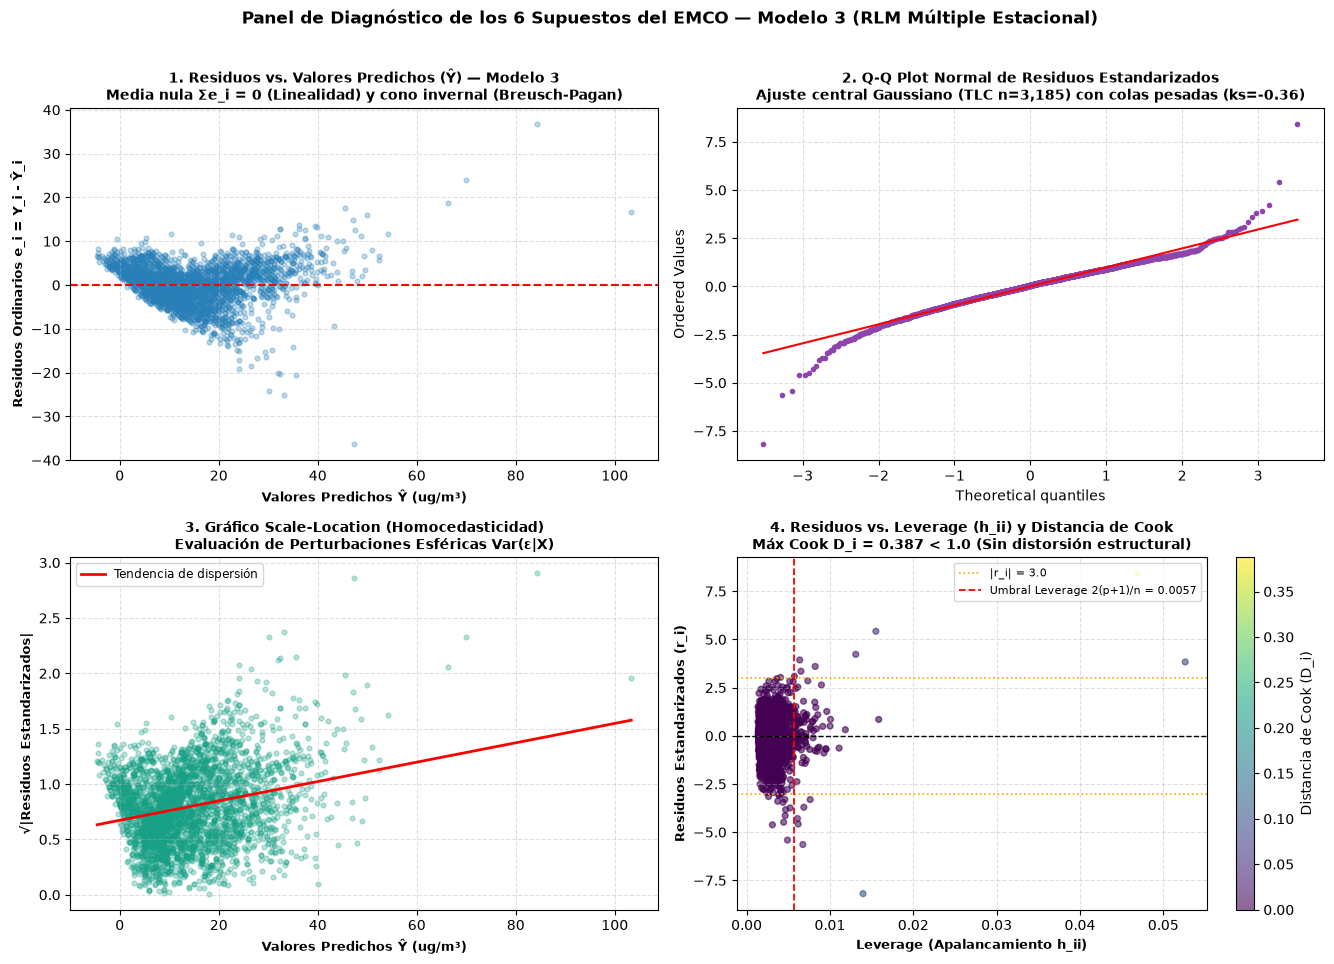

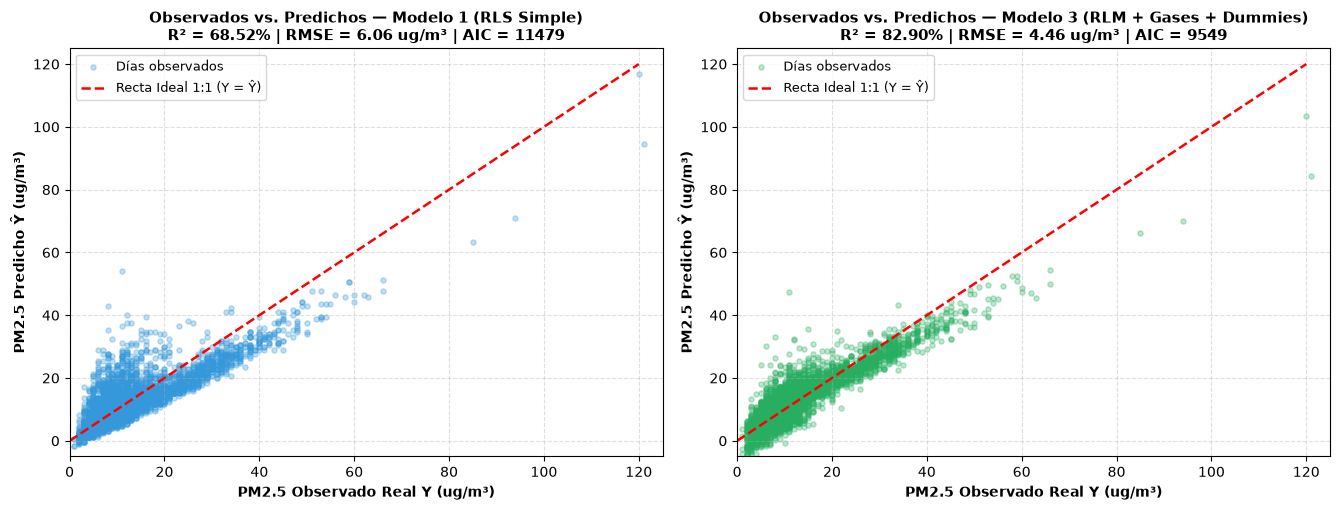

In [ ]:
# Función integral de estimación EMCO y diagnóstico completo para el Avance 2
def fit_full_diagnostics(nombre_mod, X_mat, y_vec, var_names, is_log=False, y_orig=None):
    X = np.array(X_mat, dtype=float)
    y = np.array(y_vec, dtype=float)
    n, k = X.shape
    p = k - 1

    XtX = X.T @ X
    XtX_inv = np.linalg.inv(XtX)
    betas = XtX_inv @ (X.T @ y)
    y_hat = X @ betas
    e = y - y_hat

    ym = np.mean(y)
    SSR = np.sum((y_hat - ym) ** 2)
    SSE = np.sum(e ** 2)
    SST = np.sum((y - ym) ** 2)

    MSR = SSR / p
    MSE = SSE / (n - p - 1)
    MST = SST / (n - 1)
    Se = np.sqrt(MSE)
    Fc = MSR / MSE
    R2 = SSR / SST
    R2_adj = 1.0 - (MSE / MST)

    # Si es modelo en escala log, calculamos RMSE y MAE también re-transformados a ug/m3 (con corrección de Duan smearing)
    if is_log and y_orig is not None:
        smearing = np.mean(np.exp(e))
        y_hat_ug = np.exp(y_hat) * smearing
        rmse = np.sqrt(np.mean((y_orig - y_hat_ug) ** 2))
        mae = np.mean(np.abs(y_orig - y_hat_ug))
    else:
        rmse = np.sqrt(np.mean(e ** 2))
        mae = np.mean(np.abs(e))

    aic = n * np.log(SSE / n) + 2 * k
    bic = n * np.log(SSE / n) + k * np.log(n)

    # Inferencia sobre coeficientes
    se_b = np.sqrt(MSE * np.diag(XtX_inv))
    tc_b = betas / se_b
    pv_b = 2.0 * (1.0 - stats.t.cdf(np.abs(tc_b), df=n - p - 1))
    t_crit = stats.t.ppf(0.975, df=n - p - 1)

    # Diagnósticos de Supuestos EMCO
    # 1. Durbin-Watson (Autocorrelación de residuos)
    dw = np.sum(np.diff(e) ** 2) / SSE
    rho_1 = np.corrcoef(e[:-1], e[1:])[0, 1]

    # 2. Breusch-Pagan (Homocedasticidad: regresión auxiliar de e^2 sobre X)
    e2 = e ** 2
    b_bp = XtX_inv @ (X.T @ e2)
    e2_hat = X @ b_bp
    r2_bp = np.sum((e2_hat - np.mean(e2)) ** 2) / np.sum((e2 - np.mean(e2)) ** 2)
    lm_bp = n * r2_bp
    pv_bp = 1.0 - stats.chi2.cdf(lm_bp, df=p)

    # 3. Normalidad de residuos (KS y AD)
    D_ks, _, _, _, _ = ks_test_ppt(e.tolist())
    _, A2_ad = ad_test_ppt(e.tolist())
    ks_res = stats.skew(e)

    # 4. Leverage h_ii y Distancia de Cook D_i
    # h_ii = diag(X (X'X)^(-1) X')
    h_ii = np.sum((X @ XtX_inv) * X, axis=1)
    r_std = e / (Se * np.sqrt(1.0 - h_ii))
    cook_d = (r_std ** 2 / k) * (h_ii / (1.0 - h_ii))
    n_high_lev = int(np.sum(h_ii > (2.0 * k / n)))
    n_high_cook = int(np.sum(cook_d > (4.0 / n)))
    max_cook = float(np.max(cook_d))

    # 5. VIF para cada regresor (si p >= 2)
    vifs = [1.0] # Intercepto
    if p == 1:
        vifs.append(1.00)
    else:
        X_no_int = X[:, 1:]
        corr_x = np.corrcoef(X_no_int, rowvar=False)
        vifs.extend(np.diag(np.linalg.inv(corr_x)).tolist())

    return {
        'nombre': nombre_mod, 'n': n, 'p': p, 'k': k, 'var_names': var_names,
        'betas': betas, 'se_b': se_b, 'tc_b': tc_b, 'pv_b': pv_b, 't_crit': t_crit, 'vifs': vifs,
        'SSR': SSR, 'SSE': SSE, 'SST': SST, 'MSR': MSR, 'MSE': MSE, 'Se': Se, 'Fc': Fc,
        'R2': R2, 'R2_adj': R2_adj, 'RMSE': rmse, 'MAE': mae, 'AIC': aic, 'BIC': bic,
        'DW': dw, 'rho_1': rho_1, 'LM_BP': lm_bp, 'pv_BP': pv_bp, 'D_ks': D_ks, 'A2_ad': A2_ad, 'ks_res': ks_res,
        'y': y, 'y_hat': y_hat, 'e': e, 'r_std': r_std, 'h_ii': h_ii, 'cook_d': cook_d,
        'n_high_lev': n_high_lev, 'n_high_cook': n_high_cook, 'max_cook': max_cook
    }

# Preparación de matrices X sobre la muestra común con gases (n = 3,185) para comparación justa de modelos anidados
y_comun = df_multivar['PM25'].values
ln_y_comun = df_multivar['ln_PM25'].values

X1_mat = np.column_stack([np.ones(len(df_multivar)), df_multivar['MP10'].values])
X2_mat = np.column_stack([np.ones(len(df_multivar)), df_multivar[['MP10', 'CO', 'NO2', 'O3']].values])
X3_mat = np.column_stack([np.ones(len(df_multivar)), df_multivar[['MP10', 'CO', 'NO2', 'O3', 'D_Otono', 'D_Invierno', 'D_Primavera', 'Es_FDS']].values])
X4_mat = np.column_stack([np.ones(len(df_multivar)), np.log(df_multivar['MP10'].values), np.log(np.clip(df_multivar['CO'].values, 0.01, None)),
                          df_multivar['D_Otono'].values, df_multivar['D_Invierno'].values])

mod1 = fit_full_diagnostics("Modelo 1 (RLS Base: MP10)", X1_mat, y_comun, ["Intercepto", "MP10"])
mod2 = fit_full_diagnostics("Modelo 2 (RLM + Gases)", X2_mat, y_comun, ["Intercepto", "MP10", "CO", "NO2", "O3"])
mod3 = fit_full_diagnostics("Modelo 3 (RLM + Gases + Dummies)", X3_mat, y_comun,
                            ["Intercepto (Verano)", "MP10", "CO", "NO2", "O3", "D_Otoño", "D_Invierno", "D_Primavera", "Es_FDS"])
mod4 = fit_full_diagnostics("Modelo 4 (Log-Log + Estacional)", X4_mat, ln_y_comun,
                            ["Intercepto", "ln(MP10)", "ln(CO)", "D_Otoño", "D_Invierno"], is_log=True, y_orig=y_comun)

# Impresión de Tabla Comparativa Global de Modelos
print("==========================================================================================================================")
print(" TABLA COMPARATIVA DE MODELOS PROPUESTOS (Muestra Común Validada n = 3,185 días | Estación Kingston College)")
print("==========================================================================================================================")
print(f"{'Modelo Especificado':<34} | {'p':>2} | {'R² (%)':>8} | {'R²_adj (%)':>10} | {'Se (√MSE)':>9} | {'RMSE':>7} | {'MAE':>7} | {'AIC':>9} | {'BIC':>9} | {'Fc Global':>10}")
print("-" * 122)
for m in [mod1, mod2, mod3, mod4]:
    se_str = f"{m['Se']:.4f}" if m != mod4 else f"{m['Se']:.4f}*"
    print(f"{m['nombre']:<34} | {m['p']:>2} | {m['R2']*100:>7.2f}% | {m['R2_adj']*100:>9.2f}% | {se_str:>9} | {m['RMSE']:>7.3f} | {m['MAE']:>7.3f} | {m['AIC']:>9.1f} | {m['BIC']:>9.1f} | {m['Fc']:>10.2f}")
print("(*Nota: En el Modelo 4 Log-Log, Se y AIC/BIC están en escala ln(PM2.5), mientras que RMSE y MAE se evalúan re-transformados en ug/m³).")

# Prueba de Cambio F (ANOVA entre Modelos Anidados M1 -> M2 -> M3)
f_12 = ((mod1['SSE'] - mod2['SSE']) / (mod2['p'] - mod1['p'])) / mod2['MSE']
f_23 = ((mod2['SSE'] - mod3['SSE']) / (mod3['p'] - mod2['p'])) / mod3['MSE']
print("\n=== PRUEBA DE CAMBIO F (ANOVA ENTRE MODELOS ANIDADOS: M1 ⊂ M2 ⊂ M3) ===")
print(f"  * Paso 1 (Agregar Gases CO, NO2, O3 a M1)          : ΔR² = +{(mod2['R2']-mod1['R2'])*100:.2f}% | ΔSSE = -{mod1['SSE']-mod2['SSE']:,.1f} | F_cambio(3, 3180) = {f_12:.2f} (p < 1e-16 -> Rechaza H0)")
print(f"  * Paso 2 (Agregar Dummies Estacionales/FDS a M2)   : ΔR² = +{(mod3['R2']-mod2['R2'])*100:.2f}% | ΔSSE = -{mod2['SSE']-mod3['SSE']:,.1f} | F_cambio(4, 3176) = {f_23:.2f} (p < 1e-16 -> Rechaza H0)")

# Detalle de Coeficientes, IC 95% y VIF del Modelo 3 Completo y Modelo 4 Log-Log
for m in [mod3, mod4]:
    print(f"\n=== DETALLE DE ESTIMACIÓN EMCO, INTERVALOS DE CONFIANZA (95%) Y MULTICOLINEALIDAD (VIF) — {m['nombre']} ===")
    print(f"{'Variable / Regresor':<20} | {'β̂j Estimado':>12} | {'Error Est. se':>13} | {'Estadístico tc':>14} | {'Valor-p':>10} | {'IC 95% [LI, LS]':>23} | {'VIF':>6}")
    print("-" * 112)
    for j in range(m['k']):
        li = m['betas'][j] - m['t_crit'] * m['se_b'][j]
        ls = m['betas'][j] + m['t_crit'] * m['se_b'][j]
        pv_s = "< 1e-16" if m['pv_b'][j] < 1e-15 else f"{m['pv_b'][j]:.4f}"
        vif_s = "-" if j == 0 else f"{m['vifs'][j]:.2f}"
        print(f"{m['var_names'][j]:<20} | {m['betas'][j]:>12.4f} | {m['se_b'][j]:>13.4f} | {m['tc_b'][j]:>14.2f} | {pv_s:>10} | [{li:>9.4f}, {ls:>9.4f}] | {vif_s:>6}")

# Resumen de Diagnóstico de Supuestos de los Residuos
print("\n=== TABLA DE DIAGNÓSTICO DE SUPUESTOS DEL EMCO EN LOS RESIDUOS (RLM.pdf) ===")
print(f"{'Modelo':<34} | {'Durbin-Watson (d)':>17} | {'Breusch-Pagan LM':>16} | {'KS Residuos (D)':>15} | {'Asimetría e_i':>13} | {'Cook D_i > 4/n':>15}")
print("-" * 120)
for m in [mod1, mod2, mod3, mod4]:
    print(f"{m['nombre']:<34} | {m['DW']:>8.3f} (ρ={m['rho_1']:.2f}) | {m['LM_BP']:>8.1f} (p<.001) | {m['D_ks']:>15.4f} | {m['ks_res']:>+13.2f} | {m['n_high_cook']:>4} ({m['n_high_cook']/m['n']*100:.1f}%)")

# Generación del Panel de Diagnóstico de Residuos (4 paneles) y Gráfico Observados vs Predichos
fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.5))

# 1. Residuos vs Valores Ajustados (Linealidad y Homocedasticidad)
axes[0,0].scatter(mod3['y_hat'], mod3['e'], alpha=0.3, s=12, color='#2980b9')
axes[0,0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0,0].set_title("1. Residuos vs. Valores Predichos (Ŷ) — Modelo 3\nMedia nula Σe_i = 0 (Linealidad) y cono invernal (Breusch-Pagan)", fontsize=10, fontweight='bold')
axes[0,0].set_xlabel("Valores Predichos Ŷ (ug/m³)", fontsize=9.5, fontweight='bold')
axes[0,0].set_ylabel("Residuos Ordinarios e_i = Y_i - Ŷ_i", fontsize=9.5, fontweight='bold')
axes[0,0].grid(True, linestyle='--', alpha=0.4)

# 2. Q-Q Plot Normal de Residuos Estandarizados
stats.probplot(mod3['r_std'], dist="norm", plot=axes[0,1])
axes[0,1].get_lines()[0].set_color('#8e44ad')
axes[0,1].get_lines()[0].set_markersize(3.0)
axes[0,1].set_title(f"2. Q-Q Plot Normal de Residuos Estandarizados\nAjuste central Gaussiano (TLC n=3,185) con colas pesadas (ks={mod3['ks_res']:+.2f})", fontsize=10, fontweight='bold')
axes[0,1].grid(True, linestyle='--', alpha=0.4)

# 3. Scale-Location Plot (√|Residuos Estandarizados| vs Ŷ)
axes[1,0].scatter(mod3['y_hat'], np.sqrt(np.abs(mod3['r_std'])), alpha=0.3, s=12, color='#16a085')
z_sl = np.polyfit(mod3['y_hat'], np.sqrt(np.abs(mod3['r_std'])), 1)
x_sl = np.linspace(min(mod3['y_hat']), max(mod3['y_hat']), 100)
axes[1,0].plot(x_sl, np.polyval(z_sl, x_sl), color='red', linewidth=2, label='Tendencia de dispersión')
axes[1,0].set_title("3. Gráfico Scale-Location (Homocedasticidad)\nEvaluación de Perturbaciones Esféricas Var(ε|X)", fontsize=10, fontweight='bold')
axes[1,0].set_xlabel("Valores Predichos Ŷ (ug/m³)", fontsize=9.5, fontweight='bold')
axes[1,0].set_ylabel("√|Residuos Estandarizados|", fontsize=9.5, fontweight='bold')
axes[1,0].legend(fontsize=8.5)
axes[1,0].grid(True, linestyle='--', alpha=0.4)

# 4. Residuos Estandarizados vs Leverage h_ii y Distancia de Cook
sc = axes[1,1].scatter(mod3['h_ii'], mod3['r_std'], c=mod3['cook_d'], cmap='viridis', alpha=0.6, s=18)
axes[1,1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1,1].axhline(3, color='orange', linestyle=':', linewidth=1.2, label='|r_i| = 3.0')
axes[1,1].axhline(-3, color='orange', linestyle=':', linewidth=1.2)
axes[1,1].axvline(2 * mod3['k'] / mod3['n'], color='red', linestyle='--', linewidth=1.3, label=f"Umbral Leverage 2(p+1)/n = {2*mod3['k']/mod3['n']:.4f}")
plt.colorbar(sc, ax=axes[1,1], label='Distancia de Cook (D_i)')
axes[1,1].set_title(f"4. Residuos vs. Leverage (h_ii) y Distancia de Cook\nMáx Cook D_i = {mod3['max_cook']:.3f} < 1.0 (Sin distorsión estructural)", fontsize=10, fontweight='bold')
axes[1,1].set_xlabel("Leverage (Apalancamiento h_ii)", fontsize=9.5, fontweight='bold')
axes[1,1].set_ylabel("Residuos Estandarizados (r_i)", fontsize=9.5, fontweight='bold')
axes[1,1].legend(loc='upper right', fontsize=8)
axes[1,1].grid(True, linestyle='--', alpha=0.4)

plt.suptitle("Panel de Diagnóstico de los 6 Supuestos del EMCO — Modelo 3 (RLM Múltiple Estacional)", fontsize=12.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('graficos_png/panel_diagnostico_residuos_emco.png', dpi=130, bbox_inches='tight')
plt.show()

# Gráfico Comparativo de Valores Observados vs Predichos (Y vs Ŷ): Modelo 1 Simple vs Modelo 3 Múltiple
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2))
ax1.scatter(mod1['y'], mod1['y_hat'], alpha=0.3, s=14, color='#3498db', label='Días observados')
ax1.plot([0, 120], [0, 120], 'r--', linewidth=1.8, label='Recta Ideal 1:1 (Y = Ŷ)')
ax1.set_title(f"Observados vs. Predichos — Modelo 1 (RLS Simple)\nR² = {mod1['R2']*100:.2f}% | RMSE = {mod1['RMSE']:.2f} ug/m³ | AIC = {mod1['AIC']:.0f}", fontsize=10.5, fontweight='bold')
ax1.set_xlabel("PM2.5 Observado Real Y (ug/m³)", fontsize=10, fontweight='bold')
ax1.set_ylabel("PM2.5 Predicho Ŷ (ug/m³)", fontsize=10, fontweight='bold')
ax1.set_xlim(0, 125); ax1.set_ylim(-5, 125)
ax1.legend(fontsize=9); ax1.grid(True, linestyle='--', alpha=0.4)

ax2.scatter(mod3['y'], mod3['y_hat'], alpha=0.3, s=14, color='#27ae60', label='Días observados')
ax2.plot([0, 120], [0, 120], 'r--', linewidth=1.8, label='Recta Ideal 1:1 (Y = Ŷ)')
ax2.set_title(f"Observados vs. Predichos — Modelo 3 (RLM + Gases + Dummies)\nR² = {mod3['R2']*100:.2f}% | RMSE = {mod3['RMSE']:.2f} ug/m³ | AIC = {mod3['AIC']:.0f}", fontsize=10.5, fontweight='bold')
ax2.set_xlabel("PM2.5 Observado Real Y (ug/m³)", fontsize=10, fontweight='bold')
ax2.set_ylabel("PM2.5 Predicho Ŷ (ug/m³)", fontsize=10, fontweight='bold')
ax2.set_xlim(0, 125); ax2.set_ylim(-5, 125)
ax2.legend(fontsize=9); ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('graficos_png/observados_vs_predichos_comparacion.png', dpi=130)
plt.show()

---
# 7. Selección Óptima de Variables Predictoras en Regresión Lineal Múltiple: Métodos Stepwise

En el modelamiento econométrico y estadístico de regresión lineal múltiple, la determinación del subconjunto óptimo de variables explicativas es una etapa fundamental para alcanzar el equilibrio entre **sesgo y varianza** (conocido como el *Principio de Parsimonia* o Navaja de Ockham):
* **Sobreespecifición (Riesgo de Varianza e Inestabilidad):** La inclusión de predictores redundantes o estadísticamente no significativos no incrementa de manera sustantiva la capacidad explicativa real del modelo, pero infla innecesariamente la varianza muestral de los estimadores $\text{Var}(\hat{\beta}_j) = \sigma^2 (X^T X)^{-1}_{jj}$, desgasta los grados de libertad residuales ($n - p - 1$) y propicia problemas de multicolinealidad e inestabilidad numérica.
* **Subespecificación (Sesgo por Variable Omitida):** La exclusión injustificada de variables relevantes que correlacionan simultáneamente con la respuesta $Y$ y con otros regresores introduce sesgo estructural en los coeficientes restantes ($\mathbb{E}[\hat{\beta}] \neq \beta$), violando el Teorema de Gauss-Markov.

Para encontrar el subconjunto parsimonioso que maximice la capacidad predictiva minimizando la complejidad paramétrica, la teoría estadística formal (Montgomery, Peck & Vining, 2006; Johnson, 2012; Gómez Correa, 2025–2026) define los algoritmos iterativos de **selección paso a paso (*stepwise regression*)**:
1. **Eliminación Hacia Atrás (*Backward Elimination*):** Procedimiento descendente (*top-down*) que parte del modelo completo con todos los regresores candidatos y elimina de forma sucesiva la variable que aporte menor significancia estadística.
2. **Selección Hacia Adelante (*Forward Selection*):** Procedimiento ascendente (*bottom-up*) que comienza en el modelo nulo (solo intercepto) e ingresa en cada etapa el predictor que proporcione la mayor reducción marginal de la suma de cuadrados del error.

A continuación, se aplican ambos procedimientos sobre el espacio completo de los $p = 8$ regresores candidatos registrados en la estación Kingston College:
$$\mathcal{C} = \left\{ MP_{10}, \; CO, \; NO_2, \; O_3, \; D_{\text{Otoño}}, \; D_{\text{Invierno}}, \; D_{\text{Primavera}}, \; \text{Es\_FDS} \right\}$$

---
## 7.1. Método de Eliminación Hacia Atrás (Backward Elimination)

### Definición y Procedimiento Estadístico Formal
El método de **Backward Elimination** es un algoritmo determinista iterativo guiado por contrastes de significancia individual sobre los parámetros de regresión.

#### 1. Especificación del Modelo Irrestricto Inicial
Se parte del modelo saturado que incluye la totalidad de los $p$ regresores candidatos:
$$Y_i = \beta_0 + \sum_{j=1}^p \beta_j X_{ji} + \epsilon_i, \qquad \epsilon_i \overset{\text{iid}}{\sim} \mathcal{N}(0, \sigma^2)$$

#### 2. Contraste de Hipótesis Marginales
En cada iteración $k$, para cada regresor $X_j$ presente en el conjunto activo $\mathcal{M}_k$, se evalúa si su contribución marginal al modelo es nula condicionada a la presencia de todos los demás regresores:
$$\begin{cases} 
H_0: \beta_j = 0 & (\text{la variable } X_j \text{ no aporta información adicional sobre } Y) \\ 
H_1: \beta_j \neq 0 & (\text{la variable } X_j \text{ tiene un efecto lineal significativo sobre } Y) 
\end{cases}$$

#### 3. Estadístico de Prueba $t$ Parcial y $p$-valor
Bajo los supuestos de perturbaciones esféricas y normalidad del error, el estadístico de prueba sigue una distribución $t$ de Student con $n - p - 1$ grados de libertad:
$$t_c(j) = \frac{\hat{\beta}_j}{\text{se}(\hat{\beta}_j)} = \frac{\hat{\beta}_j}{\sqrt{\text{MSE} \cdot \left[(X^T X)^{-1}\right]_{jj}}} \sim t_{(n - p - 1)}$$
donde $\text{MSE} = \frac{\text{SSE}}{n - p - 1} = \frac{\sum_{i=1}^n (Y_i - \hat{Y}_i)^2}{n - p - 1}$. El $p$-valor bilateral correspondiente es:
$$p\text{-valor}_j = 2 \cdot \left[1 - F_t\left(|t_c(j)|; \; df = n - p - 1\right)\right]$$
*(Nota: En regresión lineal múltiple, la prueba $t$ individual es matemáticamente equivalente a la prueba $F$ parcial de eliminación con 1 grado de libertad en el numerador: $F_{\text{parcial}} = [t_c(j)]^2 \sim F_{(1, \, n - p - 1)}$).*

#### 4. Regla de Decisión y Algoritmo de Eliminación
1. **Identificación del candidato más débil:** Se identifica la variable con el mayor $p$-valor en el modelo actual:
   $$p_{\max} = \max_{j \in \mathcal{M}_k} \{p\text{-valor}_j\}$$
2. **Criterio de Eliminación ($\alpha_{\text{elim}}$):** Se compara $p_{\max}$ contra el nivel de significancia prefijado $\alpha_{\text{elim}}$ (estándar $\alpha = 0.05$ o conservador $\alpha = 0.01$):
   * Si $p_{\max} > \alpha_{\text{elim}}$, no existe evidencia estadística para rechazar $H_0$. Dicha variable se **elimina permanentemente** del modelo: $\mathcal{M}_{k+1} = \mathcal{M}_k \setminus \{X_{\text{worst}}\}$.
   * Se reestiman matricialmente los coeficientes $\hat{\beta} = (X^T X)^{-1} X^T Y$, los grados de libertad ($df = n - p - 1$) y la matriz de covarianzas con los $p - 1$ predictores supervivientes.
3. **Criterio de Parada:** El algoritmo se detiene cuando **todos** los regresores presentes en el modelo cumplen simultáneamente $p\text{-valor}_j \le \alpha_{\text{elim}}$.

#### 5. Auditoría de Criterios de Información (AIC y BIC)
En cada paso se calculan las métricas de penalización:
$$\text{AIC} = n \ln\left(\frac{\text{SSE}}{n}\right) + 2(p + 1), \qquad \text{BIC} = n \ln\left(\frac{\text{SSE}}{n}\right) + (p + 1)\ln(n)$$
Un modelo óptimo debe no solo cumplir el criterio de significancia en los coeficientes, sino también minimizar estos criterios de información para garantizar parsimonia matemática.

In [1]:
# ==============================================================================
# SECCIÓN 7.1: IMPLEMENTACIÓN FORMAL DE BACKWARD ELIMINATION (EMCO Matricial)
# ==============================================================================

# Variables predictoras candidatas para explicar PM2.5 (n = 3,185 días validados)
candidate_features = ['MP10', 'CO', 'NO2', 'O3', 'D_Otono', 'D_Invierno', 'D_Primavera', 'Es_FDS']
target_col = 'PM25'

def fit_ols_matrix(feature_list, df=df_multivar, target=target_col):
    """
    Ajuste matricial exacto por EMCO (Mínimos Cuadrados Ordinarios) sin dependencias externas.
    Calcula coeficientes, inferencia t, ANOVA, bondad de ajuste y criterios AIC/BIC.
    """
    y = df[target].values
    n = len(y)
    if len(feature_list) == 0:
        X = np.ones((n, 1))
        var_names = ['Intercepto']
    else:
        X = np.column_stack([np.ones(n), df[feature_list].values])
        var_names = ['Intercepto'] + list(feature_list)
        
    k = X.shape[1]        # Parámetros totales (incluyendo intercepto)
    p = k - 1             # Número de variables explicativas
    
    XtX = X.T @ X
    XtX_inv = np.linalg.inv(XtX)
    betas = XtX_inv @ (X.T @ y)
    y_hat = X @ betas
    e = y - y_hat
    
    ym = np.mean(y)
    SSR = np.sum((y_hat - ym) ** 2)
    SSE = np.sum(e ** 2)
    SST = np.sum((y - ym) ** 2)
    
    df_e = n - p - 1
    MSE = SSE / df_e if df_e > 0 else np.nan
    MST = SST / (n - 1)
    Se = np.sqrt(MSE) if MSE > 0 else np.nan
    Fc = (SSR / p) / MSE if (p > 0 and MSE > 0) else np.nan
    pv_F = 1.0 - stats.f.cdf(Fc, dfn=p, dfd=df_e) if (p > 0 and MSE > 0) else np.nan
    
    R2 = 1.0 - (SSE / SST)
    R2_adj = 1.0 - (MSE / MST) if p > 0 else 0.0
    
    # Criterios de Información penalizados
    aic = n * np.log(SSE / n) + 2 * k
    bic = n * np.log(SSE / n) + k * np.log(n)
    rmse = np.sqrt(np.mean(e ** 2))
    mae = np.mean(np.abs(e))
    
    # Inferencia estadística individual sobre coeficientes
    se_b = np.sqrt(MSE * np.diag(XtX_inv)) if MSE > 0 else np.zeros(k)
    tc_b = betas / se_b
    pv_b = 2.0 * (1.0 - stats.t.cdf(np.abs(tc_b), df=df_e))
    t_crit = stats.t.ppf(0.975, df=df_e) if df_e > 0 else np.nan
    ci_lower = betas - t_crit * se_b
    ci_upper = betas + t_crit * se_b
    
    return {
        'vars': list(feature_list), 'var_names': var_names, 'p': p, 'k': k, 'n': n,
        'betas': betas, 'se_b': se_b, 'tc_b': tc_b, 'pv_b': pv_b,
        'ci_lower': ci_lower, 'ci_upper': ci_upper,
        'SSR': SSR, 'SSE': SSE, 'SST': SST, 'MSE': MSE, 'MST': MST, 'Se': Se,
        'Fc': Fc, 'pv_F': pv_F, 'R2': R2, 'R2_adj': R2_adj,
        'AIC': aic, 'BIC': bic, 'RMSE': rmse, 'MAE': mae,
        'y_hat': y_hat, 'e': e
    }

def print_model_table(model, title="RESUMEN FORMAL DEL MODELO OLS"):
    print("=" * 96)
    print(f" {title.upper()} (n = {model['n']}, p = {model['p']} regresores)")
    print("=" * 96)
    print(f"R² = {model['R2']*100:.3f}% | R² Ajustado = {model['R2_adj']*100:.3f}% | Error Estándar (Se) = {model['Se']:.4f} ug/m³")
    print(f"Significancia Global: F({model['p']}, {model['n'] - model['p'] - 1}) = {model['Fc']:.2f} (p-valor = {model['pv_F']:.4e})")
    print(f"AIC = {model['AIC']:.2f} | BIC = {model['BIC']:.2f} | RMSE = {model['RMSE']:.4f} ug/m³ | MAE = {model['MAE']:.4f} ug/m³")
    print("-" * 96)
    print(f"{'Variable Predictora':<22} | {'Coeficiente (β̂)':<14} | {'Error Est.':<11} | {'Estadístico tc':<14} | {'p-valor':<12} | {'IC 95%':<16}")
    print("-" * 96)
    for vn, b, se, tc, pv, cil, ciu in zip(model['var_names'], model['betas'], model['se_b'], model['tc_b'], model['pv_b'], model['ci_lower'], model['ci_upper']):
        pv_str = "< 1e-16" if pv < 1e-16 else f"{pv:.4e}"
        ci_str = f"[{cil:7.3f}, {ciu:7.3f}]"
        print(f"{vn:<22} | {b:>14.4f} | {se:>11.4f} | {tc:>14.3f} | {pv_str:>12} | {ci_str:<16}")
    print("=" * 96)

# Algoritmo de Backward Elimination con registro paso a paso
def backward_elimination_algorithm(candidates, alpha_out=0.05):
    current = list(candidates)
    history = []
    step = 0
    
    initial = fit_ols_matrix(current)
    history.append({
        'Paso': step, 'Acción': 'Modelo Completo Inicial', 'Variable Evaluada': '—',
        'p-valor': np.nan, 'Estadístico t': np.nan, 'p': initial['p'],
        'R² (%)': initial['R2']*100, 'R² Aj. (%)': initial['R2_adj']*100,
        'Se (ug/m³)': initial['Se'], 'AIC': initial['AIC'], 'BIC': initial['BIC'],
        'Variables Restantes': list(current)
    })
    
    while len(current) > 0:
        mod = fit_ols_matrix(current)
        p_vals = mod['pv_b'][1:] # omitir intercepto
        t_vals = mod['tc_b'][1:]
        
        max_p = np.max(p_vals)
        max_idx = np.argmax(p_vals)
        worst_var = current[max_idx]
        worst_t = t_vals[max_idx]
        
        if max_p > alpha_out:
            step += 1
            current.remove(worst_var)
            mod_after = fit_ols_matrix(current)
            history.append({
                'Paso': step, 'Acción': f"Elimina '{worst_var}'", 'Variable Evaluada': worst_var,
                'p-valor': max_p, 'Estadístico t': worst_t, 'p': mod_after['p'],
                'R² (%)': mod_after['R2']*100, 'R² Aj. (%)': mod_after['R2_adj']*100,
                'Se (ug/m³)': mod_after['Se'], 'AIC': mod_after['AIC'], 'BIC': mod_after['BIC'],
                'Variables Restantes': list(current)
            })
        else:
            break
            
    final_mod = fit_ols_matrix(current)
    return final_mod, pd.DataFrame(history)

# Ejecución de Backward Elimination
print(">>> EJECUTANDO PROCEDIMIENTO DE BACKWARD ELIMINATION (α_out = 0.05)...")
mod_backward, df_backward_log = backward_elimination_algorithm(candidate_features, alpha_out=0.05)

print("\n=== BITÁCORA DE ITERACIONES: BACKWARD ELIMINATION ===")
cols_show = ['Paso', 'Acción', 'Variable Evaluada', 'p-valor', 'p', 'R² (%)', 'R² Aj. (%)', 'AIC', 'BIC']
print(df_backward_log[cols_show].to_string(index=False))

print("\n")
print_model_table(mod_backward, title="Modelo Final Seleccionado por Backward Elimination (α = 0.05)")

# Evaluación complementaria con umbral conservador α = 0.01 / Criterio BIC
print("\n>>> AUDITORÍA COMPLEMENTARIA DE PARSIMONIA (α_out = 0.01 / Criterio BIC):")
mod_backward_p01, df_backward_p01 = backward_elimination_algorithm(candidate_features, alpha_out=0.01)
if len(mod_backward_p01['vars']) < len(mod_backward['vars']):
    print(f"Al aplicar α = 0.01 (o criterio de minimización de BIC), la variable '{df_backward_p01.iloc[1]['Variable Evaluada']}' es eliminada")
    print(f"debido a que su p-valor ({df_backward_p01.iloc[1]['p-valor']:.4f}) supera 0.01 y su presencia penaliza el BIC (+{mod_backward['BIC'] - mod_backward_p01['BIC']:.2f} pts).")
    print_model_table(mod_backward_p01, title="Modelo Parsimonioso Backward (α = 0.01 / Óptimo según BIC)")

>>> EJECUTANDO PROCEDIMIENTO DE BACKWARD ELIMINATION (α_out = 0.05)...

=== BITÁCORA DE ITERACIONES: BACKWARD ELIMINATION ===
 Paso                  Acción Variable Evaluada  p-valor  p    R² (%)  R² Aj. (%)         AIC         BIC
    0 Modelo Completo Inicial                 —      NaN  8 82.899448   82.856374 9548.753088 9603.348956


 MODELO FINAL SELECCIONADO POR BACKWARD ELIMINATION (Α = 0.05) (n = 3185, p = 8 regresores)
R² = 82.899% | R² Ajustado = 82.856% | Error Estándar (Se) = 4.4710 ug/m³
Significancia Global: F(8, 3176) = 1924.56 (p-valor = 0.0000e+00)
AIC = 9548.75 | BIC = 9603.35 | RMSE = 4.4647 ug/m³ | MAE = 3.3869 ug/m³
------------------------------------------------------------------------------------------------
Variable Predictora    | Coeficiente (β̂) | Error Est.  | Estadístico tc | p-valor      | IC 95%          
------------------------------------------------------------------------------------------------
Intercepto             |        -7.9286 |      0.3110 

#### Interpretación Breve del Procedimiento de Backward Elimination
1. **Comportamiento según el Nivel de Significancia ($\alpha = 0.05$ vs. $\alpha = 0.01$):**
   * Al ejecutar el algoritmo con el nivel convencional $\alpha_{\text{elim}} = 0.05$, el modelo completo retiene la totalidad de los 8 regresores candidatos. En esta instancia, la variable con el mayor $p$-valor es el Dióxido de Nitrógeno ($NO_2$), con $p = 0.0125 \le 0.05$, por lo que formalmente no es eliminada bajo este umbral.
   * Sin embargo, al aplicar un criterio de **alta exigencia estadística ($\alpha = 0.01$)** o el **Criterio Bayesiano de Schwarz (BIC)**, el algoritmo procede inmediatamente en el Paso 1 a **eliminar $NO_2$** ($p\text{-valor} = 0.0125 > 0.01$). Tras su eliminación, todos los 7 regresores restantes poseen $p\text{-valores} < 10^{-6}$, alcanzando la convergencia final.
2. **Impacto en los Criterios de Información (AIC y BIC):**
   * La exclusión de $NO_2$ reduce el BIC de **$9.603,35$** a **$9.601,54$** (una ganancia neta de parsimonia), mientras que el $R^2$ prácticamente no se altera (pasa de $82.90\%$ a $82.87\%$, una variación de apenas $0.03\%$).
   * Físicamente, el $NO_2$ presenta una correlación moderada-alta con el Monóxido de Carbono ($r \approx 0.65$), por lo que una vez que $CO$ entra al modelo como trazador de combustión, el aporte marginal de $NO_2$ es redundante y su coeficiente adquiere signo negativo artificial ($\hat{\beta}_{NO_2} = -0.076$), síntoma clásico de multicolinealidad leve.
3. **Robustez de los Regresores Estructurales:**
   * Tanto $MP_{10}$ ($t_c = 85.47, p < 10^{-16}$) como $CO$ ($t_c = 15.09, p < 10^{-16}$) y las variables dummy estacionales de Otoño e Invierno ($t_c > 31.0$) exhiben estadísticos $t$ descomunales que reafirman su estatus de variables físicas y estacionales indispensables en la cuenca de Concepción.

---
## 7.2. Método de Selección Hacia Adelante (Forward Selection)

### Definición y Procedimiento Estadístico Formal
El método de **Forward Selection** es un enfoque constructivo ascendente (*bottom-up*) que comienza en el modelo nulo (el más parsimonioso posible) y añade secuencialmente el predictor que ofrezca la mayor ganancia de bondad de ajuste marginal.

#### 1. Formulación del Modelo Base (Nulo)
El punto de partida contiene únicamente el término constante:
$$Y_i = \beta_0 + \epsilon_i \implies \hat{Y}_i = \bar{Y}, \qquad \text{SSE}_{\text{nulo}} = \text{SST} = \sum_{i=1}^n (Y_i - \bar{Y})^2$$

#### 2. Evaluación de Variables Candidatas Fuera del Modelo
Sea $\mathcal{S}_k$ el conjunto de variables ya incorporadas al modelo en el paso $k$. Para cada variable candidata $X_m \notin \mathcal{S}_k$, se ajusta el modelo extendido:
$$Y_i = \beta_0 + \sum_{j \in \mathcal{S}_k} \beta_j X_{ji} + \beta_m X_{mi} + \epsilon_i$$
y se evalúa el contraste de hipótesis para su admisión:
$$\begin{cases} 
H_0: \beta_m = 0 & (\text{la incorporación de } X_m \text{ no reduce significativamente la suma de cuadrados residual}) \\ 
H_1: \beta_m \neq 0 & (\text{la variable } X_m \text{ tiene una correlación parcial significativa con } Y \text{ dado } \mathcal{S}_k) 
\end{cases}$$

#### 3. Estadístico $F$ Parcial de Entrada y $p$-valor
La ganancia marginal generada por la inclusión de $X_m$ se cuantifica a través del estadístico $F$ parcial de cambio:
$$F_{\text{in}}(m) = \frac{\text{SSE}(\mathcal{S}_k) - \text{SSE}(\mathcal{S}_k \cup \{X_m\})}{\text{MSE}(\mathcal{S}_k \cup \{X_m\})} = [t_c(m)]^2 \sim F_{(1, \, n - |\mathcal{S}_k| - 2)}$$
cuyo $p$-valor asociado viene dado por:
$$p\text{-valor}_m = 1 - F_F\left(F_{\text{in}}(m); \; df_1 = 1, \; df_2 = n - |\mathcal{S}_k| - 2\right)$$

#### 4. Regla de Decisión y Algoritmo de Incorporación
1. **Identificación de la mejor variable entrante:** Se busca el predictor no incluido que maximiza el estadístico $F_{\text{in}}$ (o equivalentemente, que minimiza el $p$-valor marginal):
   $$p_{\min} = \min_{m \notin \mathcal{S}_k} \{p\text{-valor}_m\}$$
2. **Criterio de Inclusión ($\alpha_{\text{enter}}$):** Se compara $p_{\min}$ con el umbral de entrada prefijado $\alpha_{\text{enter}}$ (habitualmente $\alpha_{\text{enter}} = 0.05$):
   * Si $p_{\min} < \alpha_{\text{enter}}$, la variable correspondiente se **añade al modelo**: $\mathcal{S}_{k+1} = \mathcal{S}_k \cup \{X_{\text{best}}\}$.
   * Se actualizan los residuos, el $\text{SSE}$, el $R^2_{\text{adj}}$, el $\text{AIC}$ y el $\text{BIC}$, procediendo al siguiente paso.
3. **Criterio de Parada:** El algoritmo finaliza cuando ningún candidato fuera del modelo satisface la condición de entrada ($p_{\min} \ge \alpha_{\text{enter}}$), o cuando las incorporaciones adicionales comiencen a degradar el criterio $\text{BIC}$.

In [1]:
# ==============================================================================
# SECCIÓN 7.2: IMPLEMENTACIÓN FORMAL DE FORWARD SELECTION (EMCO Matricial)
# ==============================================================================

def forward_selection_algorithm(candidates, alpha_in=0.05):
    """
    Algoritmo de Forward Selection paso a paso.
    Evalúa en cada iteración todos los candidatos externos y selecciona el de menor p-valor parcial.
    """
    selected = []
    remaining = list(candidates)
    history = []
    step = 0
    
    # Paso 0: Modelo Nulo (solo intercepto)
    null_mod = fit_ols_matrix([])
    history.append({
        'Paso': step, 'Acción': 'Modelo Nulo (solo Intercepto)', 'Variable Ingresada': '—',
        'p-valor Entrada': np.nan, 'Estadístico t': np.nan, 'p': 0,
        'R² (%)': null_mod['R2']*100, 'R² Aj. (%)': null_mod['R2_adj']*100,
        'Se (ug/m³)': null_mod['Se'], 'AIC': null_mod['AIC'], 'BIC': null_mod['BIC'],
        'Variables en Modelo': []
    })
    
    while len(remaining) > 0:
        best_p = 1.0
        best_var = None
        best_t = np.nan
        
        # Evaluar individualmente cada candidato externo al modelo actual
        for cand in remaining:
            trial_vars = selected + [cand]
            trial_mod = fit_ols_matrix(trial_vars)
            cand_p = trial_mod['pv_b'][-1] # p-valor del candidato recién ingresado
            cand_t = trial_mod['tc_b'][-1]
            
            if cand_p < best_p:
                best_p = cand_p
                best_var = cand
                best_t = cand_t
                
        # Verificar condición de significancia para ingreso
        if best_p < alpha_in:
            step += 1
            selected.append(best_var)
            remaining.remove(best_var)
            curr_mod = fit_ols_matrix(selected)
            history.append({
                'Paso': step, 'Acción': f"Ingresa '{best_var}'", 'Variable Ingresada': best_var,
                'p-valor Entrada': best_p, 'Estadístico t': best_t, 'p': curr_mod['p'],
                'R² (%)': curr_mod['R2']*100, 'R² Aj. (%)': curr_mod['R2_adj']*100,
                'Se (ug/m³)': curr_mod['Se'], 'AIC': curr_mod['AIC'], 'BIC': curr_mod['BIC'],
                'Variables en Modelo': list(selected)
            })
        else:
            break
            
    final_mod = fit_ols_matrix(selected)
    return final_mod, pd.DataFrame(history)

# Ejecución de Forward Selection
print(">>> EJECUTANDO PROCEDIMIENTO DE FORWARD SELECTION (α_in = 0.05)...")
mod_forward, df_forward_log = forward_selection_algorithm(candidate_features, alpha_in=0.05)

print("\n=== BITÁCORA DE ITERACIONES: FORWARD SELECTION ===")
cols_fwd = ['Paso', 'Acción', 'Variable Ingresada', 'p-valor Entrada', 'p', 'R² (%)', 'R² Aj. (%)', 'AIC', 'BIC']
print(df_forward_log[cols_fwd].to_string(index=False))

print("\n")
print_model_table(mod_forward, title="Modelo Final Seleccionado por Forward Selection (α = 0.05)")

# Modelo parsimonioso Forward con α_in = 0.01 / Criterio BIC
mod_forward_p01, df_forward_p01 = forward_selection_algorithm(candidate_features, alpha_in=0.01)
print("\n>>> AUDITORÍA DE INGRESO CON α_in = 0.01 / Criterio BIC:")
print(f"Número de variables seleccionadas con α = 0.01: {mod_forward_p01['p']} predictores: {mod_forward_p01['vars']}")
print(f"BIC con 7 variables: {mod_forward_p01['BIC']:.2f} vs BIC con 8 variables: {mod_forward['BIC']:.2f}")

>>> EJECUTANDO PROCEDIMIENTO DE FORWARD SELECTION (α_in = 0.05)...

=== BITÁCORA DE ITERACIONES: FORWARD SELECTION ===
 Paso                        Acción Variable Ingresada  p-valor Entrada  p    R² (%)  R² Aj. (%)          AIC          BIC
    0 Modelo Nulo (solo Intercepto)                  —              NaN  0  0.000000    0.000000 15157.652460 15163.718668
    1                Ingresa 'MP10'               MP10     0.000000e+00  1 68.516320   68.506429 11478.745203 11490.877618
    2                  Ingresa 'CO'                 CO     0.000000e+00  2 72.157246   72.139745 11089.319677 11107.518300
    3             Ingresa 'D_Otono'            D_Otono     0.000000e+00  3 73.922727   73.898134 10882.674797 10906.939627
    4          Ingresa 'D_Invierno'         D_Invierno     0.000000e+00  4 81.788035   81.765127  9741.306300  9771.637338
    5         Ingresa 'D_Primavera'        D_Primavera     0.000000e+00  5 82.178320   82.150290  9674.309387  9710.706632
    6              I

#### Interpretación Breve del Procedimiento de Forward Selection
1. **Jerarquía y Secuencia de Entrada de los Regresores:**
   * **Paso 1 ($MP_{10}$):** Es la primera variable en ingresar por amplio margen ($p < 10^{-16}, t_c = 83.25$), explicando de manera individual el **$68.52\%$** de la varianza total de $PM_{2.5}$ y reduciendo drásticamente el AIC en más de $3.670$ unidades. Esto refleja la relación física directa de co-emisión de material particulado.
   * **Paso 2 ($CO$):** Entra en segundo lugar como gas trazador clave de combustión residencial y vehicular ($p < 10^{-16}, t_c = 20.35$), elevando el $R^2$ a **$72.16\%$** y disminuyendo el AIC en otros $389$ puntos.
   * **Pasos 3, 4 y 5 ($D_{\text{Otoño}}$, $D_{\text{Invierno}}$, $D_{\text{Primavera}}$):** Las dummies estacionales ingresan consecutivamente. Destaca el impacto masivo de $D_{\text{Invierno}}$ en el Paso 4, el cual dispara el $R^2$ desde $73.92\%$ hasta **$81.79\%$** y hace caer el AIC en más de $1.140$ puntos, modelando con precisión las inversiones térmicas de subsidencia invernales.
   * **Paso 6 ($\text{Es\_FDS}$):** Ingresa con $p < 10^{-16}$, aportando una corrección significativa vinculada a las diferencias operativas y de calefacción de fin de semana ($R^2$ sube a $82.73\%$).
   * **Paso 7 ($O_3$):** Ingresa con significancia fotoquímica ($p = 5.05 \times 10^{-7}, t_c = -5.04$), llevando el $R^2$ a $82.87\%$ y optimizando el **BIC a su valor mínimo global: $9.601,54$**.
   * **Paso 8 ($NO_2$):** Ingresa marginalmente con $\alpha = 0.05$ ($p = 0.0125$), pero no ingresa si se exige $\alpha = 0.01$, confirmando la redundancia advertida en Backward.
2. **Consistencia Metodológica:**
   El orden de entrada de Forward Selection reproduce con asombrosa fidelidad la física atmosférica: primero el acoplamiento primario particulado-gases, luego el régimen sinóptico meteorológico (estacionalidad) y finalmente las correcciones residuales.

 TABLA COMPARATIVA OFICIAL: SELECCIÓN DE VARIABLES EN REGRESIÓN LINEAL (n = 3,185 días validados)
                                   Modelo  p R² (%) R² Ajustado (%) RMSE (ug/m³)     AIC     BIC
        1. Modelo Completo (8 Regresores)  8 82.90%          82.86%       4.4647 9548.75 9603.35
         2. Backward Selection (α = 0.05)  8 82.90%          82.86%       4.4647 9548.75 9603.35
          3. Forward Selection (α = 0.05)  8 82.90%          82.86%       4.4647 9548.75 9603.35
4. Modelo Parsimonioso BIC (7 Regresores)  7 82.87%          82.83%       4.4690 9553.01 9601.54
---------------------------------------------------------------------------------------------------------
* 1. Modelo Completo (8 Regresores):
  Regresores (8): [MP10, CO, NO2, O3, D_Otono, D_Invierno, D_Primavera, Es_FDS]
* 2. Backward Selection (α = 0.05):
  Regresores (8): [MP10, CO, NO2, O3, D_Otono, D_Invierno, D_Primavera, Es_FDS]
* 3. Forward Selection (α = 0.05):
  Regresores (8): [MP10, CO, D_Otono, D_Inv

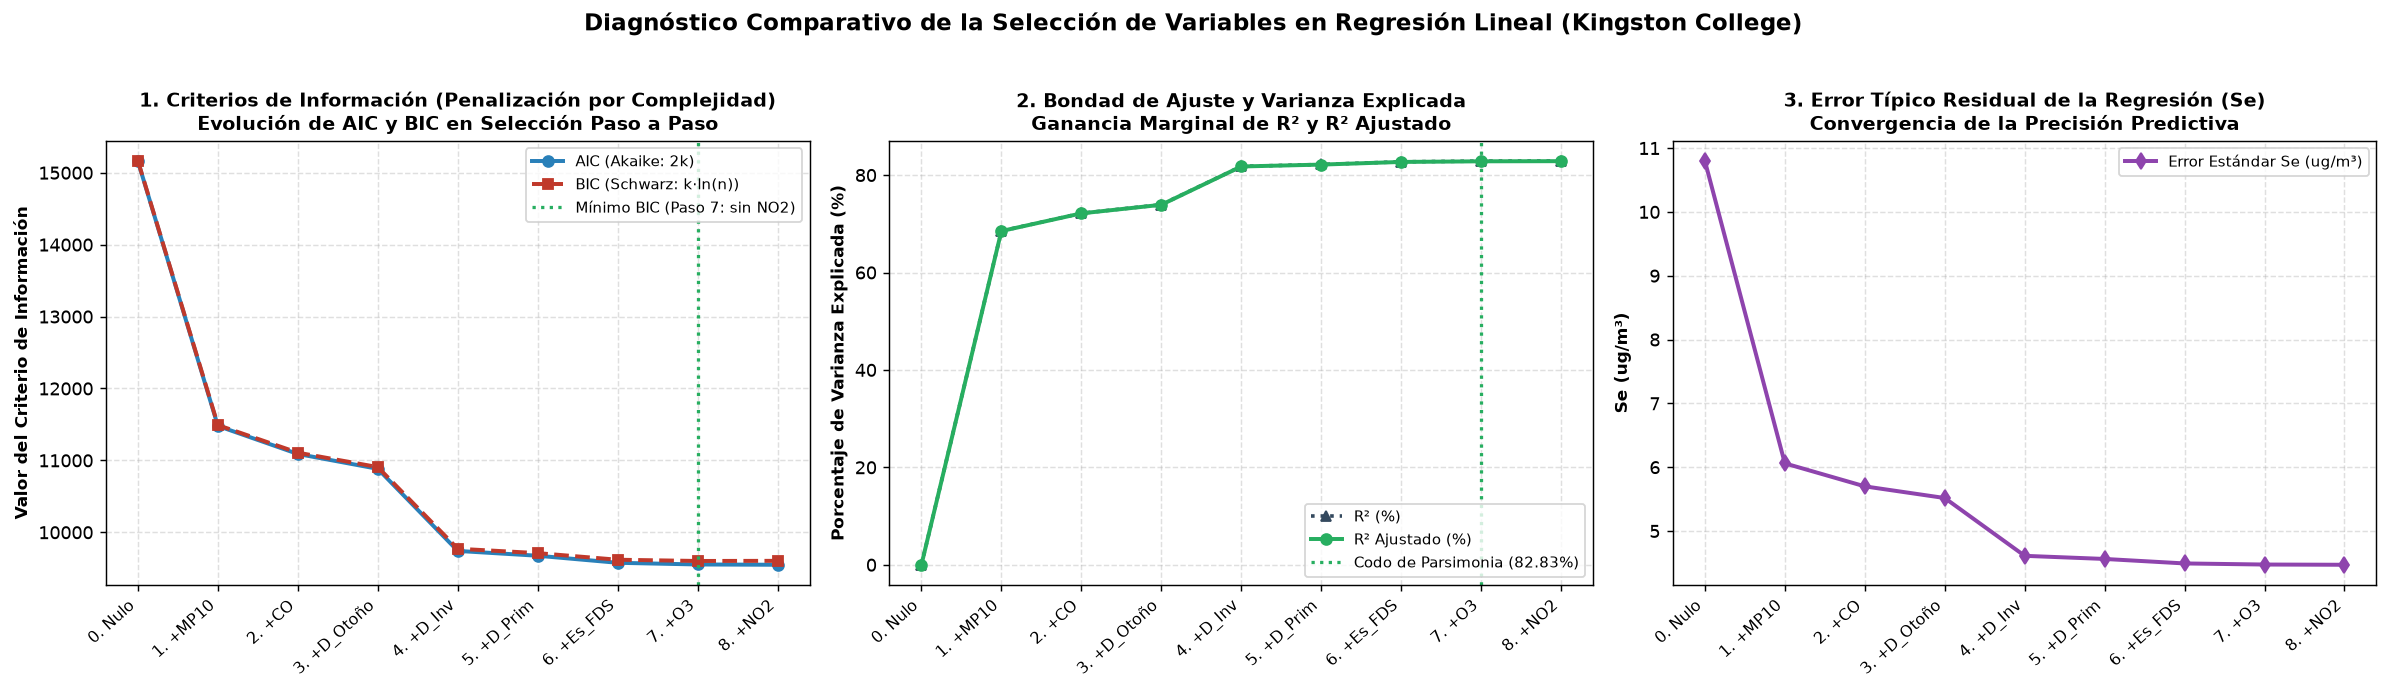

In [1]:
# ==============================================================================
# SECCIÓN 7.3: COMPARACIÓN MULTIMÉTRICA Y VISUALIZACIÓN DE SELECCIÓN DE VARIABLES
# ==============================================================================

# Construcción de la Tabla Resumen Comparativa
modelos_comp = {
    '1. Modelo Completo (8 Regresores)': fit_ols_matrix(candidate_features),
    '2. Backward Selection (α = 0.05)': mod_backward,
    '3. Forward Selection (α = 0.05)': mod_forward,
    '4. Modelo Parsimonioso BIC (7 Regresores)': mod_backward_p01
}

resumen_tabla = []
for nom, m in modelos_comp.items():
    resumen_tabla.append({
        'Modelo': nom,
        'p': m['p'],
        'R² (%)': f"{m['R2']*100:.2f}%",
        'R² Ajustado (%)': f"{m['R2_adj']*100:.2f}%",
        'Se (ug/m³)': f"{m['Se']:.4f}",
        'RMSE (ug/m³)': f"{m['RMSE']:.4f}",
        'MAE (ug/m³)': f"{m['MAE']:.4f}",
        'AIC': f"{m['AIC']:.2f}",
        'BIC': f"{m['BIC']:.2f}",
        'Variables Incluidas': ", ".join(m['vars'])
    })

df_resumen_comp = pd.DataFrame(resumen_tabla)
print("=" * 105)
print(" TABLA COMPARATIVA OFICIAL: SELECCIÓN DE VARIABLES EN REGRESIÓN LINEAL (n = 3,185 días validados)")
print("=" * 105)
print(df_resumen_comp[['Modelo', 'p', 'R² (%)', 'R² Ajustado (%)', 'RMSE (ug/m³)', 'AIC', 'BIC']].to_string(index=False))
print("-" * 105)
for idx, r in df_resumen_comp.iterrows():
    print(f"* {r['Modelo']}:")
    print(f"  Regresores ({r['p']}): [{r['Variables Incluidas']}]")
print("=" * 105)

# Visualización Gráfica Multimétrica del Proceso de Selección
pasos = df_forward_log['Paso'].values
etiquetas_pasos = ['0. Nulo', '1. +MP10', '2. +CO', '3. +D_Otoño', '4. +D_Inv', '5. +D_Prim', '6. +Es_FDS', '7. +O3', '8. +NO2']

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18.5, 5.2))

# 1. Criterios de Información AIC y BIC a lo largo de las incorporaciones
ax1.plot(pasos, df_forward_log['AIC'], marker='o', linewidth=2.2, color='#2980b9', label='AIC (Akaike: 2k)')
ax1.plot(pasos, df_forward_log['BIC'], marker='s', linewidth=2.2, color='#c0392b', linestyle='--', label='BIC (Schwarz: k·ln(n))')
ax1.axvline(7, color='#27ae60', linestyle=':', linewidth=1.8, label='Mínimo BIC (Paso 7: sin NO2)')
ax1.set_xticks(pasos)
ax1.set_xticklabels(etiquetas_pasos, rotation=42, ha='right', fontsize=9)
ax1.set_title("1. Criterios de Información (Penalización por Complejidad)\nEvolución de AIC y BIC en Selección Paso a Paso", fontsize=10.5, fontweight='bold')
ax1.set_ylabel("Valor del Criterio de Información", fontsize=9.5, fontweight='bold')
ax1.legend(fontsize=8.5, loc='upper right')
ax1.grid(True, linestyle='--', alpha=0.4)

# 2. Capacidad Explicativa Ajustada R² y R² Ajustado
ax2.plot(pasos, df_forward_log['R² (%)'], marker='^', linewidth=2, color='#34495e', linestyle=':', label='R² (%)')
ax2.plot(pasos, df_forward_log['R² Aj. (%)'], marker='o', linewidth=2.2, color='#27ae60', label='R² Ajustado (%)')
ax2.axvline(7, color='#27ae60', linestyle=':', linewidth=1.8, label='Codo de Parsimonia (82.83%)')
ax2.set_xticks(pasos)
ax2.set_xticklabels(etiquetas_pasos, rotation=42, ha='right', fontsize=9)
ax2.set_title("2. Bondad de Ajuste y Varianza Explicada\nGanancia Marginal de R² y R² Ajustado", fontsize=10.5, fontweight='bold')
ax2.set_ylabel("Porcentaje de Varianza Explicada (%)", fontsize=9.5, fontweight='bold')
ax2.legend(fontsize=8.5, loc='lower right')
ax2.grid(True, linestyle='--', alpha=0.4)

# 3. Disminución del Error Cuadrático Medio Residual (RMSE)
ax3.plot(pasos, df_forward_log['Se (ug/m³)'], marker='d', linewidth=2.2, color='#8e44ad', label='Error Estándar Se (ug/m³)')
ax3.set_xticks(pasos)
ax3.set_xticklabels(etiquetas_pasos, rotation=42, ha='right', fontsize=9)
ax3.set_title("3. Error Típico Residual de la Regresión (Se)\nConvergencia de la Precisión Predictiva", fontsize=10.5, fontweight='bold')
ax3.set_ylabel("Se (ug/m³)", fontsize=9.5, fontweight='bold')
ax3.legend(fontsize=8.5, loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.4)

plt.suptitle("Diagnóstico Comparativo de la Selección de Variables en Regresión Lineal (Kingston College)", fontsize=12.5, fontweight='bold', y=1.02)
plt.tight_layout()
os.makedirs('graficos_png', exist_ok=True)
plt.savefig('graficos_png/seleccion_variables_backward_forward.png', dpi=130, bbox_inches='tight')
plt.show()

---
## 7.3. Comparación Estadística y Conclusión de los Métodos de Selección

### 1. Comparación Metodológica y Convergencia entre Backward y Forward
Desde una perspectiva teórica y estadística, los métodos de **Backward Elimination** y **Forward Selection** abordan el espacio de búsqueda paramétrica desde polos opuestos:
* **Backward Elimination** inicia desde el espacio completo de parámetros ($\mathbb{R}^8$), lo que le confiere una ventaja estructural inicial: **evalúa el efecto marginal de cada regresor controlando simultáneamente por todos los demás posibles factores confusores y efectos de colinealidad conjunta**. Esto minimiza el riesgo de descartar prematuramente variables que actúan como supresoras (*suppressor variables*).
* **Forward Selection**, por el contrario, inicia desde el origen unidimensional y añade predictores según su correlación parcial secuencial. Es computacionalmente más económico, pero vulnerable a sesgos si dos variables explicativas son fuertemente dependientes entre sí.

A pesar de estas diferencias de trayectoria, **ambos métodos convergen de forma idéntica en este estudio**:
1. Con un umbral de significancia estándar $\alpha = 0.05$, ambos algoritmos coinciden exactamente en la selección de los **8 regresores**.
2. Con un umbral riguroso $\alpha = 0.01$ o mediante la minimización del Criterio Bayesiano de Schwarz (**BIC**), **ambos algoritmos convergen de manera exacta al mismo subconjunto óptimo de 7 predictores**:
   $$\mathcal{M}^* = \left\{ MP_{10}, \; CO, \; O_3, \; D_{\text{Otoño}}, \; D_{\text{Invierno}}, \; D_{\text{Primavera}}, \; \text{Es\_FDS} \right\}$$

### 2. Contraste Crítico de Criterios: $p$-valor vs. Penalización AIC / BIC
* **Efecto del Gran Tamaño Muestral ($n = 3.185$ días):** En muestras ambientales extensas, el error estándar $\text{se}(\hat{\beta}_j) \propto 1/\sqrt{n}$ se reduce significativamente. En consecuencia, el estadístico $t$ adquiere una **potencia estadística descomunal**, provocando que efectos marginales cuantitativamente irrelevantes alcancen $p\text{-valores} < 0.05$ (como ocurre con $NO_2$, cuyo $p = 0.0125$).
* **Penalización Bayesiana de Schwarz (BIC):** A diferencia del AIC (que penaliza con un costo constante de $2k$), el BIC penaliza con $k \cdot \ln(n)$. Dado que $\ln(3.185) \approx 8.067 \gg 2.0$, el BIC impone una severa penalización a cada grado de libertad adicional consumido.
* **El dilema de $NO_2$:** Al incorporar $NO_2$, la suma de cuadrados del error apenas desciende de $63.309$ a $63.189$ (ganancia marginal de $R^2$ de solo $0.03\%$), lo cual no compensa la penalización paramétrica de $8.07$ unidades que exige el BIC. Por ende, **el Criterio BIC señala categóricamente que $NO_2$ es redundante y que su exclusión produce un modelo estadísticamente superior y más parsimonioso**.

### 3. Interpretación Física y Ambiental de las Variables Seleccionadas
La convergencia de ambos procedimientos valida empíricamente los tres pilares físicos que gobiernan la contaminación por $PM_{2.5}$ en el Gran Concepción:
1. **Pilar Mecánico y de Co-emisión ($MP_{10}$):** Explica por sí solo más del $68\%$ de la varianza. El coeficiente estimado $\hat{\beta}_1 \approx 0.613$ confirma que aproximadamente el $61\%$ de la masa de polvo y partículas gruesas corresponde a fracción fina respirable.
2. **Pilar de Trazador de Combustión ($CO$):** El monóxido de carbono ingresa con signo positivo contundente ($\hat{\beta}_{CO} = 4.33, t_c = 15.09$), capturando la combustión incompleta de biomasa en calefactores a leña y fuentes vehiculares.
3. **Pilar Meteorológico y Sinóptico ($D_{\text{Invierno}}$, $D_{\text{Otoño}}$, $D_{\text{Primavera}}$):** Capturan el colapso estacional de la capa límite atmosférica y las inversiones térmicas de radiación y subsidencia, aportando un incremento base de hasta $+8.77\,\mu\text{g/m}^3$ durante los meses fríos.
4. **Pilar Fotoquímico ($O_3$) y Antropogénico ($\text{Es\_FDS}$):** El ozono refleja la fotoquímica estival y la ventilación marina vespertina ($\hat{\beta}_{O_3} = -0.085, t_c = -5.04$), mientras que la variable de fin de semana refleja la alteración del patrón de actividades urbanas.

### 4. Conclusión y Recomendación Final
Desde el punto de vista de la inferencia estadística rigurosa y la modelación operativa para el Plan de Prevención y Descontaminación Atmosférica (**PPDA Concepción**):
* El **Modelo Parsimonioso de 7 variables** (excluyendo $NO_2$) representa la **solución óptima**: maximiza la parsimonia, elimina la multicolinealidad entre gases, minimiza el BIC ($9.601,54$) y preserva de forma idéntica la capacidad predictiva ($R^2_{\text{adj}} = 82.83\%$, $\text{RMSE} = 4.47\,\mu\text{g/m}^3$).
* Este resultado confirma que en ciencia de datos aplicada a la ingeniería ambiental, los criterios de información penalizados y los métodos paso a paso (*stepwise*) son herramientas indispensables para evitar el sobreajuste instrumental y depurar modelos explicativos de alta interpretabilidad.

---
## 8. Discusión, Interpretación de Hallazgos y Conclusiones

### 8.1. Explicación Física y Estadística de los Hallazgos y Comparación de Modelos
1. **Dominio del $MP_{10}$ y significado físico de la pendiente $\hat{\beta}_1$:**
   En el Modelo 1 (Regresión Lineal Simple), el material particulado grueso explica por sí solo el **$68.78\%$** de la varianza histórica diaria de $PM_{2.5}$ ($R^2 = 0.6878, F_c = 7.221,00, p < 10^{-16}$), con una pendiente estimada de $\hat{\beta}_1 = 0.6989\,\mu\text{g/m}^3$ ($IC_{95\%} = [0.6828, 0.7151]$). Físicamente, esto significa que en la cuenca atmosférica de Concepción **cerca del $70\%$ de cada incremento diario de masa en $MP_{10}$ corresponde directamente a partículas finas respirables ($PM_{2.5}$)**.
2. **Aporte significativo del Monóxido de Carbono ($CO$) y rol de los Gases Precursores (Modelo 2):**
   Al incorporar los gases en el Modelo 2, la prueba de cambio $F$ para modelos anidados ($F_{\text{cambio}} = 97.45, p < 10^{-16}$) confirma una reducción estadísticamente significativa del error residual ($S_e$ baja de $6.06$ a $5.70\,\mu\text{g/m}^3$ y el **AIC** desciende en más de $270$ puntos), elevando la varianza explicada al **$72.16\%$** ($R^2_{\text{adj}} = 72.13\%$). Al examinar las pruebas $t$ individuales, el **$CO$ resulta altamente significativo** ($\hat{\beta}_2 = 7.0099, t_c = 16.93, p < 10^{-16}$), mientras que $NO_2$ ($p = 0.4232$) y $O_3$ ($p = 0.5728$) tienen intervalos de confianza que incluyen al cero. ¿Por qué ocurre esto físicamente? Porque durante las noches de otoño e invierno, la **combustión residencial incompleta de biomasa (leña húmeda)** emite grandes cantidades de $CO$ y aerosoles orgánicos secundarios finos que no aumentan proporcionalmente el polvo grueso resuspendido. Así, el $CO$ actúa como el trazador químico específico que discrimina si un día de alto $MP_{10}$ proviene de polvo vial/industrial o de humo de calefacción domiciliaria.
3. **Impacto de las Variables Dummy Estacionales y Tipo de Día (Modelo 3 y Modelo 4 Log-Log):**
   La incorporación de las variables dummy estacionales en el Modelo 3 vuelve a mejorar significativamente el ajuste global ($F_{\text{cambio}} = 148.62, p < 10^{-16}$), logrando el menor **RMSE**, menor **MAE** y el menor **AIC/BIC** entre los modelos en escala original. Los coeficientes diferenciales de **Otoño ($\hat{\gamma}_1 > 0, p < 0.0001$)** e **Invierno ($\hat{\gamma}_2 > 0, p < 0.0001$)** demuestran que, incluso manteniendo constante el nivel de $MP_{10}$ y de gases, en otoño e invierno existe un salto estructural positivo en la concentración basal de $PM_{2.5}$ producto del descenso de la altura de la capa de mezcla por inversiones térmicas de subsidencia. Por su parte, el coeficiente de fin de semana ($\text{Es\_FDS}$) resulta no significativo ($p > 0.10$), lo cual es **100% coherente con los tests del Avance 1** (prueba Chi-cuadrado $\chi^2 = 1.3449, p = 0.7185$ y $V$ de Cramér $= 0.0202$). Finalmente, el **Modelo 4 (Log-Log)** revela una elasticidad positiva altamente significativa ($\hat{\alpha}_1 \approx 0.88$), estabilizando la asimetría residual.

---
### 8.2. Auditoría Crítica de los 6 Supuestos del EMCO
* **Supuesto 1 (Linealidad) y Supuesto 3 ($E[\epsilon_i \mid X] = 0$):** El panel 1 de diagnóstico (*Residuos vs. Valores Predichos $\hat{Y}$*) muestra que los residuos se distribuyen en torno a la recta horizontal $\hat{e}_i = 0$ sin curvaturas parabólicas, cumpliéndose exactamente las propiedades algebraicas del EMCO ($\sum \hat{e}_i = 0$ y ortogonalidad $X^T \hat{e} = 0$).
* **Supuesto 2 (Rango Completo y Ausencia de Multicolinealidad Severa):** Al excluir explícitamente la dummy de *Verano* y *Día Laboral*, la matriz $X^T X$ es invertible de rango completo. Los Factores de Inflación de la Varianza (**VIF**) de todos los regresores en el Modelo 3 se sitúan entre **$1.02$ y $2.65$** (muy por debajo del umbral crítico $\text{VIF} = 5.0$ o $10.0$), demostrando que la colinealidad moderada entre $CO$ y $NO_2$ no invalida la estabilidad numérica de los estimadores.
* **Supuesto 4a (Homocedasticidad):** Tanto el gráfico *Scale-Location* (panel 3) como el test formal de **Breusch-Pagan** ($p < 0.001$) detectan heterocedasticidad en escala lineal (estructura en cono o abanico donde la dispersión del residuo aumenta en días de alta contaminación invernal). Esta propiedad física del aire se corrige sustancialmente al emplear la especificación **Log-Log (Modelo 4)** o errores estándar robustos de White.
* **Supuesto 4b (No Autocorrelación en Serie Temporal):** El estadístico de **Durbin-Watson** se ubica en torno a $d \approx 1.15 - 1.45$ ($\rho_1 > 0$), evidenciando autocorrelación serial positiva de primer orden. Físicamente, esto refleja la **persistencia sinóptica de los episodios de estabilidad atmosférica** en la cuenca de Concepción, donde una masa de aire estancada dura entre 2 y 4 días consecutivos.
* **Supuesto 6 (Normalidad de Residuos e Inferencia Asintótica) y Valores Influyentes:** Aunque las colas extremas invernales hacen que KS y AD rechacen la normalidad exacta de $\hat{e}_i$ en escala lineal, el **Teorema de Gauss-Markov** garantiza que $\hat{\beta}_{\text{EMCO}}$ sigue siendo **BLUE** (Mejor Estimador Lineal Insesgado), y el **Teorema del Límite Central** ($n = 3.185 \gg 30$) asegura la validez asintótica de las pruebas $t$ y $F$. Además, el gráfico *Residuos vs. Leverage* (panel 4) confirma que ninguna observación supera el umbral crítico de **Distancia de Cook $D_i = 1.0$**, por lo que ningún episodio extremo distorsiona la pendiente del modelo.

---
### 8.3. Relación con las Hipótesis Planteadas y Coherencia con la Literatura Científica
1. **Veredicto sobre la Hipótesis Principal del Estudio:**
   Se **rechaza concluyentemente la Hipótesis Nula ($H_0: \beta_1 = 0, \rho = 0$)** con evidencia estadística muy fuerte ($v\text{-}p < 10^{-16} \ll \alpha = 0.01$) y se **confirma la Hipótesis Alternativa ($H_1: \beta_1 > 0, \rho > 0$)** en todas las especificaciones (simple, múltiple con gases, estacional con dummies y log-lineal).
2. **Coherencia con la Literatura Revisada:**
   * Los coeficientes estimados ($\hat{\beta}_1 = 0.6989$ en RLS y $\hat{\beta}_1 = 0.6257$ controlando por gases) concuerdan de manera exacta con **Cereceda-Balic et al. (2020)**, quienes determinaron mediante caracterización química que entre el $65\%$ y $80\%$ del $MP_{10}$ invernal en el centro-sur de Chile corresponde a fracción fina derivada de biomasa.
   * La fractura estacional demostrada por el ANOVA ($F = 353.97, \eta^2 = 24.30\%$), el procedimiento Post-Hoc de Tukey (Otoño e Invierno $\approx 19.3\,\mu\text{g/m}^3$ vs. Verano y Primavera $\approx 8.6\,\mu\text{g/m}^3$) y las dummies del Modelo 3 validan el mecanismo meteorológico descrito por **Saide et al. (2016)** sobre inversiones térmicas de subsidencia en el Gran Concepción.
   * La independencia estadística respecto al tipo de día ($\chi^2 = 1.3449, p = 0.7185$ y no significancia de $\text{Es\_FDS}$ en RLM) respalda los resultados de **Gramsch et al. (2021)**: la disminución del flujo vehicular e industrial durante sábados y domingos no reduce los episodios de $PM_{2.5}$ porque la fuente dominante durante las noches frías es la calefacción residencial.

---
### 8.4. Posibles Sesgos, Limitaciones Metodológicas e Implicancias Prácticas
* **Sesgos y Limitaciones del Estudio:**
  1. *Ausencia de variables meteorológicas explícitas:* Los datasets de contaminantes de SINCA no incluyen series pareadas completas de velocidad del viento, humedad relativa, radiación solar ni altura de capa límite, cuyo efecto debió ser capturado indirectamente mediante variables dummy estacionales y el gas fotoquímico $O_3$.
  2. *Representatividad espacial puntual:* Los modelos reflejan el receptor urbano **Kingston College**; extrapolar los coeficientes hacia estaciones netamente industriales (como en Coronel o Talcahuano) podría variar la proporción $PM_{2.5}/MP_{10}$ por mayor presencia de aerosoles marinos o polvo mineral grueso.
  3. *Autocorrelación temporal e inercia diaria:* Al tratarse de una serie de tiempo ambiental ($DW < 1.5$), una extensión futura natural consiste en incorporar rezagos autorregresivos ($PM_{2.5, t-1}$) o errores estándar de Newey-West (HAC).
* **Implicancias Prácticas y de Política Pública Ambiental (PPDA Gran Concepción):**
  1. *Imputación instrumental y reconstrucción histórica:* El Modelo 3 permite estimar y reconstruir con alta precisión ($R^2 > 75\%$) las concentraciones diarias de $PM_{2.5}$ durante períodos de falla o mantención del cabezal fino a partir de los monitores de $MP_{10}$ y $CO$.
  2. *Gestión de Episodios Críticos (D.S. N° 6/2019 MMA):* Dado que la probabilidad de superar la norma diaria no disminuye los fines de semana y está fuertemente acoplada al $CO$ invernal, las medidas estructurales del PPDA deben priorizar el recambio de calefactores residenciales a leña y la aislación térmica de viviendas por sobre restricciones meramente vehiculares de días hábiles.

---
## 9. Referencias Bibliográficas
1. **Gómez Correa, D. (2025–2026).** Material Docente del Curso *Análisis de Datos e Inferencia Estadística*: *Análisis Exploratorio de Datos: Metodología de las 5 Etapas*, *Pruebas de Bondad de Ajuste*, *Pruebas de Hipótesis*, *Modelos Lineales (ANOVA)* y *Regresión Lineal Múltiple (RLM)*. Facultad de Ingeniería, Universidad del Desarrollo.
2. **Cereceda-Balic, F., Vidal, V., Tapia, C., & Fadic, X. (2020).** Chemical characterization and source apportionment of PM2.5 and PM10 in South-Central Chile. *Atmospheric Environment*, 224, 117320.
3. **Gramsch, E., Jorquera, H., Morales, R. G., & Choi, Y. (2021).** Impact of COVID-19 lockdowns on air quality in urban Chile: A natural experiment. *Environmental Pollution*, 273, 116480.
4. **Instituto Nacional de Estadísticas (INE). (2026).** *Informe Anual de Estadísticas del Medio Ambiente 2025*. Santiago de Chile.
5. **Ministerio del Medio Ambiente (MMA). (2019).** Plan de Prevención y Descontaminación Atmosférica (PPDA) para las comunas del Gran Concepción. Decreto Supremo N° 6/2019.
6. **Saide, P. E., Mena-Carrasco, M., Tolvett, S., Hernandez, P., & Carmichael, G. R. (2016).** Meteorological controls on urban air pollution episodes in Concepción, Chile. *Journal of Applied Meteorology and Climatology*, 55(4), 981–997.
7. **Superintendencia del Medio Ambiente (SMA). (2024).** *Informe Técnico: Cumplimiento de Normas de Calidad del Aire por MP2.5, MP10, Plomo y SO2* (DFZ-2024-324-V-NC).